In [ ]:

!nvidia-smi

!pip install -q ultralytics opencv-python-headless \
    matplotlib seaborn pandas scikit-learn \
    streamlit plotly pillow


/bin/bash: line 1: nvidia-smi: command not found


In [ ]:

!nvidia-smi

!pip install -q ultralytics opencv-python-headless \
    matplotlib seaborn pandas scikit-learn \
    streamlit plotly pillow


Fri Nov 20 08:50:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:

import torch
import cv2
import ultralytics
import os

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not enabled")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
CUDA available: True
OpenCV: 4.14.0
Ultralytics: 8.4.216
GPU: Tesla T4


In [ ]:

import requests

url = "https://api.dataverse.nl/api/datasets/:persistentId/"

params = {
    "persistentId":
    "doi:10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)

if response.ok:
    data = response.json()
    print("Dataset metadata:")
    print(data.get("data", {}).get("latestVersion", {}).get("metadataBlocks", {}))
else:
    print(response.text[:1000])


ConnectionError: HTTPSConnectionPool(host='api.dataverse.nl', port=443): Max retries exceeded with url: /api/datasets/:persistentId/?persistentId=doi%3A10.4121%2F7c6e5bda-eecf-4feb-8a3a-7f823b1b0140 (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7ac4f7fdc1a0>: Failed to resolve 'api.dataverse.nl' ([Errno -2] Name or service not known)"))

In [ ]:

import requests

for url in [
    "https://www.google.com",
    "https://github.com",
    "https://data.4tu.nl"
]:
    try:
        r = requests.get(url, timeout=15)
        print(url, "CONNECTED:", r.status_code)
    except Exception as e:
        print(url, "FAILED:", str(e)[:150])


https://www.google.com CONNECTED: 200
https://github.com CONNECTED: 200
https://data.4tu.nl CONNECTED: 200


In [ ]:

%cd /content

!git clone https://github.com/betvillab/PCB-MC.git

%cd /content/PCB-MC


/content
Cloning into 'PCB-MC'...
remote: Enumerating objects: 113, done.
remote: Counting objects: 100% (113/113), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 113 (delta 28), reused 86 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (113/113), 12.81 MiB | 15.32 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/PCB-MC


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

os.makedirs(
    "/content/drive/MyDrive/EdgeInspect/data/PCB-MC",
    exist_ok=True
)


Mounted at /content/drive


In [ ]:

!python data/download.py \
  --output /content/drive/MyDrive/EdgeInspect/data/PCB-MC



No article found for DOI 10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140 on https://data.4tu.nl/v2


In [ ]:

%cd /content/PCB-MC

# Inspect the DOI used by the download script
!grep -n "10.4121\|DOI\|doi" data/download.py


/content/PCB-MC
9:DEFAULT_DOI = "10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140"
12:def resolve_article_id(doi: str) -> int:
13:    resp = requests.post(f"{API_BASE}/articles/search", json={"doi": doi})
17:        sys.exit(f"No article found for DOI {doi} on {API_BASE}")
52:    parser.add_argument("--doi", default=DEFAULT_DOI)
56:    article_id = resolve_article_id(args.doi)


In [ ]:

%cd /content/PCB-MC

import pathlib

p = pathlib.Path("data/download.py")
code = p.read_text()

code = code.replace(
    "10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140",
    "10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140.v2"
)

p.write_text(code)

print("Updated DOI:")
for line in code.splitlines():
    if "10.4121" in line:
        print(line)


/content/PCB-MC
Updated DOI:
DEFAULT_DOI = "10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140.v2"


In [ ]:

!python data/download.py \
  --output /content/drive/MyDrive/EdgeInspect/data/PCB-MC


Traceback (most recent call last):
  File "/content/PCB-MC/data/download.py", line 64, in <module>
    main()
    ~~~~^^
  File "/content/PCB-MC/data/download.py", line 57, in main
    files = list_files(article_id)
  File "/content/PCB-MC/data/download.py", line 23, in list_files
    resp.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/requests/models.py", line 1026, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 404 Client Error: Not Found for url: https://data.4tu.nl/v2/articles/None/files


In [ ]:

import requests
import json

API = "https://data.4tu.nl/v2"
DOI = "10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140"

r = requests.post(
    f"{API}/articles/search",
    json={"doi": DOI},
    timeout=30
)

print("Status:", r.status_code)
print(json.dumps(r.json(), indent=2)[:5000])


Status: 200
[]


In [ ]:

import pathlib

file = pathlib.Path("/content/PCB-MC/data/download.py")
code = file.read_text()

old = 'return results[0]["id"]'
new = 'return results[0].get("id") or results[0].get("uuid")'

if old in code:
    code = code.replace(old, new)
    file.write_text(code)
    print("Downloader patched successfully")
else:
    print("Identifier line differs; inspect download.py")


Downloader patched successfully


In [ ]:
%cd /content/PCB-MC

!python data/download.py \
  --doi 10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140 \
  --output /content/drive/MyDrive/EdgeInspect/data/PCB-MC

/content/PCB-MC
No article found for DOI 10.4121/7c6e5bda-eecf-4feb-8a3a-7f823b1b0140 on https://data.4tu.nl/v2


Upload BOTH reference and faulty PCB images.


Saving faulty1.png to faulty1.png
Saving reference1.png to reference1.png
Reference: (351, 600, 3)
Faulty: (351, 600, 3)
Alignment matches: 3648
Alignment inliers: 3534

Original detected regions: 42

================ EDGEINSPECT REPORT ================
Original detected regions: 42
Missing components: 0
Misplaced components: 0
Unconfirmed differences: 42


,Region,Bounding Box,Area,Reference Strength,Faulty Strength,Elsewhere Match,Fault Type
0,1,"(450, 21, 24, 18)",134,92.83,93.37,0.0,UNCONFIRMED DIFFERENCE
1,2,"(526, 20, 17, 50)",432,98.87,97.28,0.0,UNCONFIRMED DIFFERENCE
2,3,"(367, 33, 90, 83)",2957,96.08,93.42,0.0,UNCONFIRMED DIFFERENCE
3,4,"(176, 54, 7, 7)",39,184.23,178.26,0.0,UNCONFIRMED DIFFERENCE
4,5,"(80, 56, 8, 8)",63,47.20,39.74,0.0,UNCONFIRMED DIFFERENCE
5,6,"(234, 81, 20, 22)",241,129.78,122.09,0.0,UNCONFIRMED DIFFERENCE
6,7,"(282, 86, 29, 16)",270,111.51,106.47,0.0,UNCONFIRMED DIFFERENCE
7,8,"(317, 90, 40, 65)",1080,105.19,101.00,0.0,UNCONFIRMED DIFFERENCE
8,9,"(183, 107, 23, 20)",313,111.95,107.40,0.0,UNCONFIRMED DIFFERENCE
9,10,"(40, 117, 11, 24)",198,76.03,71.52,0.0,UNCONFIRMED DIFFERENCE


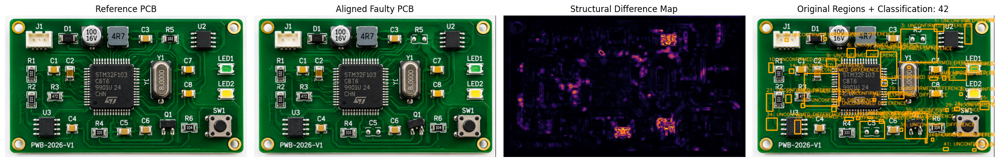


Saved:
/content/EdgeInspect_Defect_Report.csv
/content/EdgeInspect_Classified_PCB.png


In [ ]:

# ================================================================
# EDGEINSPECT - PCB DEFECT DETECTION AND CLASSIFICATION
# Reference PCB vs Faulty PCB
#
# Detection: ORB alignment + SSIM/pixel difference
# Classification: ONLY the original detected regions
#
# Fault types:
#   1. MISSING COMPONENT
#   2. MISPLACED COMPONENT
#   3. UNCONFIRMED DIFFERENCE
# ================================================================

!pip -q install scikit-image opencv-python-headless pandas matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re

from skimage.metrics import structural_similarity
from google.colab import files
from IPython.display import display

# ================================================================
# 1. UPLOAD BOTH IMAGES
# ================================================================

print("Upload BOTH reference and faulty PCB images.")

uploaded = files.upload()

reference_data = None
faulty_data = None

for filename, content in uploaded.items():

    name = filename.lower()

    if "reference" in name:
        reference_data = content

    elif "faulty" in name:
        faulty_data = content

if reference_data is None or faulty_data is None:
    raise ValueError(
        "Both uploaded filenames must contain 'reference' and 'faulty'."
    )

reference_img = cv2.imdecode(
    np.frombuffer(reference_data, np.uint8),
    cv2.IMREAD_COLOR
)

faulty_img = cv2.imdecode(
    np.frombuffer(faulty_data, np.uint8),
    cv2.IMREAD_COLOR
)

if reference_img is None or faulty_img is None:
    raise ValueError("Could not read uploaded images.")

print("Reference:", reference_img.shape)
print("Faulty:", faulty_img.shape)

# ================================================================
# 2. IMAGE ALIGNMENT - ALIGN FAULTY TO REFERENCE
# ================================================================

ref_gray = cv2.cvtColor(reference_img, cv2.COLOR_BGR2GRAY)
faulty_gray = cv2.cvtColor(faulty_img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create(nfeatures=12000)

kp_ref, des_ref = orb.detectAndCompute(ref_gray, None)
kp_faulty, des_faulty = orb.detectAndCompute(faulty_gray, None)

if des_ref is None or des_faulty is None:
    raise RuntimeError("Could not extract enough alignment features.")

matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

matches = matcher.knnMatch(des_faulty, des_ref, k=2)

good_matches = []

for pair in matches:

    if len(pair) == 2:

        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

if len(good_matches) < 8:
    raise RuntimeError(
        "Insufficient alignment matches. Check that both images show the same PCB."
    )

src_pts = np.float32([
    kp_faulty[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

dst_pts = np.float32([
    kp_ref[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

H, inlier_mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    5.0
)

if H is None:
    raise RuntimeError("Image alignment failed.")

inliers = int(inlier_mask.sum())

if inliers < 8:
    raise RuntimeError(
        "Alignment is unreliable: too few RANSAC inliers."
    )

height, width = ref_gray.shape

aligned_faulty_img = cv2.warpPerspective(
    faulty_img,
    H,
    (width, height),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT
)

aligned_gray = cv2.cvtColor(
    aligned_faulty_img,
    cv2.COLOR_BGR2GRAY
)

print("Alignment matches:", len(good_matches))
print("Alignment inliers:", inliers)

# ================================================================
# 3. ORIGINAL STRUCTURAL DIFFERENCE DETECTION
# ================================================================

# This is the ONLY defect-detection stage.

ref_gray = cv2.GaussianBlur(ref_gray, (3, 3), 0)
aligned_gray = cv2.GaussianBlur(aligned_gray, (3, 3), 0)

# Structural similarity difference
_, ssim_map = structural_similarity(
    ref_gray,
    aligned_gray,
    full=True,
    data_range=255
)

ssim_difference = (
    (1.0 - ssim_map) * 255
).astype(np.uint8)

# Pixel difference
pixel_difference = cv2.absdiff(
    ref_gray,
    aligned_gray
)

# Combined structural difference
difference_map = cv2.addWeighted(
    ssim_difference,
    0.65,
    pixel_difference,
    0.35,
    0
)

# Ignore borders affected by image warping
valid_mask = cv2.warpPerspective(
    np.ones_like(ref_gray, dtype=np.uint8) * 255,
    H,
    (width, height),
    flags=cv2.INTER_NEAREST
)

valid_mask = cv2.erode(
    valid_mask,
    np.ones((15, 15), np.uint8),
    iterations=1
)

difference_map[valid_mask == 0] = 0

# Original detection threshold
THRESHOLD = 28

_, binary = cv2.threshold(
    difference_map,
    THRESHOLD,
    255,
    cv2.THRESH_BINARY
)

binary[valid_mask == 0] = 0

# Original morphological filtering
binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    np.ones((3, 3), np.uint8)
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    np.ones((7, 7), np.uint8)
)

# ================================================================
# 4. ORIGINAL REGION LOCALIZATION
# ================================================================

# Connected components are used ONCE here for original detection.
# Classification below will NOT call them again.

count, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )
)

original_regions = []

for i in range(1, count):

    x, y, w, h, area = stats[i]

    if area < 35 or area > 12000:
        continue

    original_regions.append(
        (int(x), int(y), int(w), int(h), int(area))
    )

# Freeze original detector output.
original_regions = tuple(original_regions)

print("\nOriginal detected regions:", len(original_regions))

# ================================================================
# 5. CLASSIFICATION HELPERS
# ================================================================

def crop_region(image, box, padding=1.5):

    x, y, w, h = map(int, box[:4])

    px = max(8, int(w * padding))
    py = max(8, int(h * padding))

    x1 = max(0, x - px)
    y1 = max(0, y - py)
    x2 = min(width, x + w + px)
    y2 = min(height, y + h + py)

    return image[y1:y2, x1:x2], (x1, y1, x2, y2)


def visual_strength(patch):

    if patch is None or patch.size == 0:
        return 0.0

    gx = cv2.Sobel(
        patch, cv2.CV_32F, 1, 0, ksize=3
    )

    gy = cv2.Sobel(
        patch, cv2.CV_32F, 0, 1, ksize=3
    )

    magnitude = cv2.magnitude(gx, gy)

    return float(np.mean(magnitude))


def find_component_elsewhere(
    source_image,
    search_image,
    box,
    exclusion_padding=1.5
):
    """
    Searches for the existing component appearance elsewhere.
    This does not create or add defect regions.
    """

    template, bounds = crop_region(
        source_image,
        box,
        padding=exclusion_padding
    )

    x1, y1, x2, y2 = bounds

    th, tw = template.shape

    if th < 8 or tw < 8:
        return 0.0

    if th >= height or tw >= width:
        return 0.0

    # Search at the same scale.
    result = cv2.matchTemplate(
        search_image,
        template,
        cv2.TM_CCOEFF_NORMED
    )

    # Exclude the original location.
    ex1 = max(0, x1 - tw // 2)
    ey1 = max(0, y1 - th // 2)

    ex2 = min(result.shape[1], x2 - tw // 2)
    ey2 = min(result.shape[0], y2 - th // 2)

    result[ey1:ey2, ex1:ex2] = -1

    score = float(np.max(result))

    if not np.isfinite(score):
        return 0.0

    return score


# ================================================================
# 6. CLASSIFY ONLY ORIGINAL DETECTED REGIONS
# ================================================================

# No thresholding, contour detection, connected components,
# or new defect localization is performed in this section.

classified_regions = []

for index, box in enumerate(original_regions, start=1):

    reference_patch, _ = crop_region(
        ref_gray,
        box
    )

    faulty_patch, _ = crop_region(
        aligned_gray,
        box
    )

    ref_strength = visual_strength(reference_patch)
    faulty_strength = visual_strength(faulty_patch)

    fault_type = "UNCONFIRMED DIFFERENCE"
    match_score = 0.0

    # ------------------------------------------------------------
    # CASE A: Original component location is now empty/different.
    # Search whether that component exists elsewhere in faulty PCB.
    # ------------------------------------------------------------

    if (
        ref_strength > 2.0
        and ref_strength > faulty_strength * 1.25
        and ref_strength - faulty_strength > 3.0
    ):

        match_score = find_component_elsewhere(
            ref_gray,
            aligned_gray,
            box
        )

        if match_score >= 0.78:
            fault_type = "MISPLACED COMPONENT"
        else:
            fault_type = "MISSING COMPONENT"

    # ------------------------------------------------------------
    # CASE B: A component is present here but not at this location
    # in the reference. Check whether it belongs elsewhere.
    # ------------------------------------------------------------

    elif (
        faulty_strength > 2.0
        and faulty_strength > ref_strength * 1.25
        and faulty_strength - ref_strength > 3.0
    ):

        match_score = find_component_elsewhere(
            aligned_gray,
            ref_gray,
            box
        )

        if match_score >= 0.78:
            fault_type = "MISPLACED COMPONENT"
        else:
            fault_type = "UNCONFIRMED DIFFERENCE"

    classified_regions.append({
        "Region": index,
        "Bounding Box": tuple(box[:4]),
        "Area": box[4],
        "Reference Strength": round(ref_strength, 2),
        "Faulty Strength": round(faulty_strength, 2),
        "Elsewhere Match": round(match_score, 3),
        "Fault Type": fault_type
    })


# ================================================================
# 7. DISPLAY ORIGINAL BOXES WITH CLASSIFICATION
# ================================================================

# Only original_regions are drawn.
# No additional boxes are generated.

result_image = aligned_faulty_img.copy()

for item in classified_regions:

    x, y, w, h = item["Bounding Box"]
    fault = item["Fault Type"]

    if fault == "MISSING COMPONENT":
        color = (0, 0, 255)

    elif fault == "MISPLACED COMPONENT":
        color = (255, 0, 255)

    else:
        color = (0, 165, 255)

    cv2.rectangle(
        result_image,
        (x, y),
        (x + w, y + h),
        color,
        2
    )

    cv2.putText(
        result_image,
        f"{item['Region']}: {fault}",
        (x, max(15, y - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.38,
        color,
        1,
        cv2.LINE_AA
    )


# ================================================================
# 8. FINAL REPORT
# ================================================================

report = pd.DataFrame(classified_regions)

missing_count = sum(
    x["Fault Type"] == "MISSING COMPONENT"
    for x in classified_regions
)

misplaced_count = sum(
    x["Fault Type"] == "MISPLACED COMPONENT"
    for x in classified_regions
)

unconfirmed_count = sum(
    x["Fault Type"] == "UNCONFIRMED DIFFERENCE"
    for x in classified_regions
)

print("\n================ EDGEINSPECT REPORT ================")

print("Original detected regions:", len(original_regions))
print("Missing components:", missing_count)
print("Misplaced components:", misplaced_count)
print("Unconfirmed differences:", unconfirmed_count)

print("=====================================================")

display(report)

# ================================================================
# 9. VISUALIZATION
# ================================================================

plt.figure(figsize=(20, 6))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(reference_img, cv2.COLOR_BGR2RGB))
plt.title("Reference PCB")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(aligned_faulty_img, cv2.COLOR_BGR2RGB))
plt.title("Aligned Faulty PCB")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(difference_map, cmap="inferno")
plt.title("Structural Difference Map")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title(
    f"Original Regions + Classification: {len(original_regions)}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the final report and classified image.
report.to_csv(
    "/content/EdgeInspect_Defect_Report.csv",
    index=False
)

cv2.imwrite(
    "/content/EdgeInspect_Classified_PCB.png",
    result_image
)

print("\nSaved:")
print("/content/EdgeInspect_Defect_Report.csv")
print("/content/EdgeInspect_Classified_PCB.png")


Upload reference PCB and faulty PCB images


Saving faulty1.png to faulty1 (1).png
Saving reference1.png to reference1 (1).png
Reference: (351, 600, 3)
Faulty: (351, 600, 3)
Alignment matches: 3507
Alignment inliers: 3383

Original detected regions: 54


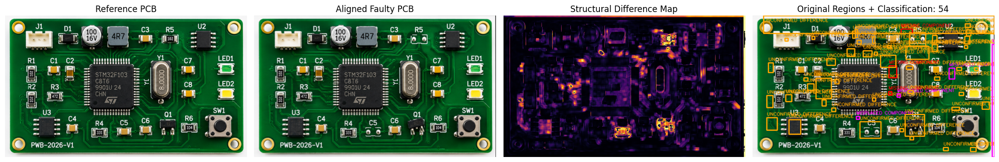


========== EDGEINSPECT REPORT ==========
Original detected regions: 54
Missing component regions: 3
Misplaced component regions: 4
Unconfirmed differences: 47

Region-wise classification:
Region 1: UNCONFIRMED DIFFERENCE | Coordinates: (540, 327, 14, 10)
Region 2: UNCONFIRMED DIFFERENCE | Coordinates: (473, 327, 12, 8)
Region 3: UNCONFIRMED DIFFERENCE | Coordinates: (390, 300, 9, 8)
Region 4: UNCONFIRMED DIFFERENCE | Coordinates: (365, 280, 9, 8)
Region 5: UNCONFIRMED DIFFERENCE | Coordinates: (266, 263, 52, 41)
Region 6: UNCONFIRMED DIFFERENCE | Coordinates: (90, 258, 29, 36)
Region 7: UNCONFIRMED DIFFERENCE | Coordinates: (35, 253, 26, 31)
Region 8: MISPLACED COMPONENT | Coordinates: (257, 250, 8, 7)
Region 9: UNCONFIRMED DIFFERENCE | Coordinates: (378, 245, 48, 54)
Region 10: UNCONFIRMED DIFFERENCE | Coordinates: (196, 229, 10, 9)
Region 11: UNCONFIRMED DIFFERENCE | Coordinates: (494, 227, 19, 8)
Region 12: UNCONFIRMED DIFFERENCE | Coordinates: (569, 214, 18, 18)
Region 13: UNCONFI

In [ ]:
# ============================================================
# EDGEINSPECT - PCB DEFECT DETECTION AND CLASSIFICATION
# 1. Align reference and faulty PCB
# 2. Detect structural difference regions ONCE
# 3. Classify existing regions:
#       MISSING COMPONENT
#       MISPLACED COMPONENT
# 4. Display original detected regions with labels
# ============================================================

!pip -q install opencv-python-headless scikit-image scipy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import files
from skimage.metrics import structural_similarity
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

# ------------------------------------------------------------
# 1. UPLOAD IMAGES
# ------------------------------------------------------------

print("Upload reference PCB and faulty PCB images")

uploaded = files.upload()

reference_path = None
faulty_path = None

for name in uploaded.keys():
    lower = name.lower()

    if "reference" in lower:
        reference_path = name
    elif "faulty" in lower:
        faulty_path = name

if reference_path is None or faulty_path is None:
    raise FileNotFoundError(
        "Upload two images with 'reference' and 'faulty' "
        "in their filenames."
    )

reference_img = cv2.imread(reference_path)
faulty_img = cv2.imread(faulty_path)

if reference_img is None or faulty_img is None:
    raise ValueError("Could not read uploaded images.")

print("Reference:", reference_img.shape)
print("Faulty:", faulty_img.shape)


# ------------------------------------------------------------
# 2. IMAGE ALIGNMENT
# ------------------------------------------------------------

def align_pcb(reference, faulty):

    ref_gray = cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY)
    fault_gray = cv2.cvtColor(faulty, cv2.COLOR_BGR2GRAY)

    # Resize faulty image to reference dimensions for registration
    fault_resized = cv2.resize(
        faulty,
        (reference.shape[1], reference.shape[0])
    )

    fault_gray = cv2.cvtColor(
        fault_resized, cv2.COLOR_BGR2GRAY
    )

    orb = cv2.ORB_create(nfeatures=10000)

    kp1, des1 = orb.detectAndCompute(ref_gray, None)
    kp2, des2 = orb.detectAndCompute(fault_gray, None)

    if des1 is None or des2 is None:
        raise RuntimeError("Unable to extract alignment features.")

    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

    matches = matcher.knnMatch(des1, des2, k=2)

    good = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    print("Alignment matches:", len(good))

    if len(good) < 8:
        raise RuntimeError(
            "Insufficient alignment matches. "
            "Use images of the same PCB with visible common features."
        )

    src = np.float32([
        kp2[m.trainIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    dst = np.float32([
        kp1[m.queryIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        src, dst,
        cv2.RANSAC,
        4.0
    )

    if H is None:
        raise RuntimeError("PCB alignment failed.")

    inliers = int(mask.sum())

    print("Alignment inliers:", inliers)

    if inliers < 12:
        raise RuntimeError(
            "Alignment is unreliable. Check image quality and PCB overlap."
        )

    aligned = cv2.warpPerspective(
        fault_resized,
        H,
        (reference.shape[1], reference.shape[0])
    )

    return aligned


aligned_faulty_img = align_pcb(
    reference_img,
    faulty_img
)


# ------------------------------------------------------------
# 3. ORIGINAL STRUCTURAL DIFFERENCE DETECTION
#    This is the ONLY defect detection pass.
# ------------------------------------------------------------

ref_gray = cv2.cvtColor(
    reference_img, cv2.COLOR_BGR2GRAY
)

fault_gray = cv2.cvtColor(
    aligned_faulty_img, cv2.COLOR_BGR2GRAY
)

# SSIM structural difference
_, ssim_map = structural_similarity(
    ref_gray,
    fault_gray,
    full=True,
    data_range=255
)

difference = ((1 - ssim_map) * 255).astype(np.uint8)

# Original thresholding stage
difference_blur = cv2.GaussianBlur(
    difference, (5, 5), 0
)

_, difference_mask = cv2.threshold(
    difference_blur,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove tiny noise without expanding regions
kernel = np.ones((3, 3), np.uint8)

difference_mask = cv2.morphologyEx(
    difference_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Find original detected regions ONCE
contours, _ = cv2.findContours(
    difference_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

original_regions = []

MIN_AREA = 35
MAX_AREA = 12000

for contour in contours:

    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)

    if MIN_AREA <= area <= MAX_AREA:

        original_regions.append(
            (x, y, w, h)
        )

print("\nOriginal detected regions:", len(original_regions))


# ------------------------------------------------------------
# 4. CLASSIFICATION FEATURES
#    These functions inspect existing regions only.
#    They do NOT detect or create new regions.
# ------------------------------------------------------------

def crop_patch(image, box, padding=5):

    x, y, w, h = box

    x1 = max(0, x - padding)
    y1 = max(0, y - padding)

    x2 = min(image.shape[1], x + w + padding)
    y2 = min(image.shape[0], y + h + padding)

    return image[y1:y2, x1:x2]


def texture_score(patch):

    gray = cv2.cvtColor(
        patch, cv2.COLOR_BGR2GRAY
    )

    edges = cv2.Canny(gray, 45, 120)

    return np.mean(edges > 0)


def occupancy_score(patch):

    gray = cv2.cvtColor(
        patch, cv2.COLOR_BGR2GRAY
    )

    # Local contrast and edge density
    laplacian = cv2.Laplacian(
        gray, cv2.CV_64F
    )

    contrast = np.std(gray)
    edge_density = np.mean(
        cv2.Canny(gray, 45, 120) > 0
    )

    return (
        0.5 * contrast +
        100 * edge_density +
        0.1 * np.mean(np.abs(laplacian))
    )


# ------------------------------------------------------------
# 5. CLASSIFY EACH EXISTING REGION
# ------------------------------------------------------------

region_data = []

for index, box in enumerate(original_regions):

    ref_patch = crop_patch(
        reference_img, box
    )

    fault_patch = crop_patch(
        aligned_faulty_img, box
    )

    ref_score = occupancy_score(ref_patch)
    fault_score = occupancy_score(fault_patch)

    region_data.append({
        "index": index,
        "box": box,
        "ref_score": ref_score,
        "fault_score": fault_score,
        "difference": ref_score - fault_score
    })


# ------------------------------------------------------------
# 6. IDENTIFY ABSENCE AND PRESENCE CHANGES
#
# A region where the reference has stronger component
# structure is a possible missing-component location.
#
# A region where the faulty PCB has stronger structure
# is a possible displaced-component location.
#
# These are classifications of original_regions only.
# ------------------------------------------------------------

missing_candidates = []
extra_candidates = []

for item in region_data:

    delta = item["difference"]

    # Require a meaningful contrast difference
    if delta > 8:
        missing_candidates.append(item)

    elif delta < -8:
        extra_candidates.append(item)


# ------------------------------------------------------------
# 7. MATCH MISSING AND DISPLACED COMPONENTS
#
# Match only the already-detected regions.
# A pair is classified as MISPLACED COMPONENT.
# ------------------------------------------------------------

def component_signature(image, box):

    patch = crop_patch(image, box, padding=8)

    patch = cv2.resize(
        patch, (64, 64)
    )

    gray = cv2.cvtColor(
        patch, cv2.COLOR_BGR2GRAY
    )

    # Normalize to reduce lighting variation
    gray = cv2.equalizeHist(gray)

    return gray.flatten().astype(np.float32)


matches = []

if missing_candidates and extra_candidates:

    missing_signatures = [
        component_signature(
            reference_img, item["box"]
        )
        for item in missing_candidates
    ]

    extra_signatures = [
        component_signature(
            aligned_faulty_img, item["box"]
        )
        for item in extra_candidates
    ]

    cost = cdist(
        np.array(missing_signatures),
        np.array(extra_signatures),
        metric="cosine"
    )

    rows, cols = linear_sum_assignment(cost)

    for r, c in zip(rows, cols):

        similarity = 1 - cost[r, c]

        # Conservative matching threshold
        if similarity >= 0.75:

            matches.append((
                missing_candidates[r]["index"],
                extra_candidates[c]["index"]
            ))


# ------------------------------------------------------------
# 8. ASSIGN FINAL LABELS
# ------------------------------------------------------------

labels = {
    item["index"]: "UNCONFIRMED DIFFERENCE"
    for item in region_data
}

for missing_index, extra_index in matches:

    labels[missing_index] = "MISPLACED COMPONENT"
    labels[extra_index] = "MISPLACED COMPONENT"


for item in missing_candidates:

    idx = item["index"]

    if labels[idx] == "UNCONFIRMED DIFFERENCE":
        labels[idx] = "MISSING COMPONENT"


# ------------------------------------------------------------
# 9. DISPLAY
#
# Draw ONLY the original detected regions.
# No additional boxes are generated during classification.
# ------------------------------------------------------------

display_img = aligned_faulty_img.copy()

for item in region_data:

    idx = item["index"]
    x, y, w, h = item["box"]

    label = labels[idx]

    if label == "MISSING COMPONENT":
        color = (0, 0, 255)

    elif label == "MISPLACED COMPONENT":
        color = (255, 0, 255)

    else:
        color = (0, 165, 255)

    # Original detection coordinates only
    cv2.rectangle(
        display_img,
        (x, y),
        (x + w, y + h),
        color,
        2
    )

    cv2.putText(
        display_img,
        label,
        (x, max(15, y - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.38,
        color,
        1,
        cv2.LINE_AA
    )


# ------------------------------------------------------------
# 10. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(20, 6))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(
    reference_img, cv2.COLOR_BGR2RGB
))
plt.title("Reference PCB")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(
    aligned_faulty_img, cv2.COLOR_BGR2RGB
))
plt.title("Aligned Faulty PCB")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(difference, cmap="inferno")
plt.title("Structural Difference Map")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(
    display_img, cv2.COLOR_BGR2RGB
))
plt.title(
    f"Original Regions + Classification: {len(original_regions)}"
)
plt.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

missing_count = sum(
    1 for value in labels.values()
    if value == "MISSING COMPONENT"
)

misplaced_count = sum(
    1 for value in labels.values()
    if value == "MISPLACED COMPONENT"
)

unconfirmed_count = sum(
    1 for value in labels.values()
    if value == "UNCONFIRMED DIFFERENCE"
)

print("\n========== EDGEINSPECT REPORT ==========")

print("Original detected regions:", len(original_regions))
print("Missing component regions:", missing_count)
print("Misplaced component regions:", misplaced_count)
print("Unconfirmed differences:", unconfirmed_count)

print("\nRegion-wise classification:")

for idx, box in enumerate(original_regions):

    print(
        f"Region {idx + 1}: "
        f"{labels[idx]} | "
        f"Coordinates: {box}"
    )

print("\n========================================")

Upload the REFERENCE (good) PCB image first, then the TEST (faulty) PCB image.


Saving faulty1.png to faulty1 (2).png
Saving reference1.png to reference1 (2).png
Alignment: 1601 good feature matches
ECC refinement applied (cc=0.987)
Changed regions found: 2

================ DEFECT REPORT ================
1. WRONG / MISPLACED COMPONENT (different part here) | expected at (x=920, y=118, w=74, h=50)
2. WRONG / MISPLACED COMPONENT (different part here) | expected at (x=649, y=650, w=83, h=53)

Reference image


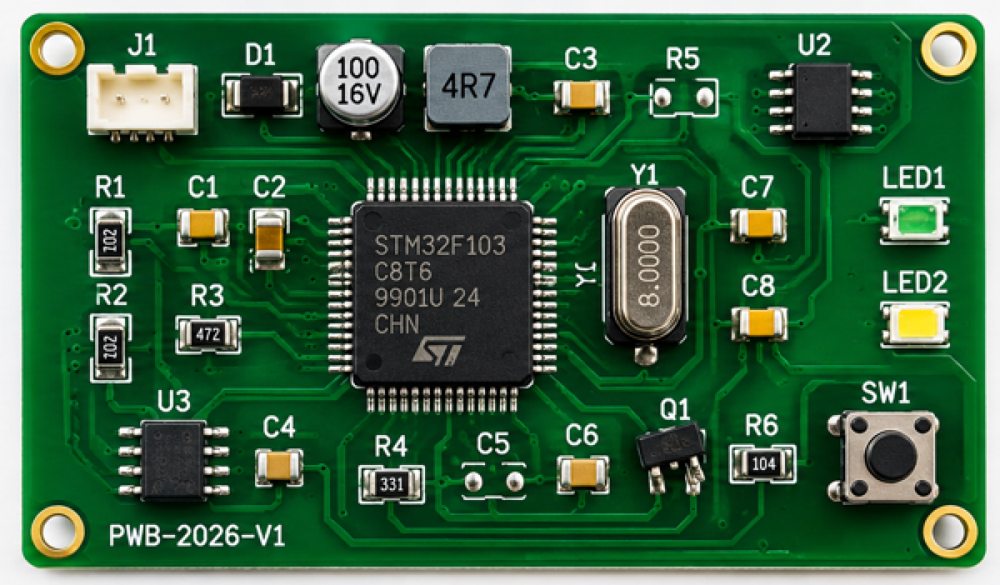

Aligned test image


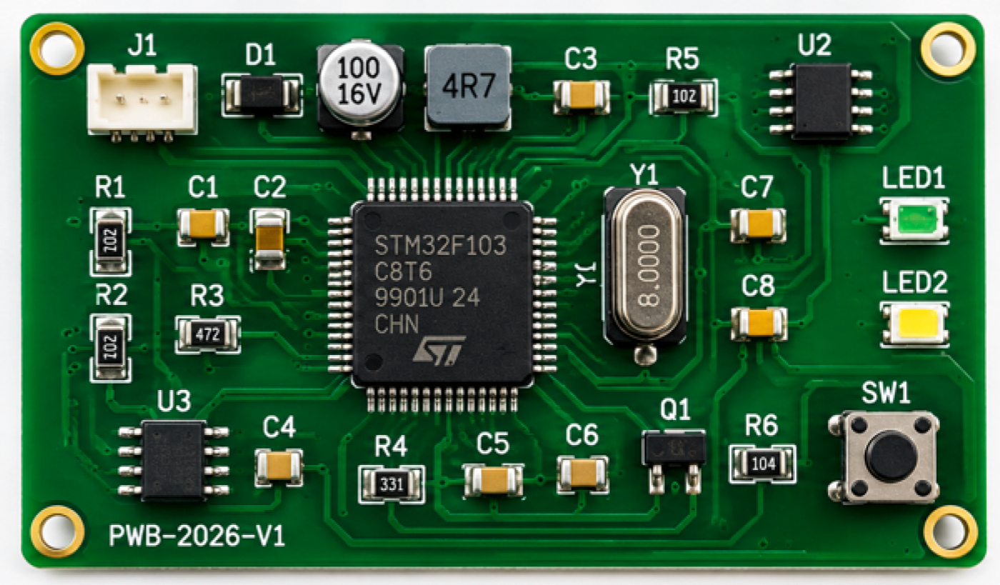

Difference map


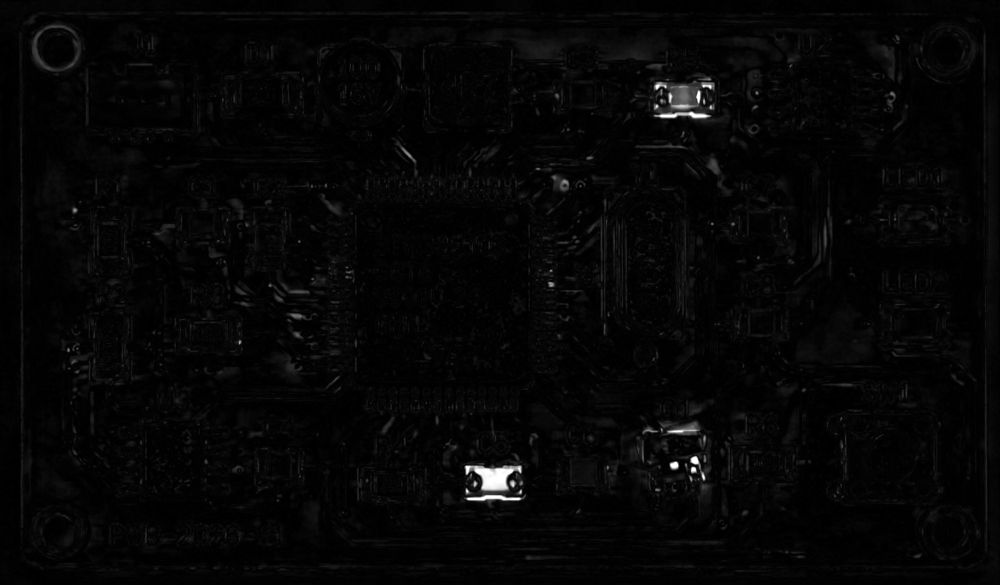

Detected defects


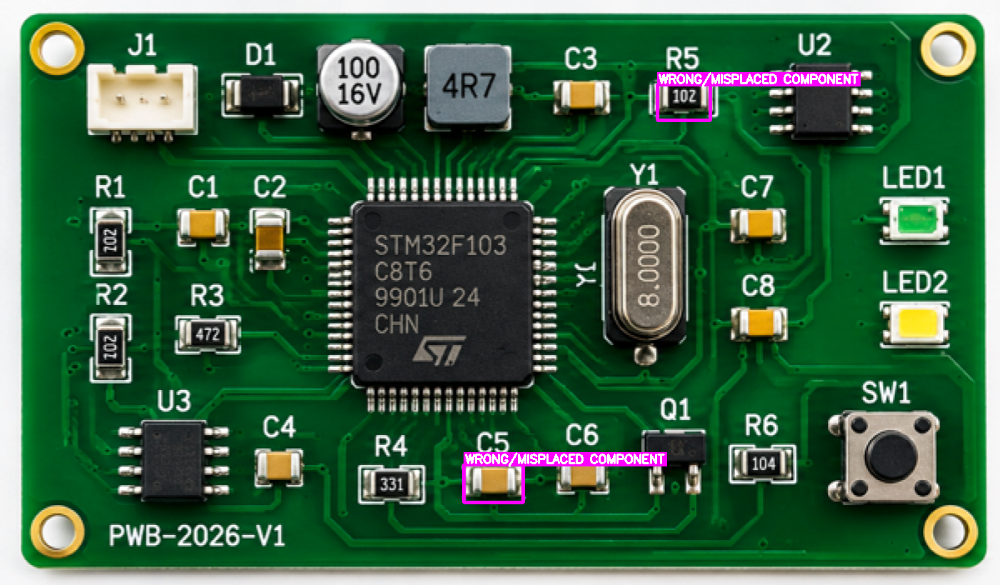

Saved: result.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  (Reference-image method)
#  Works in Google Colab: paste into ONE cell and run.
#
#  Steps:
#   1. Upload reference (good) PCB image and test (faulty) PCB image
#   2. Align test image to reference (SIFT + RANSAC homography + ECC refine)
#   3. Normalise lighting/colour, compute difference map
#   4. Find changed regions
#   5. For every changed region compare "component presence" in ref vs test
#        - ref has component, test empty           -> MISSING (unless found elsewhere)
#        - ref has component, test has another one -> WRONG component
#        - ref empty, test has component           -> EXTRA (new place of a moved part)
#   6. Template-match the reference component inside the test image:
#        found at a different place  -> MISPLACED  (original pos + new pos linked)
#        not found anywhere          -> MISSING
# =====================================================================
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
WORK_WIDTH      = 1400    # both images are resized to this width
MIN_AREA_RATIO  = 0.0003  # smallest defect area = ratio * image area (smaller = more sensitive)
DIFF_FLOOR      = 40      # minimum colour difference (0-255) to count as "different"
SHIFT_TOL       = 2       # pixels of residual misalignment tolerated
PRESENT_THRESH  = 0.05    # edge density above this => "a component is here"
MATCH_THRESH    = 0.60    # template match score to say "same component found elsewhere"
MOVE_MIN_DIST   = 10      # min pixel distance to call it moved
MERGE_PAD       = 12      # boxes closer than this are merged into one defect
# ---------------------------------------------------------------------


def upload_two_images():
    print("Upload the REFERENCE (good) PCB image first, then the TEST (faulty) PCB image.")
    up = files.upload()
    names = list(up.keys())
    if len(names) >= 2:
        return names[0], names[1]
    print("Now upload the TEST (faulty) image...")
    up2 = files.upload()
    return names[0], list(up2.keys())[0]


def resize_to_width(img, width):
    h, w = img.shape[:2]
    s = width / float(w)
    return cv2.resize(img, (width, int(h * s)), interpolation=cv2.INTER_AREA)


# ----------------------------- ALIGNMENT -----------------------------
def align_images(ref, test):
    """Warp `test` so it overlays `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)

    try:
        det = cv2.SIFT_create(6000)
        norm = cv2.NORM_L2
        ratio = 0.75
    except Exception:
        det = cv2.ORB_create(6000)
        norm = cv2.NORM_HAMMING
        ratio = 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is None or d2 is None or len(k1) < 10 or len(k2) < 10:
        print("[!] Not enough features for alignment, using image as-is.")
        return test

    matches = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
    good = [m for m, n in (p for p in matches if len(p) == 2) if m.distance < ratio * n.distance]
    print(f"Alignment: {len(good)} good feature matches")
    if len(good) < 10:
        print("[!] Too few matches, using image as-is.")
        return test

    src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 4.0)
    if H is None:
        print("[!] Homography failed, using image as-is.")
        return test
    aligned = cv2.warpPerspective(test, H, (ref.shape[1], ref.shape[0]),
                                  flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    # fine refinement with ECC (only kept if it improves correlation)
    try:
        a_g = cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY)
        a_b = cv2.GaussianBlur(a_g, (5, 5), 0).astype(np.float32)
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 100, 1e-6)
        cc, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (ref.shape[1], ref.shape[0]),
                                 flags=cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        print(f"ECC refinement applied (cc={cc:.3f})")
        return refined
    except cv2.error:
        return aligned


# ----------------------- PRE-PROCESS & DIFFERENCE --------------------
def match_colour(ref, test):
    """Match global LAB mean/std of test to ref (handles lighting changes)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        rm, rs = r[..., c].mean(), r[..., c].std() + 1e-6
        tm, ts = t[..., c].mean(), t[..., c].std() + 1e-6
        t[..., c] = (t[..., c] - tm) * (rs / ts) + rm
    t = np.clip(t, 0, 255).astype(np.uint8)
    return cv2.cvtColor(t, cv2.COLOR_LAB2BGR)


def difference_map(ref, test):
    r = cv2.cvtColor(cv2.GaussianBlur(ref, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(cv2.GaussianBlur(test, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(np.float32)

    # tolerate tiny residual misalignment: take minimum diff over small shifts
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            sh = np.roll(np.roll(t, dy, axis=0), dx, axis=1)
            d = np.linalg.norm(r - sh, axis=2)
            best = d if best is None else np.minimum(best, d)
    d8 = np.clip(best * 2.0, 0, 255).astype(np.uint8)

    otsu, _ = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thr = max(otsu, DIFF_FLOOR)
    mask = (d8 > thr).astype(np.uint8) * 255

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    mask = cv2.dilate(mask, k, iterations=1)
    return d8, mask


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        while boxes:
            x, y, w, h = boxes.pop()
            merged = False
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2] = max(x + w, ox + ow) - nx
                    o[3] = max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    merged = True
                    changed = True
                    break
            if not merged:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


def find_regions(mask, shape):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_area = MIN_AREA_RATIO * shape[0] * shape[1]
    boxes = [cv2.boundingRect(c) for c in cnts if cv2.contourArea(c) >= min_area]
    return merge_boxes(boxes, MERGE_PAD)


# ------------------------ COMPONENT PRESENCE -------------------------
def edge_density(gray_patch):
    if gray_patch.size == 0:
        return 0.0
    e = cv2.Canny(gray_patch, 60, 160)
    return float(e.mean()) / 255.0


def crop(img, box, pad=0):
    x, y, w, h = box
    H, W = img.shape[:2]
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(W, x + w + pad), min(H, y + h + pad)
    return img[y0:y1, x0:x1], (x0, y0, x1 - x0, y1 - y0)


def find_elsewhere(ref_patch, test_gray, orig_box):
    """Search for the reference component anywhere else in the test image (4 rotations)."""
    ph, pw = ref_patch.shape[:2]
    if ph < 8 or pw < 8 or ph >= test_gray.shape[0] or pw >= test_gray.shape[1]:
        return 0.0, None
    ox, oy, ow, oh = orig_box
    best_score, best_loc = -1.0, None
    for rot in range(4):
        tpl = np.ascontiguousarray(np.rot90(ref_patch, rot))
        th, tw = tpl.shape[:2]
        if th >= test_gray.shape[0] or tw >= test_gray.shape[1]:
            continue
        res = cv2.matchTemplate(test_gray, tpl, cv2.TM_CCOEFF_NORMED)
        # ignore the original location
        y0, y1 = max(0, oy - th), min(res.shape[0], oy + oh + th)
        x0, x1 = max(0, ox - tw), min(res.shape[1], ox + ow + tw)
        res[y0:y1, x0:x1] = -1
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best_score:
            best_score, best_loc = mx, (loc[0], loc[1], tw, th)
    return best_score, best_loc


def iou_overlap(a, b):
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / float(min(aw * ah, bw * bh) + 1e-6)


# ----------------------------- CLASSIFY ------------------------------
def classify(ref, test, regions):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)

    candidates = []   # (kind, box, ref_density, test_density)
    for box in regions:
        rp, _ = crop(g_ref, box)
        tp, _ = crop(g_tst, box)
        rd, td = edge_density(rp), edge_density(tp)
        ref_has = rd >= PRESENT_THRESH
        tst_has = td >= PRESENT_THRESH
        if ref_has and not tst_has:
            kind = "missing"
        elif tst_has and not ref_has:
            kind = "extra"
        elif ref_has and tst_has:
            kind = "wrong"
        else:
            continue   # texture-only difference (stain / reflection), ignore
        candidates.append({"kind": kind, "box": box, "rd": rd, "td": td})

    defects = []
    used_extra = set()

    for c in candidates:
        if c["kind"] not in ("missing", "wrong"):
            continue
        ref_patch, pbox = crop(g_ref, c["box"], pad=3)
        score, loc = find_elsewhere(ref_patch, g_tst, pbox)
        moved = (loc is not None and score >= MATCH_THRESH and
                 np.hypot(loc[0] - pbox[0], loc[1] - pbox[1]) > MOVE_MIN_DIST)
        if moved:
            defects.append({"type": "MISPLACED COMPONENT",
                            "orig_box": c["box"], "new_box": loc, "score": score})
            for i, e in enumerate(candidates):
                if e["kind"] == "extra" and iou_overlap(e["box"], loc) > 0.3:
                    used_extra.add(i)
        elif c["kind"] == "missing":
            defects.append({"type": "MISSING COMPONENT", "orig_box": c["box"],
                            "new_box": None, "score": score})
        else:
            defects.append({"type": "WRONG / MISPLACED COMPONENT (different part here)",
                            "orig_box": c["box"], "new_box": None, "score": score})

    for i, c in enumerate(candidates):
        if c["kind"] == "extra" and i not in used_extra:
            already = any(d["new_box"] is not None and iou_overlap(d["new_box"], c["box"]) > 0.3
                          for d in defects)
            if not already:
                defects.append({"type": "EXTRA / MISPLACED COMPONENT (unexpected part)",
                                "orig_box": None, "new_box": c["box"], "score": 0.0})
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (0, 0, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def label(img, text, org, color):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
    x, y = org
    y = max(th + 4, y)
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + 2), color, -1)
    cv2.putText(img, text, (x + 2, y - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)


def draw_results(test_aligned, defects):
    out = test_aligned.copy()
    for d in defects:
        t = d["type"]
        if t.startswith("MISSING"):
            x, y, w, h = d["orig_box"]
            cv2.rectangle(out, (x, y), (x + w, y + h), RED, 3)
            label(out, "MISSING COMPONENT", (x, y), RED)
        elif t.startswith("MISPLACED"):
            x, y, w, h = d["orig_box"]
            nx, ny, nw, nh = d["new_box"]
            cv2.rectangle(out, (x, y), (x + w, y + h), ORANGE, 3)
            label(out, "MISPLACED (should be here)", (x, y), ORANGE)
            cv2.rectangle(out, (nx, ny), (nx + nw, ny + nh), BLUE, 3)
            label(out, "MISPLACED (found here)", (nx, ny), BLUE)
            cv2.arrowedLine(out, (nx + nw // 2, ny + nh // 2), (x + w // 2, y + h // 2),
                            MAGENTA, 2, tipLength=0.05)
        elif t.startswith("WRONG"):
            x, y, w, h = d["orig_box"]
            cv2.rectangle(out, (x, y), (x + w, y + h), MAGENTA, 3)
            label(out, "WRONG/MISPLACED COMPONENT", (x, y), MAGENTA)
        else:
            x, y, w, h = d["new_box"]
            cv2.rectangle(out, (x, y), (x + w, y + h), BLUE, 3)
            label(out, "EXTRA COMPONENT", (x, y), BLUE)
    return out


def show(title, img):
    print(title)
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imshow(title, img)
        cv2.waitKey(0)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, save_path="result.png"):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")

    ref = resize_to_width(ref, WORK_WIDTH)
    test = resize_to_width(test, WORK_WIDTH)

    aligned = align_images(ref, test)
    aligned = match_colour(ref, aligned)

    diff8, mask = difference_map(ref, aligned)
    regions = find_regions(mask, ref.shape)
    print(f"Changed regions found: {len(regions)}")

    defects = classify(ref, aligned, regions)
    result = draw_results(aligned, defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        line = f"{i}. {d['type']}"
        if d["orig_box"] is not None:
            x, y, w, h = d["orig_box"]
            line += f" | expected at (x={x}, y={y}, w={w}, h={h})"
        if d["new_box"] is not None:
            x, y, w, h = d["new_box"]
            line += f" | found at (x={x}, y={y}, w={w}, h={h})"
        print(line)
    print("===============================================\n")

    show("Reference image", ref)
    show("Aligned test image", aligned)
    show("Difference map", diff8)
    show("Detected defects", result)

    cv2.imwrite(save_path, result)
    print(f"Saved: {save_path}")
    if IN_COLAB:
        files.download(save_path)
    return defects


if __name__ == "__main__" or IN_COLAB:
    if IN_COLAB:
        ref_name, test_name = upload_two_images()
    else:
        import sys
        ref_name, test_name = sys.argv[1], sys.argv[2]
    run(ref_name, test_name)

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v2 (SSIM structural diff)
#  Google Colab: paste this whole file into ONE cell and run it.
#  Needs only OpenCV + NumPy (both are pre-installed in Colab).
#
#  Pipeline
#   1. Upload REFERENCE (good board) and TEST (faulty board) separately
#   2. Align TEST onto REFERENCE  (SIFT + RANSAC homography, ECC refine)
#   3. Normalise brightness / colour
#   4. STRUCTURAL difference map  = 1 - SSIM  (L, a, b channels, shift tolerant)
#   5. Cluster the changed pixels into candidate defect regions
#   6. For each region compare "component occupancy" (non-board pixels)
#        reference has part, test is bare   -> MISSING candidate
#        reference is bare, test has part   -> EXTRA   candidate
#        both have parts but look different -> DISPLACED (shifted / rotated /
#                                              wrong part)
#   7. Pair MISSING + EXTRA: if the part that vanished from place A shows up
#      at place B  ->  MISPLACED COMPONENT (A = expected, B = actual).
#      Unpaired MISSING -> MISSING COMPONENT.
#      DISPLACED        -> MISPLACED COMPONENT (shifted / rotated in place).
# =====================================================================
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MERGE_DIST      = 0.020   # blobs closer than this (fraction of image width) form one region
MIN_MASS        = 0.0016  # min total difference of a region (fraction of image area)
MIN_DENSITY     = 0.18    # min fraction of a region's box that must be "different"
BLOB_KEEP       = 0.25    # inside a region, ignore blobs smaller than this x the biggest blob
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "missing part reappeared elsewhere"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_two_images():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    up = files.upload()
    ref_name = list(up.keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    up = files.upload()
    test_name = list(up.keys())[0]
    print(f"\nReference = {ref_name}\nTest      = {test_name}")
    return ref_name, test_name


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    ok = d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10
    if ok:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            H, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if H is not None:
                aligned = cv2.warpPerspective(test, H, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    # fine ECC refinement, kept only if it really improves the match
    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        cc, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(ref_ch, tst_ch, ref_stats=None):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    a, b = ref_ch, tst_ch
    if ref_stats is None:
        mu_a = _blur(a); saa = _blur(a * a) - mu_a ** 2
    else:
        mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Return diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))

    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)   # best-case alignment
    return np.clip(1.0 - best, 0.0, 1.0)


# --------------------------- REGION FINDING --------------------------
def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


def find_regions(diff):
    H, W = diff.shape
    mask = (diff > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))

    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]      # drop weak satellites
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        box = (x0, y0, x1 - x0, y1 - y0)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((diff[y0:y1, x0:x1] * sub).sum())
        density = float(sub.mean())
        if mass >= MIN_MASS * W * H and density >= MIN_DENSITY:
            regions.append({"box": box, "mass": mass, "density": density})
    return mask, regions


# ----------------------- COMPONENT OCCUPANCY -------------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (x0, y0, x1 - x0, y1 - y0)


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def centre_dist(a, b):
    return float(np.hypot(a[0] + a[2] / 2 - b[0] - b[2] / 2, a[1] + a[3] / 2 - b[1] - b[3] / 2))


# --------------------------- POSE / PAIRING --------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    diag = int(np.ceil(np.hypot(h, w)))
    canvas = cv2.copyMakeBorder(patch, (diag - h) // 2 + 1, (diag - h) // 2 + 1,
                                (diag - w) // 2 + 1, (diag - w) // 2 + 1, cv2.BORDER_REPLICATE)
    M = cv2.getRotationMatrix2D((canvas.shape[1] / 2, canvas.shape[0] / 2), angle, 1.0)
    rot = cv2.warpAffine(canvas, M, (canvas.shape[1], canvas.shape[0]),
                         flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    # crop back to roughly the original size (centre)
    cy, cx = rot.shape[0] // 2, rot.shape[1] // 2
    y0, x0 = max(0, cy - h // 2), max(0, cx - w // 2)
    return rot[y0:y0 + h, x0:x0 + w]


def best_match(template, search_img, search_box, angles):
    """Find `template` inside search_img[search_box] (any of `angles`).
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang) if ang else template
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


# ----------------------------- CLASSIFY ------------------------------
def classify(ref, test, regions):
    shape = ref.shape
    W = shape[1]
    model = board_model(ref)
    if model is None:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    cands = []
    for r in regions:
        box = r["box"]
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        top = max(o_ref, o_tst, 0.05)
        if o_ref - o_tst > OCC_DELTA or (o_ref - o_tst > 0.05 and (o_ref - o_tst) / top > 0.35):
            kind = "missing"
        elif o_tst - o_ref > OCC_DELTA or (o_tst - o_ref > 0.05 and (o_tst - o_ref) / top > 0.35):
            kind = "extra"
        elif max(o_ref, o_tst) > 0.2:
            kind = "displaced"
        else:
            continue            # only a faint texture change on bare board -> ignore
        cands.append({"kind": kind, "box": box, "o_ref": o_ref, "o_tst": o_tst, "mass": r["mass"]})

    defects, used = [], set()
    angles = (0, 90, 180, 270)

    # ---- pair every MISSING part with an EXTRA part that looks the same ----
    for i, m in enumerate(cands):
        if m["kind"] != "missing":
            continue
        tpl_box = expand(m["box"], 2, shape)
        tpl = crop(ref, tpl_box)
        best = None
        for j, e in enumerate(cands):
            if e["kind"] != "extra" or j in used:
                continue
            pad = max(tpl_box[2], tpl_box[3]) // 2 + 4
            sbox = expand(e["box"], pad, shape)
            score, loc, ang = best_match(tpl, test, sbox, angles)
            if loc is not None and score >= PAIR_THRESH and (best is None or score > best[0]):
                best = (score, loc, ang, j)
        if best is not None:
            score, loc, ang, j = best
            used.add(j)
            defects.append({"type": "MISPLACED COMPONENT", "orig_box": m["box"], "new_box": loc,
                            "detail": f"moved to another place (match {score:.2f}, rot {ang} deg)"})
        else:
            defects.append({"type": "MISSING COMPONENT", "orig_box": m["box"], "new_box": None,
                            "detail": "pads/area bare in test image"})

        # ---- part still there, but position / orientation / type differs ----
    for c in cands:
        if c["kind"] != "displaced":
            continue
        defects.append({"type": "MISPLACED COMPONENT", "orig_box": expand(c["box"], 3, shape), "new_box": None,
                        "detail": "a part is present but its position / orientation / type differs from the reference"})

    # ---- extra parts that no missing part explains ----
    for j, e in enumerate(cands):
        if e["kind"] == "extra" and j not in used:
            defects.append({"type": "EXTRA COMPONENT", "orig_box": None, "new_box": e["box"],
                            "detail": "part present in test but not in reference"})
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def put_label(img, text, box, color, scale):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    ty = y - 6 if y - th - 10 > 0 else y + h + th + 8
    tx = min(max(0, x), img.shape[1] - tw - 6)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    s = lambda b: tuple(int(v * upscale) for v in b)

    def rect(b, col):
        x, y, w, h = s(b)
        pad = lw
        cv2.rectangle(out, (x - pad, y - pad), (x + w + pad, y + h + pad), col, lw, cv2.LINE_AA)
        return (x - pad, y - pad, w + 2 * pad, h + 2 * pad)

    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            b = rect(d["orig_box"], RED)
            put_label(out, f"#{i} MISSING COMPONENT", b, RED, sc)
        elif t == "MISPLACED COMPONENT" and d["new_box"] is not None:
            b1 = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED - expected here", b1, ORANGE, sc)
            b2 = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} MISPLACED - found here", b2, BLUE, sc)
            c1 = (b1[0] + b1[2] // 2, b1[1] + b1[3] // 2)
            c2 = (b2[0] + b2[2] // 2, b2[1] + b2[3] // 2)
            cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
        elif t == "MISPLACED COMPONENT":
            b = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED COMPONENT", b, ORANGE, sc)
        else:
            b = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} EXTRA COMPONENT", b, BLUE, sc)
    return out


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = align_images(ref, test)
    aligned = normalise_photometry(ref, aligned)

    diff = structural_difference(ref, aligned)
    mask, regions = find_regions(diff)
    print(f"Candidate regions after SSIM filtering: {len(regions)}")

    defects = classify(ref, aligned, regions)
    result = draw_results(aligned, defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        line = f"#{i} {d['type']}  -  {d['detail']}"
        if d["orig_box"] is not None:
            line += f"\n     expected at x,y,w,h = {d['orig_box']}"
        if d["new_box"] is not None:
            line += f"\n     found at    x,y,w,h = {d['new_box']}"
        print(line)
    print("===============================================")

    show("Reference", cv2.resize(ref, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Aligned test", cv2.resize(aligned, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}")
    if IN_COLAB and download:
        files.download(save_path)
    return defects


if IN_COLAB:
    _ref, _test = upload_two_images()
    run(_ref, _test)
elif __name__ == "__main__":
    import sys
    run(sys.argv[1], sys.argv[2], download=False)

STEP 1: choose the REFERENCE (known-good) PCB image


Saving faulty1.png to faulty1 (3).png
Saving reference1.png to reference1 (3).png

STEP 2: choose the TEST (faulty) PCB image


KeyboardInterrupt: 

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v2 (SSIM structural diff)
#  Google Colab: paste this whole file into ONE cell and run it.
#  Needs only OpenCV + NumPy (both are pre-installed in Colab).
#
#  Pipeline
#   1. Upload REFERENCE (good board) and TEST (faulty board) separately
#   2. Align TEST onto REFERENCE  (SIFT + RANSAC homography, ECC refine)
#   3. Normalise brightness / colour
#   4. STRUCTURAL difference map  = 1 - SSIM  (L, a, b channels, shift tolerant)
#   5. Cluster the changed pixels into candidate defect regions
#   6. For each region compare "component occupancy" (non-board pixels)
#        reference has part, test is bare   -> MISSING candidate
#        reference is bare, test has part   -> EXTRA   candidate
#        both have parts but look different -> DISPLACED (shifted / rotated /
#                                              wrong part)
#   7. Pair MISSING + EXTRA: if the part that vanished from place A shows up
#      at place B  ->  MISPLACED COMPONENT (A = expected, B = actual).
#      Unpaired MISSING -> MISSING COMPONENT.
#      DISPLACED        -> MISPLACED COMPONENT (shifted / rotated in place).
# =====================================================================
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MERGE_DIST      = 0.020   # blobs closer than this (fraction of image width) form one region
MIN_MASS        = 0.0016  # min total difference of a region (fraction of image area)
MIN_DENSITY     = 0.18    # min fraction of a region's box that must be "different"
BLOB_KEEP       = 0.25    # inside a region, ignore blobs smaller than this x the biggest blob
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "missing part reappeared elsewhere"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_two_images():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    up = files.upload()
    ref_name = list(up.keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    up = files.upload()
    test_name = list(up.keys())[0]
    print(f"\nReference = {ref_name}\nTest      = {test_name}")
    return ref_name, test_name


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    ok = d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10
    if ok:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            H, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if H is not None:
                aligned = cv2.warpPerspective(test, H, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    # fine ECC refinement, kept only if it really improves the match
    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        cc, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(ref_ch, tst_ch, ref_stats=None):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    a, b = ref_ch, tst_ch
    if ref_stats is None:
        mu_a = _blur(a); saa = _blur(a * a) - mu_a ** 2
    else:
        mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Return diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))

    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)   # best-case alignment
    return np.clip(1.0 - best, 0.0, 1.0)


# --------------------------- REGION FINDING --------------------------
def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


def find_regions(diff):
    H, W = diff.shape
    mask = (diff > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))

    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]      # drop weak satellites
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        box = (x0, y0, x1 - x0, y1 - y0)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((diff[y0:y1, x0:x1] * sub).sum())
        density = float(sub.mean())
        if mass >= MIN_MASS * W * H and density >= MIN_DENSITY:
            regions.append({"box": box, "mass": mass, "density": density})
    return mask, regions


# ----------------------- COMPONENT OCCUPANCY -------------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (x0, y0, x1 - x0, y1 - y0)


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def centre_dist(a, b):
    return float(np.hypot(a[0] + a[2] / 2 - b[0] - b[2] / 2, a[1] + a[3] / 2 - b[1] - b[3] / 2))


# --------------------------- POSE / PAIRING --------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    diag = int(np.ceil(np.hypot(h, w)))
    canvas = cv2.copyMakeBorder(patch, (diag - h) // 2 + 1, (diag - h) // 2 + 1,
                                (diag - w) // 2 + 1, (diag - w) // 2 + 1, cv2.BORDER_REPLICATE)
    M = cv2.getRotationMatrix2D((canvas.shape[1] / 2, canvas.shape[0] / 2), angle, 1.0)
    rot = cv2.warpAffine(canvas, M, (canvas.shape[1], canvas.shape[0]),
                         flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    # crop back to roughly the original size (centre)
    cy, cx = rot.shape[0] // 2, rot.shape[1] // 2
    y0, x0 = max(0, cy - h // 2), max(0, cx - w // 2)
    return rot[y0:y0 + h, x0:x0 + w]


def best_match(template, search_img, search_box, angles):
    """Find `template` inside search_img[search_box] (any of `angles`).
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang) if ang else template
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


# ----------------------------- CLASSIFY ------------------------------
def classify(ref, test, regions):
    shape = ref.shape
    W = shape[1]
    model = board_model(ref)
    if model is None:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    cands = []
    for r in regions:
        box = r["box"]
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        top = max(o_ref, o_tst, 0.05)
        if o_ref - o_tst > OCC_DELTA or (o_ref - o_tst > 0.05 and (o_ref - o_tst) / top > 0.35):
            kind = "missing"
        elif o_tst - o_ref > OCC_DELTA or (o_tst - o_ref > 0.05 and (o_tst - o_ref) / top > 0.35):
            kind = "extra"
        elif max(o_ref, o_tst) > 0.2:
            kind = "displaced"
        else:
            continue            # only a faint texture change on bare board -> ignore
        cands.append({"kind": kind, "box": box, "o_ref": o_ref, "o_tst": o_tst, "mass": r["mass"]})

    defects, used = [], set()
    angles = (0, 90, 180, 270)

    # ---- pair every MISSING part with an EXTRA part that looks the same ----
    for i, m in enumerate(cands):
        if m["kind"] != "missing":
            continue
        tpl_box = expand(m["box"], 2, shape)
        tpl = crop(ref, tpl_box)
        best = None
        for j, e in enumerate(cands):
            if e["kind"] != "extra" or j in used:
                continue
            pad = max(tpl_box[2], tpl_box[3]) // 2 + 4
            sbox = expand(e["box"], pad, shape)
            score, loc, ang = best_match(tpl, test, sbox, angles)
            if loc is not None and score >= PAIR_THRESH and (best is None or score > best[0]):
                best = (score, loc, ang, j)
        if best is not None:
            score, loc, ang, j = best
            used.add(j)
            defects.append({"type": "MISPLACED COMPONENT", "orig_box": m["box"], "new_box": loc,
                            "detail": f"moved to another place (match {score:.2f}, rot {ang} deg)"})
        else:
            defects.append({"type": "MISSING COMPONENT", "orig_box": m["box"], "new_box": None,
                            "detail": "pads/area bare in test image"})

        # ---- part still there, but position / orientation / type differs ----
    for c in cands:
        if c["kind"] != "displaced":
            continue
        defects.append({"type": "MISPLACED COMPONENT", "orig_box": expand(c["box"], 3, shape), "new_box": None,
                        "detail": "a part is present but its position / orientation / type differs from the reference"})

    # ---- extra parts that no missing part explains ----
    for j, e in enumerate(cands):
        if e["kind"] == "extra" and j not in used:
            defects.append({"type": "EXTRA COMPONENT", "orig_box": None, "new_box": e["box"],
                            "detail": "part present in test but not in reference"})
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def put_label(img, text, box, color, scale):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    ty = y - 6 if y - th - 10 > 0 else y + h + th + 8
    tx = min(max(0, x), img.shape[1] - tw - 6)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    s = lambda b: tuple(int(v * upscale) for v in b)

    def rect(b, col):
        x, y, w, h = s(b)
        pad = lw
        cv2.rectangle(out, (x - pad, y - pad), (x + w + pad, y + h + pad), col, lw, cv2.LINE_AA)
        return (x - pad, y - pad, w + 2 * pad, h + 2 * pad)

    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            b = rect(d["orig_box"], RED)
            put_label(out, f"#{i} MISSING COMPONENT", b, RED, sc)
        elif t == "MISPLACED COMPONENT" and d["new_box"] is not None:
            b1 = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED - expected here", b1, ORANGE, sc)
            b2 = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} MISPLACED - found here", b2, BLUE, sc)
            c1 = (b1[0] + b1[2] // 2, b1[1] + b1[3] // 2)
            c2 = (b2[0] + b2[2] // 2, b2[1] + b2[3] // 2)
            cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
        elif t == "MISPLACED COMPONENT":
            b = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED COMPONENT", b, ORANGE, sc)
        else:
            b = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} EXTRA COMPONENT", b, BLUE, sc)
    return out


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = align_images(ref, test)
    aligned = normalise_photometry(ref, aligned)

    diff = structural_difference(ref, aligned)
    mask, regions = find_regions(diff)
    print(f"Candidate regions after SSIM filtering: {len(regions)}")

    defects = classify(ref, aligned, regions)
    result = draw_results(aligned, defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        line = f"#{i} {d['type']}  -  {d['detail']}"
        if d["orig_box"] is not None:
            line += f"\n     expected at x,y,w,h = {d['orig_box']}"
        if d["new_box"] is not None:
            line += f"\n     found at    x,y,w,h = {d['new_box']}"
        print(line)
    print("===============================================")

    show("Reference", cv2.resize(ref, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Aligned test", cv2.resize(aligned, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}")
    if IN_COLAB and download:
        files.download(save_path)
    return defects


if IN_COLAB:
    _ref, _test = upload_two_images()
    run(_ref, _test)
elif __name__ == "__main__":
    import sys
    run(sys.argv[1], sys.argv[2], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v2 (SSIM structural diff)
#  Google Colab: paste this whole file into ONE cell and run it.
#  Needs only OpenCV + NumPy (both are pre-installed in Colab).
#
#  Pipeline
#   1. Upload REFERENCE (good board) and TEST (faulty board) separately
#   2. Align TEST onto REFERENCE  (SIFT + RANSAC homography, ECC refine)
#   3. Normalise brightness / colour
#   4. STRUCTURAL difference map  = 1 - SSIM  (L, a, b channels, shift tolerant)
#   5. Cluster the changed pixels into candidate defect regions
#   6. For each region compare "component occupancy" (non-board pixels)
#        reference has part, test is bare   -> MISSING candidate
#        reference is bare, test has part   -> EXTRA   candidate
#        both have parts but look different -> DISPLACED (shifted / rotated /
#                                              wrong part)
#   7. Pair MISSING + EXTRA: if the part that vanished from place A shows up
#      at place B  ->  MISPLACED COMPONENT (A = expected, B = actual).
#      Unpaired MISSING -> MISSING COMPONENT.
#      DISPLACED        -> MISPLACED COMPONENT (shifted / rotated in place).
# =====================================================================
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MERGE_DIST      = 0.020   # blobs closer than this (fraction of image width) form one region
MIN_MASS        = 0.0016  # min total difference of a region (fraction of image area)
MIN_DENSITY     = 0.18    # min fraction of a region's box that must be "different"
BLOB_KEEP       = 0.25    # inside a region, ignore blobs smaller than this x the biggest blob
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "missing part reappeared elsewhere"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_two_images():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    up = files.upload()
    ref_name = list(up.keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    up = files.upload()
    test_name = list(up.keys())[0]
    print(f"\nReference = {ref_name}\nTest      = {test_name}")
    return ref_name, test_name


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    ok = d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10
    if ok:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            H, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if H is not None:
                aligned = cv2.warpPerspective(test, H, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    # fine ECC refinement, kept only if it really improves the match
    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        cc, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(ref_ch, tst_ch, ref_stats=None):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    a, b = ref_ch, tst_ch
    if ref_stats is None:
        mu_a = _blur(a); saa = _blur(a * a) - mu_a ** 2
    else:
        mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Return diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))

    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)   # best-case alignment
    return np.clip(1.0 - best, 0.0, 1.0)


# --------------------------- REGION FINDING --------------------------
def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


def find_regions(diff):
    H, W = diff.shape
    mask = (diff > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))

    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]      # drop weak satellites
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        box = (x0, y0, x1 - x0, y1 - y0)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((diff[y0:y1, x0:x1] * sub).sum())
        density = float(sub.mean())
        if mass >= MIN_MASS * W * H and density >= MIN_DENSITY:
            regions.append({"box": box, "mass": mass, "density": density})
    return mask, regions


# ----------------------- COMPONENT OCCUPANCY -------------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (x0, y0, x1 - x0, y1 - y0)


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def centre_dist(a, b):
    return float(np.hypot(a[0] + a[2] / 2 - b[0] - b[2] / 2, a[1] + a[3] / 2 - b[1] - b[3] / 2))


# --------------------------- POSE / PAIRING --------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    diag = int(np.ceil(np.hypot(h, w)))
    canvas = cv2.copyMakeBorder(patch, (diag - h) // 2 + 1, (diag - h) // 2 + 1,
                                (diag - w) // 2 + 1, (diag - w) // 2 + 1, cv2.BORDER_REPLICATE)
    M = cv2.getRotationMatrix2D((canvas.shape[1] / 2, canvas.shape[0] / 2), angle, 1.0)
    rot = cv2.warpAffine(canvas, M, (canvas.shape[1], canvas.shape[0]),
                         flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    # crop back to roughly the original size (centre)
    cy, cx = rot.shape[0] // 2, rot.shape[1] // 2
    y0, x0 = max(0, cy - h // 2), max(0, cx - w // 2)
    return rot[y0:y0 + h, x0:x0 + w]


def best_match(template, search_img, search_box, angles):
    """Find `template` inside search_img[search_box] (any of `angles`).
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang) if ang else template
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


# ----------------------------- CLASSIFY ------------------------------
def classify(ref, test, regions):
    shape = ref.shape
    W = shape[1]
    model = board_model(ref)
    if model is None:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    cands = []
    for r in regions:
        box = r["box"]
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        top = max(o_ref, o_tst, 0.05)
        if o_ref - o_tst > OCC_DELTA or (o_ref - o_tst > 0.05 and (o_ref - o_tst) / top > 0.35):
            kind = "missing"
        elif o_tst - o_ref > OCC_DELTA or (o_tst - o_ref > 0.05 and (o_tst - o_ref) / top > 0.35):
            kind = "extra"
        elif max(o_ref, o_tst) > 0.2:
            kind = "displaced"
        else:
            continue            # only a faint texture change on bare board -> ignore
        cands.append({"kind": kind, "box": box, "o_ref": o_ref, "o_tst": o_tst, "mass": r["mass"]})

    defects, used = [], set()
    angles = (0, 90, 180, 270)

    # ---- pair every MISSING part with an EXTRA part that looks the same ----
    for i, m in enumerate(cands):
        if m["kind"] != "missing":
            continue
        tpl_box = expand(m["box"], 2, shape)
        tpl = crop(ref, tpl_box)
        best = None
        for j, e in enumerate(cands):
            if e["kind"] != "extra" or j in used:
                continue
            pad = max(tpl_box[2], tpl_box[3]) // 2 + 4
            sbox = expand(e["box"], pad, shape)
            score, loc, ang = best_match(tpl, test, sbox, angles)
            if loc is not None and score >= PAIR_THRESH and (best is None or score > best[0]):
                best = (score, loc, ang, j)
        if best is not None:
            score, loc, ang, j = best
            used.add(j)
            defects.append({"type": "MISPLACED COMPONENT", "orig_box": m["box"], "new_box": loc,
                            "detail": f"moved to another place (match {score:.2f}, rot {ang} deg)"})
        else:
            defects.append({"type": "MISSING COMPONENT", "orig_box": m["box"], "new_box": None,
                            "detail": "pads/area bare in test image"})

        # ---- part still there, but position / orientation / type differs ----
    for c in cands:
        if c["kind"] != "displaced":
            continue
        defects.append({"type": "MISPLACED COMPONENT", "orig_box": expand(c["box"], 3, shape), "new_box": None,
                        "detail": "a part is present but its position / orientation / type differs from the reference"})

    # ---- extra parts that no missing part explains ----
    for j, e in enumerate(cands):
        if e["kind"] == "extra" and j not in used:
            defects.append({"type": "EXTRA COMPONENT", "orig_box": None, "new_box": e["box"],
                            "detail": "part present in test but not in reference"})
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def put_label(img, text, box, color, scale):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    ty = y - 6 if y - th - 10 > 0 else y + h + th + 8
    tx = min(max(0, x), img.shape[1] - tw - 6)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    s = lambda b: tuple(int(v * upscale) for v in b)

    def rect(b, col):
        x, y, w, h = s(b)
        pad = lw
        cv2.rectangle(out, (x - pad, y - pad), (x + w + pad, y + h + pad), col, lw, cv2.LINE_AA)
        return (x - pad, y - pad, w + 2 * pad, h + 2 * pad)

    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            b = rect(d["orig_box"], RED)
            put_label(out, f"#{i} MISSING COMPONENT", b, RED, sc)
        elif t == "MISPLACED COMPONENT" and d["new_box"] is not None:
            b1 = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED - expected here", b1, ORANGE, sc)
            b2 = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} MISPLACED - found here", b2, BLUE, sc)
            c1 = (b1[0] + b1[2] // 2, b1[1] + b1[3] // 2)
            c2 = (b2[0] + b2[2] // 2, b2[1] + b2[3] // 2)
            cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
        elif t == "MISPLACED COMPONENT":
            b = rect(d["orig_box"], ORANGE)
            put_label(out, f"#{i} MISPLACED COMPONENT", b, ORANGE, sc)
        else:
            b = rect(d["new_box"], BLUE)
            put_label(out, f"#{i} EXTRA COMPONENT", b, BLUE, sc)
    return out


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = align_images(ref, test)
    aligned = normalise_photometry(ref, aligned)

    diff = structural_difference(ref, aligned)
    mask, regions = find_regions(diff)
    print(f"Candidate regions after SSIM filtering: {len(regions)}")

    defects = classify(ref, aligned, regions)
    result = draw_results(aligned, defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        line = f"#{i} {d['type']}  -  {d['detail']}"
        if d["orig_box"] is not None:
            line += f"\n     expected at x,y,w,h = {d['orig_box']}"
        if d["new_box"] is not None:
            line += f"\n     found at    x,y,w,h = {d['new_box']}"
        print(line)
    print("===============================================")

    show("Reference", cv2.resize(ref, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Aligned test", cv2.resize(aligned, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC))
    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}")
    if IN_COLAB and download:
        files.download(save_path)
    return defects


if IN_COLAB:
    _ref, _test = upload_two_images()
    run(_ref, _test)
elif __name__ == "__main__":
    import sys
    run(sys.argv[1], sys.argv[2], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v3
#  SSIM structural difference  +  vacated/arrived maps  +  YOLO naming
#
#  Google Colab: paste this whole file into ONE cell and run it.
#  You will be asked to upload, one after another:
#     1) the REFERENCE (good) PCB image
#     2) the TEST (faulty) PCB image
#     3) your trained YOLO weights (best.pt)   <- optional, press Cancel to skip
#
#  What it does
#   1. Aligns TEST onto REFERENCE (SIFT + RANSAC + ECC) and matches lighting
#   2. Structural difference map = 1 - SSIM   (finds WHERE things changed)
#   3. Learns the board colour, then splits the changes by direction:
#         VACATED = a part is in the reference but not in the test
#         ARRIVED = a part is in the test but not in the reference
#   4. A vacated part that re-appears (arrived) somewhere else
#         -> MISPLACED COMPONENT  (orange = where it MUST be, blue = where it IS)
#      A vacated part that never re-appears -> MISSING COMPONENT (red)
#      A part sitting on its spot but shifted / rotated / wrong
#         -> MISPLACED COMPONENT (orange = must be, blue = is)
#   5. Every defect is CROPPED and sent to your YOLO model, and the predicted
#      class name is written in [brackets] on the picture and in the report.
# =====================================================================
import os
import sys
import subprocess

import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MIN_PART_AREA   = 0.0008  # smallest part (fraction of image area) that can be reported
MIN_PART_SIDE   = 0.020   # smallest part side (fraction of image width)
MERGE_DIST      = 0.020   # (shifted-part search) blobs closer than this form one region
MIN_MASS        = 0.0016  # (shifted-part search) min total difference of a region
MIN_DENSITY     = 0.18    # (shifted-part search) min fraction of region that must differ
BLOB_KEEP       = 0.25    # ignore blobs smaller than this x the biggest blob of a region
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "vacated part re-appeared elsewhere"
IN_PLACE_RATIO  = 0.30    # new pixels next to a vacated spot / vacated pixels => part turned/shifted in place
YOLO_CONF       = 0.20    # minimum YOLO confidence
CROP_CONTEXT    = 0.30    # extra context around a defect when cropping for YOLO
CROP_DIR        = "defect_crops"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_inputs():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    ref_name = list(files.upload().keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    test_name = list(files.upload().keys())[0]
    print("\nSTEP 3: choose your YOLO weights file (best.pt)  - press Cancel to skip")
    weights = None
    try:
        up = files.upload()
        pts = [n for n in up.keys() if n.lower().endswith(".pt")]
        weights = pts[0] if pts else None
    except Exception:
        weights = None
    print(f"\nReference = {ref_name}\nTest      = {test_name}\nYOLO      = {weights}")
    return ref_name, test_name, weights


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    try:   # fine ECC refinement, kept only if it really improves the match
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    """Connected part-sized blobs of a 0/1 mask."""
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    """SSIM clusters outside already-explained areas (shifted / rotated / wrong parts)."""
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    """Where the part sits in the reference and where it sits in the test image."""
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    """Find `template` (any of `angles`) inside search_img[search_box].
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    """Match every vacated part to an arrived part that looks the same."""
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))   # identical parts: nearest wins
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):   # part covered by a moved part -> not a separate defect
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    # raw (unfiltered) change pixels: tell "part removed" from "part turned / shifted in place"
    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    # parts still on their spot but shifted / rotated / different (small changes)
    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue                               # faint texture change on bare board
        add_displaced(box)
    return defects


# ------------------------------ YOLO NAMING --------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics (needed for your YOLO model)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class ComponentNamer:
    """Crops a defect and asks the YOLO model what component it is."""

    def __init__(self, weights=None, conf=YOLO_CONF):
        self.conf = conf
        self.model = None
        self.loaded = False
        if weights:
            ensure_ultralytics()
            from ultralytics import YOLO
            self.model = YOLO(weights)
            self.loaded = True
            print(f"YOLO model loaded: {weights}  classes={list(self.model.names.values())}")

    # returns [(class_name, confidence, (x1, y1, x2, y2)), ...]  in the coordinates of `img`
    def predict(self, img, conf=None):
        res = self.model.predict(img, conf=conf or self.conf, verbose=False)[0]
        out = []
        for b in res.boxes:
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            out.append((self.model.names[int(b.cls[0])], float(b.conf[0]), (x1, y1, x2, y2)))
        return out

    def name(self, img, box):
        """Name the component inside `box` of `img` -> (name, confidence, how)."""
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            # defect box inside the crop (scaled)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            # fallback: run on the whole board image and take the detection at this place
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:                    # never crash the whole run because of YOLO
            print(f"[!] YOLO naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer):
    os.makedirs(CROP_DIR, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        # name the part from the reference crop when we know where it belongs
        src, box = (ref, e) if e is not None else (test, a)
        d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            cv2.imwrite(os.path.join(CROP_DIR, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    """Draw a label next to `box`, trying several positions to avoid other labels."""
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        r = (x - lw, y - lw, w + 2 * lw, h + 2 * lw)
        placed.append(r)            # labels must not cover any box
        return r

    # boxes first, then arrows, then labels (so labels never hide boxes)
    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING COMPONENT{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA COMPONENT{tag(d)}", BLUE, None))
        else:   # MISPLACED: show where it MUST be and where it IS
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MISPLACED - MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} MISPLACED - FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    """One row per defect, showing every view (reference / test crops) with sub-captions."""
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, weights=None, namer=None, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = normalise_photometry(ref, align_images(ref, test))
    diff = structural_difference(ref, aligned)

    defects = find_defects(ref, aligned, diff)
    if namer is None and weights:
        try:
            namer = ComponentNamer(weights)
        except Exception as e:
            print(f"[!] Could not load the YOLO model ({e}). Continuing without component names.")
            namer = None
    defects = name_defects(ref, aligned, defects, namer)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        nm = "(no YOLO model loaded)" if d["name"] is None else \
             f"[{d['name']}]  conf={d['conf']:.2f} via {d['how']}"
        print(f"#{i} {d['type']} {nm}\n     {d['detail']}")
        if d["expected_box"] is not None:
            print(f"     must be at : x,y,w,h = {d['expected_box']}")
        if d["actual_box"] is not None and d["type"] != "MISSING COMPONENT":
            print(f"     found at   : x,y,w,h = {d['actual_box']}")
    print("===============================================")

    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)
    if panel is not None:
        cv2.imwrite("defect_crops.png", panel)
        show("Cropped defects", panel)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}, defect_crops.png and the folder {CROP_DIR}/")
    if IN_COLAB and download:
        files.download(save_path)
        if panel is not None:
            files.download("defect_crops.png")
    return defects


if IN_COLAB:
    _ref, _test, _w = upload_inputs()
    run(_ref, _test, weights=_w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], weights=sys.argv[3] if len(sys.argv) > 3 else None, download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v3
#  SSIM structural difference  +  vacated/arrived maps  +  YOLO naming
#
#  Google Colab: paste this whole file into ONE cell and run it.
#  You will be asked to upload, one after another:
#     1) the REFERENCE (good) PCB image
#     2) the TEST (faulty) PCB image
#     3) your trained YOLO weights (best.pt)   <- optional, press Cancel to skip
#
#  What it does
#   1. Aligns TEST onto REFERENCE (SIFT + RANSAC + ECC) and matches lighting
#   2. Structural difference map = 1 - SSIM   (finds WHERE things changed)
#   3. Learns the board colour, then splits the changes by direction:
#         VACATED = a part is in the reference but not in the test
#         ARRIVED = a part is in the test but not in the reference
#   4. A vacated part that re-appears (arrived) somewhere else
#         -> MISPLACED COMPONENT  (orange = where it MUST be, blue = where it IS)
#      A vacated part that never re-appears -> MISSING COMPONENT (red)
#      A part sitting on its spot but shifted / rotated / wrong
#         -> MISPLACED COMPONENT (orange = must be, blue = is)
#   5. Every defect is CROPPED and sent to your YOLO model, and the predicted
#      class name is written in [brackets] on the picture and in the report.
# =====================================================================
import os
import sys
import subprocess

import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MIN_PART_AREA   = 0.0008  # smallest part (fraction of image area) that can be reported
MIN_PART_SIDE   = 0.020   # smallest part side (fraction of image width)
MERGE_DIST      = 0.020   # (shifted-part search) blobs closer than this form one region
MIN_MASS        = 0.0016  # (shifted-part search) min total difference of a region
MIN_DENSITY     = 0.18    # (shifted-part search) min fraction of region that must differ
BLOB_KEEP       = 0.25    # ignore blobs smaller than this x the biggest blob of a region
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "vacated part re-appeared elsewhere"
IN_PLACE_RATIO  = 0.30    # new pixels next to a vacated spot / vacated pixels => part turned/shifted in place
YOLO_CONF       = 0.20    # minimum YOLO confidence
CROP_CONTEXT    = 0.30    # extra context around a defect when cropping for YOLO
CROP_DIR        = "defect_crops"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_inputs():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    ref_name = list(files.upload().keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    test_name = list(files.upload().keys())[0]
    print("\nSTEP 3: choose your YOLO weights file (best.pt)  - press Cancel to skip")
    weights = None
    try:
        up = files.upload()
        pts = [n for n in up.keys() if n.lower().endswith(".pt")]
        weights = pts[0] if pts else None
    except Exception:
        weights = None
    print(f"\nReference = {ref_name}\nTest      = {test_name}\nYOLO      = {weights}")
    return ref_name, test_name, weights


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    try:   # fine ECC refinement, kept only if it really improves the match
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    """Connected part-sized blobs of a 0/1 mask."""
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    """SSIM clusters outside already-explained areas (shifted / rotated / wrong parts)."""
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    """Where the part sits in the reference and where it sits in the test image."""
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    """Find `template` (any of `angles`) inside search_img[search_box].
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    """Match every vacated part to an arrived part that looks the same."""
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))   # identical parts: nearest wins
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):   # part covered by a moved part -> not a separate defect
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    # raw (unfiltered) change pixels: tell "part removed" from "part turned / shifted in place"
    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    # parts still on their spot but shifted / rotated / different (small changes)
    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue                               # faint texture change on bare board
        add_displaced(box)
    return defects


# ------------------------------ YOLO NAMING --------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics (needed for your YOLO model)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class ComponentNamer:
    """Crops a defect and asks the YOLO model what component it is."""

    def __init__(self, weights=None, conf=YOLO_CONF):
        self.conf = conf
        self.model = None
        self.loaded = False
        if weights:
            ensure_ultralytics()
            from ultralytics import YOLO
            self.model = YOLO(weights)
            self.loaded = True
            print(f"YOLO model loaded: {weights}  classes={list(self.model.names.values())}")

    # returns [(class_name, confidence, (x1, y1, x2, y2)), ...]  in the coordinates of `img`
    def predict(self, img, conf=None):
        res = self.model.predict(img, conf=conf or self.conf, verbose=False)[0]
        out = []
        for b in res.boxes:
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            out.append((self.model.names[int(b.cls[0])], float(b.conf[0]), (x1, y1, x2, y2)))
        return out

    def name(self, img, box):
        """Name the component inside `box` of `img` -> (name, confidence, how)."""
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            # defect box inside the crop (scaled)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            # fallback: run on the whole board image and take the detection at this place
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:                    # never crash the whole run because of YOLO
            print(f"[!] YOLO naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer):
    os.makedirs(CROP_DIR, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        # name the part from the reference crop when we know where it belongs
        src, box = (ref, e) if e is not None else (test, a)
        d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            cv2.imwrite(os.path.join(CROP_DIR, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    """Draw a label next to `box`, trying several positions to avoid other labels."""
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        r = (x - lw, y - lw, w + 2 * lw, h + 2 * lw)
        placed.append(r)            # labels must not cover any box
        return r

    # boxes first, then arrows, then labels (so labels never hide boxes)
    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING COMPONENT{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA COMPONENT{tag(d)}", BLUE, None))
        else:   # MISPLACED: show where it MUST be and where it IS
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MISPLACED - MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} MISPLACED - FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    """One row per defect, showing every view (reference / test crops) with sub-captions."""
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, weights=None, namer=None, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = normalise_photometry(ref, align_images(ref, test))
    diff = structural_difference(ref, aligned)

    defects = find_defects(ref, aligned, diff)
    if namer is None and weights:
        try:
            namer = ComponentNamer(weights)
        except Exception as e:
            print(f"[!] Could not load the YOLO model ({e}). Continuing without component names.")
            namer = None
    defects = name_defects(ref, aligned, defects, namer)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        nm = "(no YOLO model loaded)" if d["name"] is None else \
             f"[{d['name']}]  conf={d['conf']:.2f} via {d['how']}"
        print(f"#{i} {d['type']} {nm}\n     {d['detail']}")
        if d["expected_box"] is not None:
            print(f"     must be at : x,y,w,h = {d['expected_box']}")
        if d["actual_box"] is not None and d["type"] != "MISSING COMPONENT":
            print(f"     found at   : x,y,w,h = {d['actual_box']}")
    print("===============================================")

    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)
    if panel is not None:
        cv2.imwrite("defect_crops.png", panel)
        show("Cropped defects", panel)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}, defect_crops.png and the folder {CROP_DIR}/")
    if IN_COLAB and download:
        files.download(save_path)
        if panel is not None:
            files.download("defect_crops.png")
    return defects


if IN_COLAB:
    _ref, _test, _w = upload_inputs()
    run(_ref, _test, weights=_w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], weights=sys.argv[3] if len(sys.argv) > 3 else None, download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v3
#  SSIM structural difference  +  vacated/arrived maps  +  YOLO naming
#
#  Google Colab: paste this whole file into ONE cell and run it.
#  You will be asked to upload, one after another:
#     1) the REFERENCE (good) PCB image
#     2) the TEST (faulty) PCB image
#     3) your trained YOLO weights (best.pt)   <- optional, press Cancel to skip
#
#  What it does
#   1. Aligns TEST onto REFERENCE (SIFT + RANSAC + ECC) and matches lighting
#   2. Structural difference map = 1 - SSIM   (finds WHERE things changed)
#   3. Learns the board colour, then splits the changes by direction:
#         VACATED = a part is in the reference but not in the test
#         ARRIVED = a part is in the test but not in the reference
#   4. A vacated part that re-appears (arrived) somewhere else
#         -> MISPLACED COMPONENT  (orange = where it MUST be, blue = where it IS)
#      A vacated part that never re-appears -> MISSING COMPONENT (red)
#      A part sitting on its spot but shifted / rotated / wrong
#         -> MISPLACED COMPONENT (orange = must be, blue = is)
#   5. Every defect is CROPPED and sent to your YOLO model, and the predicted
#      class name is written in [brackets] on the picture and in the report.
# =====================================================================
import os
import sys
import subprocess

import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MIN_PART_AREA   = 0.0008  # smallest part (fraction of image area) that can be reported
MIN_PART_SIDE   = 0.020   # smallest part side (fraction of image width)
MERGE_DIST      = 0.020   # (shifted-part search) blobs closer than this form one region
MIN_MASS        = 0.0016  # (shifted-part search) min total difference of a region
MIN_DENSITY     = 0.18    # (shifted-part search) min fraction of region that must differ
BLOB_KEEP       = 0.25    # ignore blobs smaller than this x the biggest blob of a region
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "vacated part re-appeared elsewhere"
IN_PLACE_RATIO  = 0.30    # new pixels next to a vacated spot / vacated pixels => part turned/shifted in place
YOLO_CONF       = 0.20    # minimum YOLO confidence
CROP_CONTEXT    = 0.30    # extra context around a defect when cropping for YOLO
CROP_DIR        = "defect_crops"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_inputs():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    ref_name = list(files.upload().keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    test_name = list(files.upload().keys())[0]
    print("\nSTEP 3: choose your YOLO weights file (best.pt)  - press Cancel to skip")
    weights = None
    try:
        up = files.upload()
        pts = [n for n in up.keys() if n.lower().endswith(".pt")]
        weights = pts[0] if pts else None
    except Exception:
        weights = None
    print(f"\nReference = {ref_name}\nTest      = {test_name}\nYOLO      = {weights}")
    return ref_name, test_name, weights


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    try:   # fine ECC refinement, kept only if it really improves the match
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    """Connected part-sized blobs of a 0/1 mask."""
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    """SSIM clusters outside already-explained areas (shifted / rotated / wrong parts)."""
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    """Where the part sits in the reference and where it sits in the test image."""
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    """Find `template` (any of `angles`) inside search_img[search_box].
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    """Match every vacated part to an arrived part that looks the same."""
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))   # identical parts: nearest wins
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):   # part covered by a moved part -> not a separate defect
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    # raw (unfiltered) change pixels: tell "part removed" from "part turned / shifted in place"
    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    # parts still on their spot but shifted / rotated / different (small changes)
    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue                               # faint texture change on bare board
        add_displaced(box)
    return defects


# ------------------------------ YOLO NAMING --------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics (needed for your YOLO model)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class ComponentNamer:
    """Crops a defect and asks the YOLO model what component it is."""

    def __init__(self, weights=None, conf=YOLO_CONF):
        self.conf = conf
        self.model = None
        self.loaded = False
        if weights:
            ensure_ultralytics()
            from ultralytics import YOLO
            self.model = YOLO(weights)
            self.loaded = True
            print(f"YOLO model loaded: {weights}  classes={list(self.model.names.values())}")

    # returns [(class_name, confidence, (x1, y1, x2, y2)), ...]  in the coordinates of `img`
    def predict(self, img, conf=None):
        res = self.model.predict(img, conf=conf or self.conf, verbose=False)[0]
        out = []
        for b in res.boxes:
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            out.append((self.model.names[int(b.cls[0])], float(b.conf[0]), (x1, y1, x2, y2)))
        return out

    def name(self, img, box):
        """Name the component inside `box` of `img` -> (name, confidence, how)."""
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            # defect box inside the crop (scaled)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            # fallback: run on the whole board image and take the detection at this place
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:                    # never crash the whole run because of YOLO
            print(f"[!] YOLO naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer):
    os.makedirs(CROP_DIR, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        # name the part from the reference crop when we know where it belongs
        src, box = (ref, e) if e is not None else (test, a)
        d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            cv2.imwrite(os.path.join(CROP_DIR, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    """Draw a label next to `box`, trying several positions to avoid other labels."""
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        r = (x - lw, y - lw, w + 2 * lw, h + 2 * lw)
        placed.append(r)            # labels must not cover any box
        return r

    # boxes first, then arrows, then labels (so labels never hide boxes)
    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING COMPONENT{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA COMPONENT{tag(d)}", BLUE, None))
        else:   # MISPLACED: show where it MUST be and where it IS
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MISPLACED - MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} MISPLACED - FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    """One row per defect, showing every view (reference / test crops) with sub-captions."""
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, weights=None, namer=None, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = normalise_photometry(ref, align_images(ref, test))
    diff = structural_difference(ref, aligned)

    defects = find_defects(ref, aligned, diff)
    if namer is None and weights:
        try:
            namer = ComponentNamer(weights)
        except Exception as e:
            print(f"[!] Could not load the YOLO model ({e}). Continuing without component names.")
            namer = None
    defects = name_defects(ref, aligned, defects, namer)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        nm = "(no YOLO model loaded)" if d["name"] is None else \
             f"[{d['name']}]  conf={d['conf']:.2f} via {d['how']}"
        print(f"#{i} {d['type']} {nm}\n     {d['detail']}")
        if d["expected_box"] is not None:
            print(f"     must be at : x,y,w,h = {d['expected_box']}")
        if d["actual_box"] is not None and d["type"] != "MISSING COMPONENT":
            print(f"     found at   : x,y,w,h = {d['actual_box']}")
    print("===============================================")

    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)
    if panel is not None:
        cv2.imwrite("defect_crops.png", panel)
        show("Cropped defects", panel)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}, defect_crops.png and the folder {CROP_DIR}/")
    if IN_COLAB and download:
        files.download(save_path)
        if panel is not None:
            files.download("defect_crops.png")
    return defects


if IN_COLAB:
    _ref, _test, _w = upload_inputs()
    run(_ref, _test, weights=_w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], weights=sys.argv[3] if len(sys.argv) > 3 else None, download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  v3
#  SSIM structural difference  +  vacated/arrived maps  +  YOLO naming
#
#  Google Colab: paste this whole file into ONE cell and run it.
#  You will be asked to upload, one after another:
#     1) the REFERENCE (good) PCB image
#     2) the TEST (faulty) PCB image
#     3) your trained YOLO weights (best.pt)   <- optional, press Cancel to skip
#
#  What it does
#   1. Aligns TEST onto REFERENCE (SIFT + RANSAC + ECC) and matches lighting
#   2. Structural difference map = 1 - SSIM   (finds WHERE things changed)
#   3. Learns the board colour, then splits the changes by direction:
#         VACATED = a part is in the reference but not in the test
#         ARRIVED = a part is in the test but not in the reference
#   4. A vacated part that re-appears (arrived) somewhere else
#         -> MISPLACED COMPONENT  (orange = where it MUST be, blue = where it IS)
#      A vacated part that never re-appears -> MISSING COMPONENT (red)
#      A part sitting on its spot but shifted / rotated / wrong
#         -> MISPLACED COMPONENT (orange = must be, blue = is)
#   5. Every defect is CROPPED and sent to your YOLO model, and the predicted
#      class name is written in [brackets] on the picture and in the report.
# =====================================================================
import os
import sys
import subprocess

import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1200    # images wider than this are shrunk (never enlarged)
SSIM_THRESH     = 0.60    # SSIM below this = "structurally different" (higher = more sensitive)
SHIFT_TOL       = 1       # px of leftover misalignment tolerated by the SSIM map
MIN_PART_AREA   = 0.0008  # smallest part (fraction of image area) that can be reported
MIN_PART_SIDE   = 0.020   # smallest part side (fraction of image width)
MERGE_DIST      = 0.020   # (shifted-part search) blobs closer than this form one region
MIN_MASS        = 0.0016  # (shifted-part search) min total difference of a region
MIN_DENSITY     = 0.18    # (shifted-part search) min fraction of region that must differ
BLOB_KEEP       = 0.25    # ignore blobs smaller than this x the biggest blob of a region
OCC_DELTA       = 0.12    # occupancy difference needed to call missing / extra
PAIR_THRESH     = 0.55    # template score to say "vacated part re-appeared elsewhere"
IN_PLACE_RATIO  = 0.30    # new pixels next to a vacated spot / vacated pixels => part turned/shifted in place
YOLO_CONF       = 0.20    # minimum YOLO confidence
CROP_CONTEXT    = 0.30    # extra context around a defect when cropping for YOLO
CROP_DIR        = "defect_crops"
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def upload_inputs():
    print("STEP 1: choose the REFERENCE (known-good) PCB image")
    ref_name = list(files.upload().keys())[0]
    print("\nSTEP 2: choose the TEST (faulty) PCB image")
    test_name = list(files.upload().keys())[0]
    print("\nSTEP 3: choose your YOLO weights file (best.pt)  - press Cancel to skip")
    weights = None
    try:
        up = files.upload()
        pts = [n for n in up.keys() if n.lower().endswith(".pt")]
        weights = pts[0] if pts else None
    except Exception:
        weights = None
    print(f"\nReference = {ref_name}\nTest      = {test_name}\nYOLO      = {weights}")
    return ref_name, test_name, weights


def load_pair(ref_path, test_path):
    ref = cv2.imread(ref_path)
    test = cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test):
    """Warp `test` onto `ref`."""
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test

    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        print(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        print("[!] Feature alignment failed - assuming the images are already roughly aligned.")

    try:   # fine ECC refinement, kept only if it really improves the match
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            print(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    """Match brightness/contrast of test to ref using robust percentiles."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    """Diff map in [0,1]  (0 = identical structure, 1 = completely different)."""
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)                     # L matters most, a/b catch colour changes
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    """Learn the solder-mask colour (dominant saturated hue) from the reference."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    """1 where a pixel is NOT bare solder-mask (component body, pad, solder, silkscreen)."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    """Connected part-sized blobs of a 0/1 mask."""
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    """SSIM clusters outside already-explained areas (shifted / rotated / wrong parts)."""
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    """Where the part sits in the reference and where it sits in the test image."""
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    h, w = patch.shape[:2]
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    """Find `template` (any of `angles`) inside search_img[search_box].
    Returns (score, (x, y, w, h), angle) in full-image coordinates."""
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    """Match every vacated part to an arrived part that looks the same."""
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))   # identical parts: nearest wins
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):   # part covered by a moved part -> not a separate defect
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    # raw (unfiltered) change pixels: tell "part removed" from "part turned / shifted in place"
    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    # parts still on their spot but shifted / rotated / different (small changes)
    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue                               # faint texture change on bare board
        add_displaced(box)
    return defects


# ------------------------------ YOLO NAMING --------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics (needed for your YOLO model)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class ComponentNamer:
    """Crops a defect and asks the YOLO model what component it is."""

    def __init__(self, weights=None, conf=YOLO_CONF):
        self.conf = conf
        self.model = None
        self.loaded = False
        if weights:
            ensure_ultralytics()
            from ultralytics import YOLO
            self.model = YOLO(weights)
            self.loaded = True
            print(f"YOLO model loaded: {weights}  classes={list(self.model.names.values())}")

    # returns [(class_name, confidence, (x1, y1, x2, y2)), ...]  in the coordinates of `img`
    def predict(self, img, conf=None):
        res = self.model.predict(img, conf=conf or self.conf, verbose=False)[0]
        out = []
        for b in res.boxes:
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            out.append((self.model.names[int(b.cls[0])], float(b.conf[0]), (x1, y1, x2, y2)))
        return out

    def name(self, img, box):
        """Name the component inside `box` of `img` -> (name, confidence, how)."""
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            # defect box inside the crop (scaled)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            # fallback: run on the whole board image and take the detection at this place
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:                    # never crash the whole run because of YOLO
            print(f"[!] YOLO naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer):
    os.makedirs(CROP_DIR, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        # name the part from the reference crop when we know where it belongs
        src, box = (ref, e) if e is not None else (test, a)
        d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            cv2.imwrite(os.path.join(CROP_DIR, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    """Draw a label next to `box`, trying several positions to avoid other labels."""
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=2):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(1.0, out.shape[1] / 1400.0 * 1.6)
    lw = max(2, int(round(2 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        r = (x - lw, y - lw, w + 2 * lw, h + 2 * lw)
        placed.append(r)            # labels must not cover any box
        return r

    # boxes first, then arrows, then labels (so labels never hide boxes)
    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING COMPONENT{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA COMPONENT{tag(d)}", BLUE, None))
        else:   # MISPLACED: show where it MUST be and where it IS
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MISPLACED - MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} MISPLACED - FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    """One row per defect, showing every view (reference / test crops) with sub-captions."""
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=2):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST)


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------------ MAIN ---------------------------------
def run(ref_path, test_path, weights=None, namer=None, save_path="result.png", download=True):
    ref, test = load_pair(ref_path, test_path)
    aligned = normalise_photometry(ref, align_images(ref, test))
    diff = structural_difference(ref, aligned)

    defects = find_defects(ref, aligned, diff)
    if namer is None and weights:
        try:
            namer = ComponentNamer(weights)
        except Exception as e:
            print(f"[!] Could not load the YOLO model ({e}). Continuing without component names.")
            namer = None
    defects = name_defects(ref, aligned, defects, namer)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    print("\n================ DEFECT REPORT ================")
    if not defects:
        print("No missing or misplaced components detected.")
    for i, d in enumerate(defects, 1):
        nm = "(no YOLO model loaded)" if d["name"] is None else \
             f"[{d['name']}]  conf={d['conf']:.2f} via {d['how']}"
        print(f"#{i} {d['type']} {nm}\n     {d['detail']}")
        if d["expected_box"] is not None:
            print(f"     must be at : x,y,w,h = {d['expected_box']}")
        if d["actual_box"] is not None and d["type"] != "MISSING COMPONENT":
            print(f"     found at   : x,y,w,h = {d['actual_box']}")
    print("===============================================")

    show("Structural difference (1 - SSIM)", heatmap(diff))
    show("DETECTED DEFECTS", result)
    if panel is not None:
        cv2.imwrite("defect_crops.png", panel)
        show("Cropped defects", panel)

    cv2.imwrite(save_path, result)
    print(f"\nSaved: {save_path}, defect_crops.png and the folder {CROP_DIR}/")
    if IN_COLAB and download:
        files.download(save_path)
        if panel is not None:
            files.download("defect_crops.png")
    return defects


if IN_COLAB:
    _ref, _test, _w = upload_inputs()
    run(_ref, _test, weights=_w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], weights=sys.argv[3] if len(sys.argv) > 3 else None, download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v4)
#  Tiled YOLO on reference + test, matched part-by-part, confirmed by SSIM.
#  Paste this WHOLE file into ONE Colab cell and run it. You will be asked to upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#  Detects: MISSING, MISPLACED (moved / shifted / rotated / wrong part), EXTRA components.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


def compare(ref_dets, tst_dets, diff, shape):
    """Core matching logic (pure function - unit-testable without a model)."""
    W = shape[1]
    defects = []

    def add(kind, exp, act, detail, name, cf):
        defects.append({"type": kind,
                        "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "yolo-diff"})

    # ---- 1. greedy one-to-one matching by IoU
    pairs = sorted(((_iou(r["box"], t["box"]), i, j)
                    for i, r in enumerate(ref_dets) for j, t in enumerate(tst_dets)), reverse=True)
    used_r, used_t, matched = set(), set(), []
    for v, i, j in pairs:
        if v < MATCH_IOU:
            break
        if i in used_r or j in used_t:
            continue
        used_r.add(i); used_t.add(j); matched.append((i, j))

    # ---- 2. matched parts: wrong type / shifted / rotated
    for i, j in matched:
        r, t = ref_dets[i], tst_dets[j]
        union = (min(r["box"][0], t["box"][0]), min(r["box"][1], t["box"][1]),
                 max(r["box"][2], t["box"][2]), max(r["box"][3], t["box"][3]))
        if _evidence(diff, union) < EVIDENCE:
            continue                                   # looks identical -> no defect
        rw, rh = _wh(r["box"]); tw, th = _wh(t["box"])
        shift = np.hypot(*(np.array(_ctr(r["box"])) - np.array(_ctr(t["box"]))))
        rot = (rw / max(rh, 1) > 1.3 and tw / max(th, 1) < 0.77) or (rh / max(rw, 1) > 1.3 and th / max(tw, 1) < 0.77)
        if r["name"] != t["name"]:
            add("MISPLACED COMPONENT", r["box"], t["box"],
                f"wrong part fitted: expected {r['name']}, found {t['name']}", r["name"], r["conf"])
        elif rot:
            add("MISPLACED COMPONENT", r["box"], t["box"], "part rotated", r["name"], r["conf"])
        elif shift > SHIFT_FRAC * max(rw, rh):
            add("MISPLACED COMPONENT", r["box"], t["box"],
                f"part shifted by {shift:.0f}px from its footprint", r["name"], r["conf"])

    un_r = [i for i in range(len(ref_dets)) if i not in used_r]
    un_t = [j for j in range(len(tst_dets)) if j not in used_t]

    # ---- 3. vacated part that re-appeared elsewhere (same class, similar size, nearest first)
    cands = []
    for i in un_r:
        for j in un_t:
            r, t = ref_dets[i], tst_dets[j]
            if r["name"] != t["name"]:
                continue
            d = np.hypot(*(np.array(_ctr(r["box"])) - np.array(_ctr(t["box"]))))
            ar, at = np.prod(_wh(r["box"])), np.prod(_wh(t["box"]))
            if d <= MOVE_RADIUS * W and max(ar, at) / max(min(ar, at), 1) <= SIZE_RATIO ** 2:
                cands.append((d, i, j))
    cands.sort()
    done_r, done_t = set(), set()
    for d, i, j in cands:
        if i in done_r or j in done_t:
            continue
        r, t = ref_dets[i], tst_dets[j]
        if _evidence(diff, r["box"]) < EVIDENCE and _evidence(diff, t["box"]) < EVIDENCE:
            continue
        done_r.add(i); done_t.add(j)
        add("MISPLACED COMPONENT", r["box"], t["box"],
            f"moved {d:.0f}px to another footprint", r["name"], min(r["conf"], t["conf"]))

    # ---- 4. missing / extra, confirmed by pixel change
    for i in un_r:
        if i in done_r:
            continue
        r = ref_dets[i]
        ev = _evidence(diff, r["box"])
        if ev >= EVIDENCE:
            add("MISSING COMPONENT", r["box"], None,
                f"empty footprint in test image (pixel change {ev:.0%})", r["name"], r["conf"])
    for j in un_t:
        if j in done_t:
            continue
        t = tst_dets[j]
        ev = _evidence(diff, t["box"])
        if ev >= EVIDENCE:
            add("EXTRA COMPONENT", None, t["box"],
                f"part present in test but not in reference (pixel change {ev:.0%})", t["name"], t["conf"])
    return defects


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_dets = tiled_detect(backend, ref)
    tst_dets = tiled_detect(backend, test)
    log(f"YOLO tiles: {len(ref_dets)} parts in reference, {len(tst_dets)} in test")
    return compare(ref_dets, tst_dets, diff, ref.shape[:2])



# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1600    # keep detail for SMALL parts (reduce to ~1200 if the Pi is too slow)
SSIM_THRESH     = 0.60
SHIFT_TOL       = 1
MIN_PART_AREA   = 0.00006  # small SMD parts (was 0.0008)
MIN_PART_SIDE   = 0.005    # small SMD parts (was 0.020)
MERGE_DIST      = 0.020
MIN_MASS        = 0.0016
MIN_DENSITY     = 0.18
BLOB_KEEP       = 0.25
OCC_DELTA       = 0.12
PAIR_THRESH     = 0.55
IN_PLACE_RATIO  = 0.30
YOLO_CONF       = 0.20
CROP_CONTEXT    = 0.30
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test, log=print):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test
    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        log("[!] Feature alignment failed - assuming images are already roughly aligned.")

    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            log(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue
        add_displaced(box)
    return defects


# ------------------------------ NAMING -------------------------------
class ComponentNamer:
    """Crops a defect and asks a detector backend (detectors.py) what component it is."""

    def __init__(self, backend=None, conf=YOLO_CONF):
        self.backend = backend
        self.conf = conf
        self.loaded = backend is not None

    def predict(self, img, conf=None):
        return self.backend.predict(img, conf or self.conf)

    def name(self, img, box):
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:
            print(f"[!] detector naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        src, box = (ref, e) if e is not None else (test, a)
        if "name" not in d:
            d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=1):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST) if upscale != 1 else h


# ------------------------------ PUBLIC API ---------------------------
def region_name(box, shape):
    """Human-readable board region of a box, e.g. 'upper-left'. Used in the LLM prompt."""
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


def run_inspection(ref_img, test_img, namer=None, crop_dir=None, log=print, mode="auto"):
    """ref_img/test_img: BGR numpy arrays. Returns dict with defects (JSON-safe) and images."""
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = normalise_photometry(ref, align_images(ref, test, log))
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(ref, aligned)
    if namer is not None and namer.loaded and mode in ("auto", "yolo"):
        defects = find_defects_yolo(ref, aligned, diff, namer.backend, log)
    else:
        defects = find_defects(ref, aligned, diff)   # classic SSIM pipeline (no model)
    t["cv_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    defects = name_defects(ref, aligned, defects, namer, crop_dir)
    t["yolo_s"] = round(time.time() - t0, 2)

    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    namer = ComponentNamer(UltralyticsDetector(weights))
    t0 = time.time()
    out = run_inspection(ref, test, namer, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


CROP_DIR = "defect_crops"

if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v5)
#  Tiled YOLO finds the parts, template matching verifies each one in the test image.
#  Paste this WHOLE file into ONE Colab cell and run it. You will be asked to upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#  Detects: MISSING, MISPLACED (moved / shifted / rotated / wrong part), EXTRA components.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False



# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------

# --- v5: template-verified comparison (robust to YOLO class / box flicker) ---
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.45   # test parts used for EXTRA / "moved" decisions
T_OK          = 0.72   # template score: "this reference part is present in the test image"
T_MOVED       = 0.72   # template score for "the part re-appeared at another footprint"
T_WRONG       = 0.35   # below this the part at the footprint looks truly different (wrong-part calls)
T_MISSING     = 0.60   # a footprint whose best local match is below this, with no part detected there, is empty
SHIFT_PX_MIN  = 4      # px of leftover shift tolerated after local alignment correction
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side, whichever is larger
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MAX_DEFECTS   = 15     # report only the strongest findings
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)



def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


# ---------------------------- template helpers -----------------------
def _gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.GaussianBlur(g, (0, 0), 0.8)        # removes sharpness differences between photos


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _tmatch(tpl, img_g, win, angles=(0,)):
    """Best normalised correlation of `tpl` inside img_g[win].  -> (score, (x1,y1,x2,y2), angle)"""
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > 0.5:                                     # reject flat / low-contrast false matches
            win_std = region[loc[1]:loc[1] + th, loc[0]:loc[0] + tw].std()
            if not (0.6 <= win_std / max(t.std(), 1e-3) <= 1.7):
                mx = min(mx, 0.45)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def compare(ref, tst, ref_dets, tst_dets, diff):
    """Template-verified comparison. ref/tst are BGR images (already aligned)."""
    shape = ref.shape[:2]
    gr, gt = _gray(ref), _gray(tst)
    ref_dets = [d for d in ref_dets if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_dets if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "yolo-diff",
                        "_s": float(strength)})

    # ---- pass 1: locate every reference part in the test image (small local window)
    info = []
    for d in ref_dets:
        b = _clip(d["box"], shape, 2)
        tpl = gr[b[1]:b[3], b[0]:b[2]]
        w, h = _wh(b)
        pad = int(SEARCH_REL * max(w, h)) + 4
        sc, loc, ang = _tmatch(tpl, gt, _clip(b, shape, pad), (0, 90, 180, 270))
        sc0, loc0, _ = _tmatch(tpl, gt, _clip(b, shape, pad), (0,))
        info.append({"det": d, "box": b, "tpl": tpl, "score": sc0, "loc": loc0, "rscore": sc, "rloc": loc, "rang": ang})

    # ---- local alignment correction: median offset of reliable neighbours
    rel = [(np.array(_ctr(i["loc"])) - np.array(_ctr(i["box"])), np.array(_ctr(i["box"])))
           for i in info if i["score"] >= 0.8 and i["loc"] is not None]
    glob = np.median([o for o, _ in rel], axis=0) if rel else np.zeros(2)

    def local_offset(c):
        near = [o for o, p in rel if 0 < np.hypot(*(p - c)) < 0.15 * shape[1]]
        return np.median(near, axis=0) if len(near) >= 3 else glob

    explained_t = []           # test boxes accounted for by a reference part
    pending = []               # reference parts that could not be found locally
    for i in info:
        w, h = _wh(i["box"])
        if i["score"] >= T_OK and i["loc"] is not None:
            explained_t.append(i["loc"])
            off = np.array(_ctr(i["loc"])) - np.array(_ctr(i["box"])) - local_offset(np.array(_ctr(i["box"])))
            shift = float(np.hypot(*off))
            if shift > max(SHIFT_PX_MIN, SHIFT_REL * max(w, h)):
                add("MISPLACED COMPONENT", i["det"]["box"], i["loc"],
                    f"part shifted by {shift:.0f}px from its footprint (match {i['score']:.2f})",
                    i["det"]["name"], i["det"]["conf"], 0.5 + shift / max(w, h))
        elif i["rscore"] >= T_OK and i["rang"] != 0 and i["rloc"] is not None:
            explained_t.append(i["rloc"])
            add("MISPLACED COMPONENT", i["det"]["box"], i["rloc"], f"part rotated {i['rang']} deg (match {i['rscore']:.2f})",
                i["det"]["name"], i["det"]["conf"], 1.0)
        else:
            pending.append(i)

    # ---- test parts that no reference part explains = candidates for "arrived"
    arrived = [t for t in tst_dets if not any(_iomin(t["box"], e) > 0.5 for e in explained_t)]

    # ---- pending reference parts: moved / wrong part / missing
    cands = []
    for pi, i in enumerate(pending):
        for ai, t in enumerate(arrived):
            tb = _clip(t["box"], shape, 3)
            sc, loc, ang = _tmatch(i["tpl"], gt, tb, (0, 90, 180, 270))
            if loc is not None and sc >= T_MOVED:
                dist = np.hypot(*(np.array(_ctr(i["box"])) - np.array(_ctr(tb))))
                cands.append((sc - 0.1 * dist / shape[1], sc, pi, ai, loc))
    cands.sort(reverse=True)
    used_p, used_a = set(), set()
    for _, sc, pi, ai, loc in cands:
        if pi in used_p or ai in used_a:
            continue
        used_p.add(pi); used_a.add(ai)
        i = pending[pi]
        add("MISPLACED COMPONENT", i["det"]["box"], loc, f"moved to another footprint (match {sc:.2f})",
            i["det"]["name"], i["det"]["conf"], 1.0 + sc)

    for pi, i in enumerate(pending):
        if pi in used_p:
            continue
        b = i["det"]["box"]
        over = [t for t in tst_dets if _iou(b, t["box"]) > 0.3]
        if over:
            t = max(over, key=lambda z: z["conf"])
            if i["score"] < T_WRONG and t["name"] != i["det"]["name"] and t["conf"] >= 0.5 and i["det"]["conf"] >= 0.5:
                add("MISPLACED COMPONENT", b, t["box"],
                    f"wrong part fitted: expected {i['det']['name']}, found {t['name']}",
                    i["det"]["name"], i["det"]["conf"], 0.8)
            continue                                      # something is there -> not "missing"
        ev = _evidence(diff, b)
        if ev >= EVIDENCE and i["score"] < T_MISSING:
            add("MISSING COMPONENT", b, None, f"empty footprint in test image (pixel change {ev:.0%}, match {i['score']:.2f})",
                i["det"]["name"], i["det"]["conf"], 1.0 + ev)

    # ---- extra parts: arrived, not a moved part, and absent from the reference
    for ai, t in enumerate(arrived):
        if ai in used_a:
            continue
        if any(_iou(t["box"], r["box"]) > 0.2 for r in ref_dets):
            continue
        tb = _clip(t["box"], shape, 2)
        sc, _, _ = _tmatch(gt[tb[1]:tb[3], tb[0]:tb[2]], gr, _clip(tb, shape, int(SEARCH_REL * max(_wh(tb)))), (0, 90, 180, 270))
        ev = _evidence(diff, t["box"])
        if sc < 0.5 and ev >= EVIDENCE:
            add("EXTRA COMPONENT", None, t["box"], f"part present in test but not in reference (pixel change {ev:.0%})",
                t["name"], t["conf"], 0.9 + ev)

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_dets = tiled_detect(backend, ref)
    tst_dets = tiled_detect(backend, test)
    log(f"YOLO tiles: {len(ref_dets)} parts in reference, {len(tst_dets)} in test")
    return compare(ref, test, ref_dets, tst_dets, diff)



# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1600    # keep detail for SMALL parts (reduce to ~1200 if the Pi is too slow)
SSIM_THRESH     = 0.60
SHIFT_TOL       = 1
MIN_PART_AREA   = 0.00006  # small SMD parts (was 0.0008)
MIN_PART_SIDE   = 0.005    # small SMD parts (was 0.020)
MERGE_DIST      = 0.020
MIN_MASS        = 0.0016
MIN_DENSITY     = 0.18
BLOB_KEEP       = 0.25
OCC_DELTA       = 0.12
PAIR_THRESH     = 0.55
IN_PLACE_RATIO  = 0.30
YOLO_CONF       = 0.20
CROP_CONTEXT    = 0.30
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test, log=print):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test
    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                aligned = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                              borderMode=cv2.BORDER_REPLICATE)
    if aligned is test:
        log("[!] Feature alignment failed - assuming images are already roughly aligned.")

    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            log(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue
        add_displaced(box)
    return defects


# ------------------------------ NAMING -------------------------------
class ComponentNamer:
    """Crops a defect and asks a detector backend (detectors.py) what component it is."""

    def __init__(self, backend=None, conf=YOLO_CONF):
        self.backend = backend
        self.conf = conf
        self.loaded = backend is not None

    def predict(self, img, conf=None):
        return self.backend.predict(img, conf or self.conf)

    def name(self, img, box):
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:
            print(f"[!] detector naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        src, box = (ref, e) if e is not None else (test, a)
        if "name" not in d:
            d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=1):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST) if upscale != 1 else h


# ------------------------------ PUBLIC API ---------------------------
def region_name(box, shape):
    """Human-readable board region of a box, e.g. 'upper-left'. Used in the LLM prompt."""
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


def run_inspection(ref_img, test_img, namer=None, crop_dir=None, log=print, mode="auto"):
    """ref_img/test_img: BGR numpy arrays. Returns dict with defects (JSON-safe) and images."""
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = normalise_photometry(ref, align_images(ref, test, log))
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(ref, aligned)
    if namer is not None and namer.loaded and mode in ("auto", "yolo"):
        defects = find_defects_yolo(ref, aligned, diff, namer.backend, log)
    else:
        defects = find_defects(ref, aligned, diff)   # classic SSIM pipeline (no model)
    t["cv_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    defects = name_defects(ref, aligned, defects, namer, crop_dir)
    t["yolo_s"] = round(time.time() - t0, 2)

    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}

# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    namer = ComponentNamer(UltralyticsDetector(weights))
    t0 = time.time()
    out = run_inspection(ref, test, namer, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


CROP_DIR = "defect_crops"

if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v6)
#  Tiled YOLO finds the parts, a part is reported only when YOLO + template + body-pixel + SSIM signals agree.
#  Paste this WHOLE file into ONE Colab cell and run it. You will be asked to upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#  Detects: MISSING, MISPLACED (moved / shifted / rotated / wrong part), EXTRA components.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False




# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------

# --- v5: template-verified comparison (robust to YOLO class / box flicker) ---
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.45   # test parts used for EXTRA / "moved" decisions
T_OK          = 0.72   # template score: "this reference part is present in the test image"
T_MOVED       = 0.72   # template score for "the part re-appeared at another footprint"
T_WRONG       = 0.35   # below this the part at the footprint looks truly different (wrong-part calls)
T_MISSING     = 0.60   # a footprint whose best local match is below this, with no part detected there, is empty
SHIFT_PX_MIN  = 4      # px of leftover shift tolerated after local alignment correction
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side, whichever is larger
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MAX_DEFECTS   = 15     # report only the strongest findings
PRESENT_T     = 0.55   # zero-offset template score that proves a part is still in place
LENIENT_CONF  = 0.10   # YOLO confidence used only to ask 'is anything detected at this footprint?'
BODY_MIN      = 0.08   # min fraction of dark/brown body pixels for the body signal to be informative
MOVE_MAX_REL  = 0.35   # a moved part must stay within this fraction of the image width
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)



def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


# ---------------------------- template helpers -----------------------
def _gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.GaussianBlur(g, (0, 0), 0.8)        # removes sharpness differences between photos


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _tmatch(tpl, img_g, win, angles=(0,)):
    """Best normalised correlation of `tpl` inside img_g[win].  -> (score, (x1,y1,x2,y2), angle)"""
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > 0.5:                                     # reject flat / low-contrast false matches
            win_std = region[loc[1]:loc[1] + th, loc[0]:loc[0] + tw].std()
            if not (0.6 <= win_std / max(t.std(), 1e-3) <= 1.7):
                mx = min(mx, 0.45)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


# ------------------------------ presence signals ---------------------
def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def _body_mask(img, ref_img=None):
    """Dark / brown component-body pixels, contrast-normalised so two different photos compare."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if ref_img is not None:
        g = _hist_match(g, cv2.cvtColor(ref_img, cv2.COLOR_BGR2GRAY))
    gf = g.astype(np.float32)
    loc = cv2.GaussianBlur(gf, (0, 0), 12)
    dark = (gf < 0.55 * loc) & (gf < 95)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    brown = (hsv[..., 0] >= 5) & (hsv[..., 0] <= 25) & (hsv[..., 1] > 80) & (hsv[..., 2] > 70)
    m = (dark | brown).astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def _frac(mask, box, shape, pad=0):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    sub = mask[y1:y2, x1:x2]
    return float(sub.mean()) if sub.size else 0.0


def _signals(box, src_g, dst_g, dst_dets, body_src, body_dst_dil, shape):
    """Is the part that sits in `box` of the SOURCE image still present in the DESTINATION image?
    Three independent signals: (1) any YOLO detection at the footprint, (2) the part's appearance at
    zero offset (+-3px), (3) body pixels still there. Returns (yolo, template, body)."""
    cx, cy = _ctr(box); w, h = _wh(box)
    s1 = any(abs(cx - _ctr(d["box"])[0]) < 0.6 * w + 3 and abs(cy - _ctr(d["box"])[1]) < 0.6 * h + 3
             for d in dst_dets)
    b = _clip(box, shape, 2)
    tpl = src_g[b[1]:b[3], b[0]:b[2]]
    sc, _, _ = _tmatch(tpl, dst_g, _clip(b, shape, 3), (0,))
    s2 = sc >= PRESENT_T
    bs = _frac(body_src, box, shape)
    s3 = bs >= BODY_MIN and _frac(body_dst_dil, box, shape) >= 0.6 * bs
    return s1, s2, s3, sc


def compare(ref, tst, ref_all, tst_all, diff):
    """Consensus comparison.  ref_all / tst_all: detections at LENIENT_CONF (all confidences)."""
    shape = ref.shape[:2]
    W = shape[1]
    gr, gt = _gray(ref), _gray(tst)
    br = _body_mask(ref)
    bt = _body_mask(tst, ref)
    br_d = cv2.dilate(br, np.ones((5, 5), np.uint8))
    bt_d = cv2.dilate(bt, np.ones((5, 5), np.uint8))
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "consensus", "_s": float(strength)})

    # ---- vacated: reference part whose footprint is empty in the test image (ALL signals negative)
    vacated = []
    for d in ref_dets:
        y_, t_, b_, sc = _signals(d["box"], gr, gt, tst_all, br, bt_d, shape)
        if y_ or t_ or b_:
            # still there; only a 90-degree turn on the spot is reported
            if not t_ and (y_ or b_):
                bx = _clip(d["box"], shape, 2)
                rsc, rloc, ang = _tmatch(gr[bx[1]:bx[3], bx[0]:bx[2]], gt,
                                         _clip(bx, shape, max(_wh(bx)) // 2 + 3), (90, 270))
                if rsc >= 0.75 and _evidence(diff, d["box"]) >= EVIDENCE:
                    add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                        d["name"], d["conf"], 1.0)
            continue
        ev = _evidence(diff, d["box"])
        if ev >= EVIDENCE:
            vacated.append({"det": d, "ev": ev, "sc": sc})

    # ---- arrived: test part whose footprint was empty in the reference image
    arrived = []
    for t in tst_dets:
        y_, t_, b_, sc = _signals(t["box"], gt, gr, ref_all, bt, br_d, shape)
        if y_ or t_ or b_:
            continue
        ev = _evidence(diff, t["box"])
        if ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev})

    # ---- pair vacated -> arrived (same-looking part, nearest first); class may flicker so it is ignored
    cands = []
    for vi, v in enumerate(vacated):
        vb = _clip(v["det"]["box"], shape, 2)
        tpl = gr[vb[1]:vb[3], vb[0]:vb[2]]
        for ai, a in enumerate(arrived):
            dist = np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"]))))
            if dist > MOVE_MAX_REL * W:
                continue
            av, aa = np.prod(_wh(v["det"]["box"])), np.prod(_wh(a["det"]["box"]))
            if max(av, aa) / max(min(av, aa), 1) > 2.5:
                continue
            sc, loc, ang = _tmatch(tpl, gt, _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
            if loc is not None and sc >= T_MOVED:
                cands.append((sc - 0.2 * dist / W, sc, vi, ai, loc, dist))
    cands.sort(reverse=True)
    used_v, used_a = set(), set()
    for _, sc, vi, ai, loc, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v = vacated[vi]
        add("MISPLACED COMPONENT", v["det"]["box"], loc,
            f"moved {dist:.0f}px to another footprint (match {sc:.2f}, footprint now empty)",
            v["det"]["name"], v["det"]["conf"], 2.0 + sc + v["ev"])

    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no detection, no match, no body pixels (pixel change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 1.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a and a["det"]["conf"] >= 0.5:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"new part where the reference has none (pixel change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_all = tiled_detect(backend, ref, conf=LENIENT_CONF)
    tst_all = tiled_detect(backend, test, conf=LENIENT_CONF)
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test (lenient conf {LENIENT_CONF})")
    return compare(ref, test, ref_all, tst_all, diff)



# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1600    # keep detail for SMALL parts (reduce to ~1200 if the Pi is too slow)
SSIM_THRESH     = 0.60
SHIFT_TOL       = 1
MIN_PART_AREA   = 0.00006  # small SMD parts (was 0.0008)
MIN_PART_SIDE   = 0.005    # small SMD parts (was 0.020)
MERGE_DIST      = 0.020
MIN_MASS        = 0.0016
MIN_DENSITY     = 0.18
BLOB_KEEP       = 0.25
OCC_DELTA       = 0.12
PAIR_THRESH     = 0.55
IN_PLACE_RATIO  = 0.30
YOLO_CONF       = 0.20
CROP_CONTEXT    = 0.30
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test, log=print):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test
    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                cand = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                           borderMode=cv2.BORDER_REPLICATE)
                gb = lambda im: cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (5, 5), 0)
                if ncc(gb(ref), gb(cand)) >= ncc(gb(ref), gb(test)):     # keep only if it really helps
                    aligned = cand
                else:
                    log("Feature homography made the match worse (repetitive layout?) - discarded.")
    if aligned is test:
        log("[!] Feature alignment failed - assuming images are already roughly aligned.")

    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            log(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue
        add_displaced(box)
    return defects


# ------------------------------ NAMING -------------------------------
class ComponentNamer:
    """Crops a defect and asks a detector backend (detectors.py) what component it is."""

    def __init__(self, backend=None, conf=YOLO_CONF):
        self.backend = backend
        self.conf = conf
        self.loaded = backend is not None

    def predict(self, img, conf=None):
        return self.backend.predict(img, conf or self.conf)

    def name(self, img, box):
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:
            print(f"[!] detector naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        src, box = (ref, e) if e is not None else (test, a)
        if "name" not in d:
            d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=1):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST) if upscale != 1 else h


# ------------------------------ PUBLIC API ---------------------------
def region_name(box, shape):
    """Human-readable board region of a box, e.g. 'upper-left'. Used in the LLM prompt."""
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


def run_inspection(ref_img, test_img, namer=None, crop_dir=None, log=print, mode="auto"):
    """ref_img/test_img: BGR numpy arrays. Returns dict with defects (JSON-safe) and images."""
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = normalise_photometry(ref, align_images(ref, test, log))
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(ref, aligned)
    if namer is not None and namer.loaded and mode in ("auto", "yolo"):
        defects = find_defects_yolo(ref, aligned, diff, namer.backend, log)
    else:
        defects = find_defects(ref, aligned, diff)   # classic SSIM pipeline (no model)
    t["cv_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    defects = name_defects(ref, aligned, defects, namer, crop_dir)
    t["yolo_s"] = round(time.time() - t0, 2)

    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}

# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    namer = ComponentNamer(UltralyticsDetector(weights))
    t0 = time.time()
    out = run_inspection(ref, test, namer, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


CROP_DIR = "defect_crops"

if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

STEP 1: upload the REFERENCE (good) image


Saving reference1.png to reference1 (1).png
STEP 2: upload the TEST (faulty) image


Saving faulty1.png to faulty1 (1).png
STEP 3: upload best.pt


Saving best.pt to best (7).pt
YOLO loaded, classes: ['capacitor', 'connector', 'diode', 'ic', 'inductor', 'led', 'resistor', 'switch', 'transistor']
Alignment: 864 good feature matches
ECC refinement kept (similarity 0.989 -> 0.990)
YOLO tiles: 26 parts in reference, 24 in test (lenient conf 0.1)

Done in 2.2s  {'align_s': 1.79, 'cv_s': 0.38, 'yolo_s': 0.0}

================ DEFECT REPORT ================
#1 MISSING COMPONENT [resistor] conf=0.67  region=upper-right
     empty footprint: no part detected (dark pixels remain - check manually) (appearance match 0.50, pixel change 90%)
     must be at : x,y,w,h = (390, 46, 37, 24)
#2 MISSING COMPONENT [capacitor] conf=0.73  region=lower-centre
     empty footprint: no part detected at the footprint (appearance match 0.38, pixel change 88%)
     must be at : x,y,w,h = (278, 276, 35, 23)
#3 MISPLACED COMPONENT [ic] conf=0.81  region=lower-right
     different / displaced part at this footprint: expected 39x35px, found 43x41px, offset 3px (a

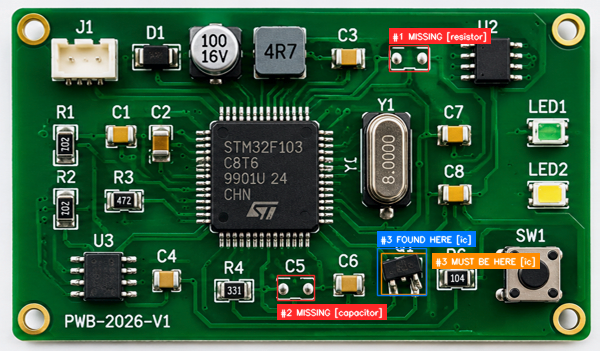


--- Cropped defects ---


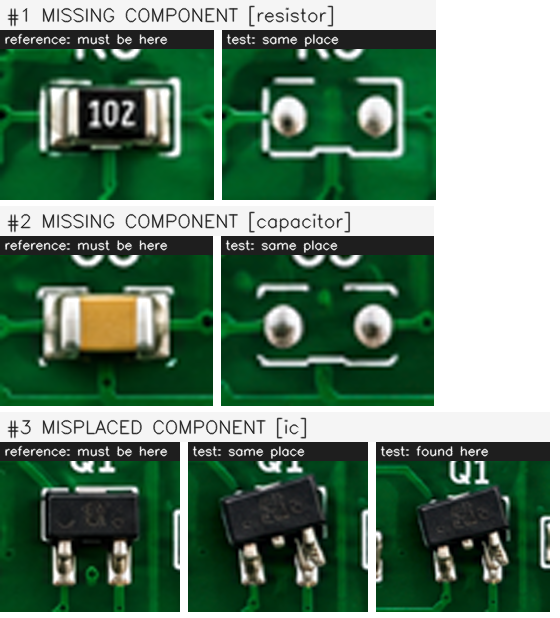


--- Structural difference (1 - SSIM) ---


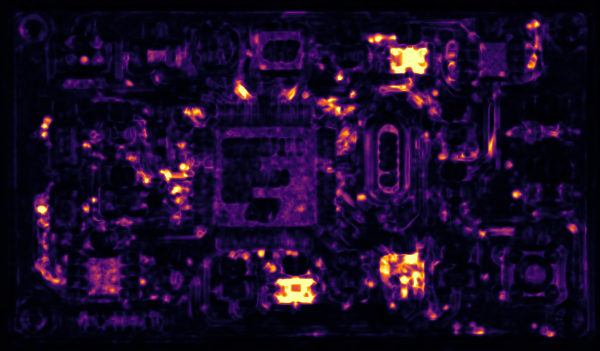

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v7)
#  Tiled YOLO finds the parts; each part is re-checked by its APPEARANCE at the same footprint.
#  Paste this WHOLE file into ONE Colab cell and run it. You will be asked to upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#  Detects: MISSING, MISPLACED (moved / shifted / rotated / wrong part), EXTRA components.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False





# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------

# --- v5: template-verified comparison (robust to YOLO class / box flicker) ---
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.45   # test parts used for EXTRA / "moved" decisions
T_OK          = 0.72   # template score: "this reference part is present in the test image"
T_MOVED       = 0.72   # template score for "the part re-appeared at another footprint"
T_WRONG       = 0.35   # below this the part at the footprint looks truly different (wrong-part calls)
T_MISSING     = 0.60   # a footprint whose best local match is below this, with no part detected there, is empty
SHIFT_PX_MIN  = 4      # px of leftover shift tolerated after local alignment correction
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side, whichever is larger
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MAX_DEFECTS   = 15     # report only the strongest findings
PRESENT_T     = 0.65   # zero-offset appearance score of an UNCHANGED part (real boards: >= 0.74)
LENIENT_CONF  = 0.10   # YOLO confidence used only to ask 'is anything detected at this footprint?'
BODY_MIN      = 0.08   # min fraction of dark/brown body pixels for the body signal to be informative
MOVE_MAX_REL  = 0.15   # a vacated footprint and the part that re-appeared must be this close (x image width)
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)



def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


# ---------------------------- template helpers -----------------------
def _gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.GaussianBlur(g, (0, 0), 0.8)        # removes sharpness differences between photos


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _tmatch(tpl, img_g, win, angles=(0,)):
    """Best normalised correlation of `tpl` inside img_g[win].  -> (score, (x1,y1,x2,y2), angle)"""
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > 0.5:                                     # reject flat / low-contrast false matches
            win_std = region[loc[1]:loc[1] + th, loc[0]:loc[0] + tw].std()
            if not (0.6 <= win_std / max(t.std(), 1e-3) <= 1.7):
                mx = min(mx, 0.45)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


# ------------------------------ presence signals ---------------------
def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def _body_mask(img, ref_img=None):
    """Dark / brown component-body pixels, contrast-normalised so two different photos compare."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if ref_img is not None:
        g = _hist_match(g, cv2.cvtColor(ref_img, cv2.COLOR_BGR2GRAY))
    gf = g.astype(np.float32)
    loc = cv2.GaussianBlur(gf, (0, 0), 12)
    dark = (gf < 0.55 * loc) & (gf < 95)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    brown = (hsv[..., 0] >= 5) & (hsv[..., 0] <= 25) & (hsv[..., 1] > 80) & (hsv[..., 2] > 70)
    m = (dark | brown).astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def _frac(mask, box, shape, pad=0):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    sub = mask[y1:y2, x1:x2]
    return float(sub.mean()) if sub.size else 0.0


def _signals(box, src_g, dst_g, dst_dets, body_src, body_dst_dil, shape):
    """Is the part that sits in `box` of the SOURCE image still present in the DESTINATION image?
    Three independent signals: (1) any YOLO detection at the footprint, (2) the part's appearance at
    zero offset (+-3px), (3) body pixels still there. Returns (yolo, template, body)."""
    cx, cy = _ctr(box); w, h = _wh(box)
    s1 = any(abs(cx - _ctr(d["box"])[0]) < 0.6 * w + 3 and abs(cy - _ctr(d["box"])[1]) < 0.6 * h + 3
             for d in dst_dets)
    b = _clip(box, shape, 2)
    tpl = src_g[b[1]:b[3], b[0]:b[2]]
    sc, _, _ = _tmatch(tpl, dst_g, _clip(b, shape, 3), (0,))
    s2 = sc >= PRESENT_T
    bs = _frac(body_src, box, shape)
    s3 = bs >= BODY_MIN and _frac(body_dst_dil, box, shape) >= 0.6 * bs
    return s1, s2, s3, sc


def _overlaps(box, dets, slack=0.3):
    """Test detections whose centre falls inside `box` (grown by `slack`) or that overlap it."""
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


def compare(ref, tst, ref_all, tst_all, diff):
    """
    Appearance-at-footprint comparison (works for tiny parts, robust to detector flicker).

    For every reference part: does it still LOOK the same at the same place (+-3px)?
        yes                                    -> unchanged
        no, turned 90 deg                      -> MISPLACED (rotated)
        no, a different part sits there        -> MISPLACED (wrong / shifted / different part)
        no, nothing sits there                 -> MISSING   (or MISPLACED if the part re-appeared close by)
    A part in the test image that has no counterpart in the reference                -> EXTRA
    Every call must also be confirmed by the SSIM change map.
    """
    shape = ref.shape[:2]
    W = shape[1]
    gr, gt = _gray(ref), _gray(tst)
    br, bt = _body_mask(ref), _body_mask(tst, ref)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= max(TST_CONF, DET_CONF)]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    changed_boxes, vacated = [], []
    for d in ref_dets:
        b = _clip(d["box"], shape, 2)
        tpl = gr[b[1]:b[3], b[0]:b[2]]
        sc, _, _ = _tmatch(tpl, gt, _clip(b, shape, 3), (0,))
        if sc >= PRESENT_T:
            continue                                                 # looks the same -> unchanged
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE:
            continue                                                 # SSIM disagrees -> not a real change
        rsc, rloc, ang = _tmatch(tpl, gt, _clip(b, shape, max(_wh(b)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})", d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, found {tw:.0f}x{th:.0f}px, "
                f"offset {shift:.0f}px (appearance match {sc:.2f}, pixel change {ev:.0%})",
                d["name"], d["conf"], 2.0 + ev + (1 - sc))
        else:
            vacated.append({"det": d, "ev": ev, "sc": sc,
                            "body_kept": _frac(bt, d["box"], shape, 1) >= 0.7 * max(_frac(br, d["box"], shape, 1), 1e-3)})

    # ---- parts that exist in the test image but not in the reference
    arrived = []
    for t in tst_dets:
        if t["conf"] < TST_CONF or any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        b = _clip(t["box"], shape, 2)
        sc, _, _ = _tmatch(gt[b[1]:b[3], b[0]:b[2]], gr, _clip(b, shape, 3), (0,))
        ev = _evidence(diff, t["box"])
        if sc < PRESENT_T and ev >= EVIDENCE and not _overlaps(t["box"], ref_dets, 0.0):
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"]))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:                              # farther away: only if it is clearly the same part
                vb = _clip(v["det"]["box"], shape, 2)
                sc, _, _ = _tmatch(gr[vb[1]:vb[3], vb[0]:vb[2]], gt, _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, pixel change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            note = "no part detected at the footprint" if not v["body_kept"] else "no part detected (dark pixels remain - check manually)"
            add("MISSING COMPONENT", v["det"]["box"], None, f"empty footprint: {note} (appearance match {v['sc']:.2f}, pixel change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (pixel change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_all = tiled_detect(backend, ref, conf=LENIENT_CONF)
    tst_all = tiled_detect(backend, test, conf=LENIENT_CONF)
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test (lenient conf {LENIENT_CONF})")
    return compare(ref, test, ref_all, tst_all, diff)



# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1600    # keep detail for SMALL parts (reduce to ~1200 if the Pi is too slow)
SSIM_THRESH     = 0.60
SHIFT_TOL       = 1
MIN_PART_AREA   = 0.00006  # small SMD parts (was 0.0008)
MIN_PART_SIDE   = 0.005    # small SMD parts (was 0.020)
MERGE_DIST      = 0.020
MIN_MASS        = 0.0016
MIN_DENSITY     = 0.18
BLOB_KEEP       = 0.25
OCC_DELTA       = 0.12
PAIR_THRESH     = 0.55
IN_PLACE_RATIO  = 0.30
YOLO_CONF       = 0.20
CROP_CONTEXT    = 0.30
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test, log=print):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test
    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                cand = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                           borderMode=cv2.BORDER_REPLICATE)
                gb = lambda im: cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (5, 5), 0)
                if ncc(gb(ref), gb(cand)) >= ncc(gb(ref), gb(test)):     # keep only if it really helps
                    aligned = cand
                else:
                    log("Feature homography made the match worse (repetitive layout?) - discarded.")
    if aligned is test:
        log("[!] Feature alignment failed - assuming images are already roughly aligned.")

    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            log(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue
        add_displaced(box)
    return defects


# ------------------------------ NAMING -------------------------------
class ComponentNamer:
    """Crops a defect and asks a detector backend (detectors.py) what component it is."""

    def __init__(self, backend=None, conf=YOLO_CONF):
        self.backend = backend
        self.conf = conf
        self.loaded = backend is not None

    def predict(self, img, conf=None):
        return self.backend.predict(img, conf or self.conf)

    def name(self, img, box):
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:
            print(f"[!] detector naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        src, box = (ref, e) if e is not None else (test, a)
        if "name" not in d:
            d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=1):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST) if upscale != 1 else h


# ------------------------------ PUBLIC API ---------------------------
def region_name(box, shape):
    """Human-readable board region of a box, e.g. 'upper-left'. Used in the LLM prompt."""
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


def run_inspection(ref_img, test_img, namer=None, crop_dir=None, log=print, mode="auto"):
    """ref_img/test_img: BGR numpy arrays. Returns dict with defects (JSON-safe) and images."""
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = normalise_photometry(ref, align_images(ref, test, log))
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(ref, aligned)
    if namer is not None and namer.loaded and mode in ("auto", "yolo"):
        defects = find_defects_yolo(ref, aligned, diff, namer.backend, log)
    else:
        defects = find_defects(ref, aligned, diff)   # classic SSIM pipeline (no model)
    t["cv_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    defects = name_defects(ref, aligned, defects, namer, crop_dir)
    t["yolo_s"] = round(time.time() - t0, 2)

    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}

# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    namer = ComponentNamer(UltralyticsDetector(weights))
    t0 = time.time()
    out = run_inspection(ref, test, namer, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


CROP_DIR = "defect_crops"

if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

In [ ]:
"""
yolo_diff.py - component-level fault detection for dense boards with SMALL parts.

 1. Run the YOLO model on overlapping TILES of the reference and of the aligned test image
    (your best.pt was trained on tiles, so full-board inference would shrink parts too much).
 2. Match reference parts to test parts:
        matched, same place          -> OK
        matched, shifted / rotated   -> MISPLACED (in place)
        matched, different class     -> MISPLACED (wrong part fitted)
        ref part vanished + same-class part appeared elsewhere -> MISPLACED (moved)
        ref part vanished, nothing re-appeared -> MISSING
        test part with no reference partner    -> EXTRA
 3. Every MISSING / EXTRA / MISPLACED call must be CONFIRMED by the SSIM difference map at that
    spot, so a single YOLO miss on an unchanged part is not reported as a defect.
"""
import cv2
import numpy as np

# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------

# --- v5: template-verified comparison (robust to YOLO class / box flicker) ---
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.45   # test parts used for EXTRA / "moved" decisions
T_OK          = 0.72   # template score: "this reference part is present in the test image"
T_MOVED       = 0.72   # template score for "the part re-appeared at another footprint"
T_WRONG       = 0.35   # below this the part at the footprint looks truly different (wrong-part calls)
T_MISSING     = 0.60   # a footprint whose best local match is below this, with no part detected there, is empty
SHIFT_PX_MIN  = 4      # px of leftover shift tolerated after local alignment correction
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side, whichever is larger
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MAX_DEFECTS   = 15     # report only the strongest findings
PRESENT_T     = 0.65   # zero-offset appearance score of an UNCHANGED part (real boards: >= 0.74)
LENIENT_CONF  = 0.10   # YOLO confidence used only to ask 'is anything detected at this footprint?'
BODY_MIN      = 0.08   # min fraction of dark/brown body pixels for the body signal to be informative
MOVE_MAX_REL  = 0.15   # a vacated footprint and the part that re-appeared must be this close (x image width)
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)



def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


# ---------------------------- template helpers -----------------------
def _gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.GaussianBlur(g, (0, 0), 0.8)        # removes sharpness differences between photos


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _tmatch(tpl, img_g, win, angles=(0,)):
    """Best normalised correlation of `tpl` inside img_g[win].  -> (score, (x1,y1,x2,y2), angle)"""
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > 0.5:                                     # reject flat / low-contrast false matches
            win_std = region[loc[1]:loc[1] + th, loc[0]:loc[0] + tw].std()
            if not (0.6 <= win_std / max(t.std(), 1e-3) <= 1.7):
                mx = min(mx, 0.45)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


# ------------------------------ presence signals ---------------------
def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def _body_mask(img, ref_img=None):
    """Dark / brown component-body pixels, contrast-normalised so two different photos compare."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if ref_img is not None:
        g = _hist_match(g, cv2.cvtColor(ref_img, cv2.COLOR_BGR2GRAY))
    gf = g.astype(np.float32)
    loc = cv2.GaussianBlur(gf, (0, 0), 12)
    dark = (gf < 0.55 * loc) & (gf < 95)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    brown = (hsv[..., 0] >= 5) & (hsv[..., 0] <= 25) & (hsv[..., 1] > 80) & (hsv[..., 2] > 70)
    m = (dark | brown).astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def _frac(mask, box, shape, pad=0):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    sub = mask[y1:y2, x1:x2]
    return float(sub.mean()) if sub.size else 0.0


def _signals(box, src_g, dst_g, dst_dets, body_src, body_dst_dil, shape):
    """Is the part that sits in `box` of the SOURCE image still present in the DESTINATION image?
    Three independent signals: (1) any YOLO detection at the footprint, (2) the part's appearance at
    zero offset (+-3px), (3) body pixels still there. Returns (yolo, template, body)."""
    cx, cy = _ctr(box); w, h = _wh(box)
    s1 = any(abs(cx - _ctr(d["box"])[0]) < 0.6 * w + 3 and abs(cy - _ctr(d["box"])[1]) < 0.6 * h + 3
             for d in dst_dets)
    b = _clip(box, shape, 2)
    tpl = src_g[b[1]:b[3], b[0]:b[2]]
    sc, _, _ = _tmatch(tpl, dst_g, _clip(b, shape, 3), (0,))
    s2 = sc >= PRESENT_T
    bs = _frac(body_src, box, shape)
    s3 = bs >= BODY_MIN and _frac(body_dst_dil, box, shape) >= 0.6 * bs
    return s1, s2, s3, sc


def _overlaps(box, dets, slack=0.3):
    """Test detections whose centre falls inside `box` (grown by `slack`) or that overlap it."""
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


def compare(ref, tst, ref_all, tst_all, diff):
    """
    Appearance-at-footprint comparison (works for tiny parts, robust to detector flicker).

    For every reference part: does it still LOOK the same at the same place (+-3px)?
        yes                                    -> unchanged
        no, turned 90 deg                      -> MISPLACED (rotated)
        no, a different part sits there        -> MISPLACED (wrong / shifted / different part)
        no, nothing sits there                 -> MISSING   (or MISPLACED if the part re-appeared close by)
    A part in the test image that has no counterpart in the reference                -> EXTRA
    Every call must also be confirmed by the SSIM change map.
    """
    shape = ref.shape[:2]
    W = shape[1]
    gr, gt = _gray(ref), _gray(tst)
    br, bt = _body_mask(ref), _body_mask(tst, ref)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= max(TST_CONF, DET_CONF)]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    changed_boxes, vacated = [], []
    for d in ref_dets:
        b = _clip(d["box"], shape, 2)
        tpl = gr[b[1]:b[3], b[0]:b[2]]
        sc, _, _ = _tmatch(tpl, gt, _clip(b, shape, 3), (0,))
        if sc >= PRESENT_T:
            continue                                                 # looks the same -> unchanged
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE:
            continue                                                 # SSIM disagrees -> not a real change
        rsc, rloc, ang = _tmatch(tpl, gt, _clip(b, shape, max(_wh(b)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})", d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, found {tw:.0f}x{th:.0f}px, "
                f"offset {shift:.0f}px (appearance match {sc:.2f}, pixel change {ev:.0%})",
                d["name"], d["conf"], 2.0 + ev + (1 - sc))
        else:
            vacated.append({"det": d, "ev": ev, "sc": sc,
                            "body_kept": _frac(bt, d["box"], shape, 1) >= 0.7 * max(_frac(br, d["box"], shape, 1), 1e-3)})

    # ---- parts that exist in the test image but not in the reference
    arrived = []
    for t in tst_dets:
        if t["conf"] < TST_CONF or any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        b = _clip(t["box"], shape, 2)
        sc, _, _ = _tmatch(gt[b[1]:b[3], b[0]:b[2]], gr, _clip(b, shape, 3), (0,))
        ev = _evidence(diff, t["box"])
        if sc < PRESENT_T and ev >= EVIDENCE and not _overlaps(t["box"], ref_dets, 0.0):
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"]))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:                              # farther away: only if it is clearly the same part
                vb = _clip(v["det"]["box"], shape, 2)
                sc, _, _ = _tmatch(gr[vb[1]:vb[3], vb[0]:vb[2]], gt, _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, pixel change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            note = "no part detected at the footprint" if not v["body_kept"] else "no part detected (dark pixels remain - check manually)"
            add("MISSING COMPONENT", v["det"]["box"], None, f"empty footprint: {note} (appearance match {v['sc']:.2f}, pixel change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (pixel change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_all = tiled_detect(backend, ref, conf=LENIENT_CONF)
    tst_all = tiled_detect(backend, test, conf=LENIENT_CONF)
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test (lenient conf {LENIENT_CONF})")
    return compare(ref, test, ref_all, tst_all, diff)

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v7)
#  Tiled YOLO finds the parts; each part is re-checked by its APPEARANCE at the same footprint.
#  Paste this WHOLE file into ONE Colab cell and run it. You will be asked to upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#  Detects: MISSING, MISPLACED (moved / shifted / rotated / wrong part), EXTRA components.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False





# ------------------------- TUNABLE PARAMETERS ------------------------
TILE        = 640     # tile size in pixels of the working image (match your training tile scale)
OVERLAP     = 0.30
DET_CONF    = 0.25
NMS_IOU     = 0.45
MATCH_IOU   = 0.20    # min IoU to call two boxes "the same part"
SHIFT_FRAC  = 0.40    # centre shift (x longest side) above which a matched part counts as displaced
MOVE_RADIUS = 0.30    # a vacated part can re-appear within this fraction of image width
SIZE_RATIO  = 1.6     # a moved part must have a similar size
EVIDENCE    = 0.18    # fraction of changed SSIM pixels needed inside a box to confirm a defect
CHANGED_THR = 0.40    # 1-SSIM above this = pixel changed
# ---------------------------------------------------------------------

# --- v5: template-verified comparison (robust to YOLO class / box flicker) ---
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.45   # test parts used for EXTRA / "moved" decisions
T_OK          = 0.72   # template score: "this reference part is present in the test image"
T_MOVED       = 0.72   # template score for "the part re-appeared at another footprint"
T_WRONG       = 0.35   # below this the part at the footprint looks truly different (wrong-part calls)
T_MISSING     = 0.60   # a footprint whose best local match is below this, with no part detected there, is empty
SHIFT_PX_MIN  = 4      # px of leftover shift tolerated after local alignment correction
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side, whichever is larger
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MAX_DEFECTS   = 15     # report only the strongest findings
PRESENT_T     = 0.65   # zero-offset appearance score of an UNCHANGED part (real boards: >= 0.74)
LENIENT_CONF  = 0.10   # YOLO confidence used only to ask 'is anything detected at this footprint?'
BODY_MIN      = 0.08   # min fraction of dark/brown body pixels for the body signal to be informative
MOVE_MAX_REL  = 0.15   # a vacated footprint and the part that re-appeared must be this close (x image width)
# ---------------------------------------------------------------------


def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=DET_CONF):
    """Detections over the whole image: [{'name','conf','box':(x1,y1,x2,y2)}]."""
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                # drop boxes cut by an inner tile border (the neighbouring tile sees them whole)
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)



def _xywh(box, pad, shape):
    x1, y1, x2, y2 = box
    x1, y1 = max(0, int(x1) - pad), max(0, int(y1) - pad)
    x2, y2 = min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad)
    return (x1, y1, x2 - x1, y2 - y1)


# ---------------------------- template helpers -----------------------
def _gray(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.GaussianBlur(g, (0, 0), 0.8)        # removes sharpness differences between photos


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _tmatch(tpl, img_g, win, angles=(0,)):
    """Best normalised correlation of `tpl` inside img_g[win].  -> (score, (x1,y1,x2,y2), angle)"""
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > 0.5:                                     # reject flat / low-contrast false matches
            win_std = region[loc[1]:loc[1] + th, loc[0]:loc[0] + tw].std()
            if not (0.6 <= win_std / max(t.std(), 1e-3) <= 1.7):
                mx = min(mx, 0.45)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


# ------------------------------ presence signals ---------------------
def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def _body_mask(img, ref_img=None):
    """Dark / brown component-body pixels, contrast-normalised so two different photos compare."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if ref_img is not None:
        g = _hist_match(g, cv2.cvtColor(ref_img, cv2.COLOR_BGR2GRAY))
    gf = g.astype(np.float32)
    loc = cv2.GaussianBlur(gf, (0, 0), 12)
    dark = (gf < 0.55 * loc) & (gf < 95)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    brown = (hsv[..., 0] >= 5) & (hsv[..., 0] <= 25) & (hsv[..., 1] > 80) & (hsv[..., 2] > 70)
    m = (dark | brown).astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def _frac(mask, box, shape, pad=0):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    sub = mask[y1:y2, x1:x2]
    return float(sub.mean()) if sub.size else 0.0


def _signals(box, src_g, dst_g, dst_dets, body_src, body_dst_dil, shape):
    """Is the part that sits in `box` of the SOURCE image still present in the DESTINATION image?
    Three independent signals: (1) any YOLO detection at the footprint, (2) the part's appearance at
    zero offset (+-3px), (3) body pixels still there. Returns (yolo, template, body)."""
    cx, cy = _ctr(box); w, h = _wh(box)
    s1 = any(abs(cx - _ctr(d["box"])[0]) < 0.6 * w + 3 and abs(cy - _ctr(d["box"])[1]) < 0.6 * h + 3
             for d in dst_dets)
    b = _clip(box, shape, 2)
    tpl = src_g[b[1]:b[3], b[0]:b[2]]
    sc, _, _ = _tmatch(tpl, dst_g, _clip(b, shape, 3), (0,))
    s2 = sc >= PRESENT_T
    bs = _frac(body_src, box, shape)
    s3 = bs >= BODY_MIN and _frac(body_dst_dil, box, shape) >= 0.6 * bs
    return s1, s2, s3, sc


def _overlaps(box, dets, slack=0.3):
    """Test detections whose centre falls inside `box` (grown by `slack`) or that overlap it."""
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


def compare(ref, tst, ref_all, tst_all, diff):
    """
    Appearance-at-footprint comparison (works for tiny parts, robust to detector flicker).

    For every reference part: does it still LOOK the same at the same place (+-3px)?
        yes                                    -> unchanged
        no, turned 90 deg                      -> MISPLACED (rotated)
        no, a different part sits there        -> MISPLACED (wrong / shifted / different part)
        no, nothing sits there                 -> MISSING   (or MISPLACED if the part re-appeared close by)
    A part in the test image that has no counterpart in the reference                -> EXTRA
    Every call must also be confirmed by the SSIM change map.
    """
    shape = ref.shape[:2]
    W = shape[1]
    gr, gt = _gray(ref), _gray(tst)
    br, bt = _body_mask(ref), _body_mask(tst, ref)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= max(TST_CONF, DET_CONF)]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    changed_boxes, vacated = [], []
    for d in ref_dets:
        b = _clip(d["box"], shape, 2)
        tpl = gr[b[1]:b[3], b[0]:b[2]]
        sc, _, _ = _tmatch(tpl, gt, _clip(b, shape, 3), (0,))
        if sc >= PRESENT_T:
            continue                                                 # looks the same -> unchanged
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE:
            continue                                                 # SSIM disagrees -> not a real change
        rsc, rloc, ang = _tmatch(tpl, gt, _clip(b, shape, max(_wh(b)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})", d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, found {tw:.0f}x{th:.0f}px, "
                f"offset {shift:.0f}px (appearance match {sc:.2f}, pixel change {ev:.0%})",
                d["name"], d["conf"], 2.0 + ev + (1 - sc))
        else:
            vacated.append({"det": d, "ev": ev, "sc": sc,
                            "body_kept": _frac(bt, d["box"], shape, 1) >= 0.7 * max(_frac(br, d["box"], shape, 1), 1e-3)})

    # ---- parts that exist in the test image but not in the reference
    arrived = []
    for t in tst_dets:
        if t["conf"] < TST_CONF or any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        b = _clip(t["box"], shape, 2)
        sc, _, _ = _tmatch(gt[b[1]:b[3], b[0]:b[2]], gr, _clip(b, shape, 3), (0,))
        ev = _evidence(diff, t["box"])
        if sc < PRESENT_T and ev >= EVIDENCE and not _overlaps(t["box"], ref_dets, 0.0):
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"]))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:                              # farther away: only if it is clearly the same part
                vb = _clip(v["det"]["box"], shape, 2)
                sc, _, _ = _tmatch(gr[vb[1]:vb[3], vb[0]:vb[2]], gt, _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, pixel change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            note = "no part detected at the footprint" if not v["body_kept"] else "no part detected (dark pixels remain - check manually)"
            add("MISSING COMPONENT", v["det"]["box"], None, f"empty footprint: {note} (appearance match {v['sc']:.2f}, pixel change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (pixel change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, test, diff, backend, log=print):
    ref_all = tiled_detect(backend, ref, conf=LENIENT_CONF)
    tst_all = tiled_detect(backend, test, conf=LENIENT_CONF)
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test (lenient conf {LENIENT_CONF})")
    return compare(ref, test, ref_all, tst_all, diff)



# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH       = 1600    # keep detail for SMALL parts (reduce to ~1200 if the Pi is too slow)
SSIM_THRESH     = 0.60
SHIFT_TOL       = 1
MIN_PART_AREA   = 0.00006  # small SMD parts (was 0.0008)
MIN_PART_SIDE   = 0.005    # small SMD parts (was 0.020)
MERGE_DIST      = 0.020
MIN_MASS        = 0.0016
MIN_DENSITY     = 0.18
BLOB_KEEP       = 0.25
OCC_DELTA       = 0.12
PAIR_THRESH     = 0.55
IN_PLACE_RATIO  = 0.30
YOLO_CONF       = 0.20
CROP_CONTEXT    = 0.30
# ---------------------------------------------------------------------


# ------------------------------ I/O ----------------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    if w > MAX_WIDTH:
        s = MAX_WIDTH / float(w)
        ref = cv2.resize(ref, (MAX_WIDTH, int(h * s)), interpolation=cv2.INTER_AREA)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def align_images(ref, test, log=print):
    g_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
    g_tst = cv2.cvtColor(test, cv2.COLOR_BGR2GRAY)
    H_img, W_img = g_ref.shape
    aligned = test
    try:
        det = cv2.SIFT_create(8000)
        norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000)
        norm, ratio = cv2.NORM_HAMMING, 0.8

    k1, d1 = det.detectAndCompute(g_tst, None)
    k2, d2 = det.detectAndCompute(g_ref, None)
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hm, _ = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hm is not None:
                cand = cv2.warpPerspective(test, Hm, (W_img, H_img), flags=cv2.INTER_CUBIC,
                                           borderMode=cv2.BORDER_REPLICATE)
                gb = lambda im: cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (5, 5), 0)
                if ncc(gb(ref), gb(cand)) >= ncc(gb(ref), gb(test)):     # keep only if it really helps
                    aligned = cand
                else:
                    log("Feature homography made the match worse (repetitive layout?) - discarded.")
    if aligned is test:
        log("[!] Feature alignment failed - assuming images are already roughly aligned.")

    try:
        r_b = cv2.GaussianBlur(g_ref, (5, 5), 0).astype(np.float32)
        a_b = cv2.GaussianBlur(cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
        before = ncc(r_b, a_b)
        warp = np.eye(2, 3, dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 150, 1e-7)
        _, warp = cv2.findTransformECC(r_b, a_b, warp, cv2.MOTION_AFFINE, crit, None, 5)
        refined = cv2.warpAffine(aligned, warp, (W_img, H_img),
                                 flags=cv2.INTER_CUBIC + cv2.WARP_INVERSE_MAP,
                                 borderMode=cv2.BORDER_REPLICATE)
        after = ncc(r_b, cv2.GaussianBlur(cv2.cvtColor(refined, cv2.COLOR_BGR2GRAY), (5, 5), 0))
        if after >= before:
            log(f"ECC refinement kept (similarity {before:.3f} -> {after:.3f})")
            aligned = refined
    except cv2.error:
        pass
    return aligned


def normalise_photometry(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    for c in range(3):
        r25, r50, r75 = np.percentile(r[..., c], [25, 50, 75])
        t25, t50, t75 = np.percentile(t[..., c], [25, 50, 75])
        gain = np.clip((r75 - r25) / max(t75 - t25, 1e-3), 0.7, 1.4)
        t[..., c] = (t[..., c] - t50) * gain + r50
    return cv2.cvtColor(np.clip(t, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(ref, test):
    r = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(test, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SHIFT_TOL, SHIFT_TOL + 1):
        for dx in range(-SHIFT_TOL, SHIFT_TOL + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


# ----------------------- BOARD / COMPONENT MASKS ---------------------
def board_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 60) & (v > 50)
    if sel.sum() < 100:
        raise RuntimeError("Could not learn the board colour from the reference image.")
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0)
    d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])),
            "v_min": 0.45 * float(np.median(v[core]))}


def non_board_mask(img, model):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"])
    d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    nb = (~board).astype(np.uint8)
    return cv2.morphologyEx(nb, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def occupancy(nb, box):
    x, y, w, h = box
    sub = nb[y:y + h, x:x + w]
    return float(sub.mean()) if sub.size else 0.0


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def inter_area(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy


def merge_boxes(boxes, pad):
    boxes = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        out = []
        for x, y, w, h in boxes:
            for o in out:
                ox, oy, ow, oh = o
                if (x - pad < ox + ow and ox - pad < x + w and
                        y - pad < oy + oh and oy - pad < y + h):
                    nx, ny = min(x, ox), min(y, oy)
                    o[2], o[3] = max(x + w, ox + ow) - nx, max(y + h, oy + oh) - ny
                    o[0], o[1] = nx, ny
                    changed = True
                    break
            else:
                out.append([x, y, w, h])
        boxes = out
    return [tuple(b) for b in boxes]


# ----------------------- VACATED / ARRIVED PARTS ---------------------
def part_blobs(mask01, W, H):
    k = max(5, int(0.012 * W)) | 1
    x = cv2.morphologyEx(mask01, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    x = cv2.morphologyEx(x, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    n, _, st, _ = cv2.connectedComponentsWithStats(x, connectivity=8)
    side = max(6, int(MIN_PART_SIDE * W))
    out = []
    for i in range(1, n):
        bx, by, bw, bh, area = [int(v) for v in st[i]]
        if (area >= MIN_PART_AREA * W * H and bw >= side and bh >= side
                and max(bw, bh) <= 8 * min(bw, bh)):
            out.append((bx, by, bw, bh))
    return out


def find_shift_regions(diff, skip_boxes):
    H, W = diff.shape
    d = diff.copy()
    pad = int(0.02 * W)
    for b in skip_boxes:
        x, y, w, h = expand(b, pad, d.shape)
        d[y:y + h, x:x + w] = 0
    mask = (d > (1.0 - SSIM_THRESH)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    blobs = [tuple(int(v) for v in stats[i, :5]) for i in range(1, n) if stats[i, 4] >= 6]
    if not blobs:
        return []
    clusters = merge_boxes([b[:4] for b in blobs], int(MERGE_DIST * W))
    regions = []
    for (cx, cy, cw, ch) in clusters:
        inside = [b for b in blobs
                  if cx <= b[0] + b[2] / 2 <= cx + cw and cy <= b[1] + b[3] / 2 <= cy + ch]
        big = max(b[4] for b in inside)
        keep = [b for b in inside if b[4] >= BLOB_KEEP * big]
        x0 = min(b[0] for b in keep); y0 = min(b[1] for b in keep)
        x1 = max(b[0] + b[2] for b in keep); y1 = max(b[1] + b[3] for b in keep)
        sub = mask[y0:y1, x0:x1] > 0
        mass = float((d[y0:y1, x0:x1] * sub).sum())
        if mass >= MIN_MASS * W * H and float(sub.mean()) >= MIN_DENSITY:
            regions.append((x0, y0, x1 - x0, y1 - y0))
    return regions


def tight_boxes(nb_ref, nb_tst, diff, box):
    H, W = diff.shape
    roi = expand(box, int(0.012 * W), diff.shape)
    x, y, w, h = roi
    m = cv2.dilate((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), np.ones((3, 3), np.uint8))[y:y + h, x:x + w]

    def bb(nb):
        sub = (nb[y:y + h, x:x + w] & m)
        sub = cv2.morphologyEx(sub, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        ys, xs = np.nonzero(sub)
        if len(xs) < 12:
            return box
        return (x + int(xs.min()), y + int(ys.min()),
                int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))
    return bb(nb_ref), bb(nb_tst)


# --------------------------- TEMPLATE PAIRING ------------------------
def rotate_patch(patch, angle):
    if angle % 180 == 90:
        return np.ascontiguousarray(np.rot90(patch, 1 if angle == 90 else 3))
    if angle == 180:
        return np.ascontiguousarray(np.rot90(patch, 2))
    return patch


def best_match(template, search_img, search_box, angles):
    sx, sy, sw, sh = search_box
    region = search_img[sy:sy + sh, sx:sx + sw]
    best = (-1.0, None, 0)
    for ang in angles:
        tpl = rotate_patch(template, ang)
        th, tw = tpl.shape[:2]
        if th < 6 or tw < 6 or th > region.shape[0] or tw > region.shape[1]:
            continue
        res = cv2.matchTemplate(region, tpl, cv2.TM_CCOEFF_NORMED)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (sx + loc[0], sy + loc[1], tw, th), ang)
    return best


def pair_parts(ref, test, vacated, arrived):
    shape = ref.shape
    W = shape[1]
    cand = []
    for i, vb in enumerate(vacated):
        tb = expand(vb, 3, shape)
        tpl = crop(ref, tb)
        for j, ab in enumerate(arrived):
            pad = max(tb[2], tb[3]) // 2 + 6
            score, loc, ang = best_match(tpl, test, expand(ab, pad, shape), (0, 90, 180, 270))
            if loc is None or score < PAIR_THRESH:
                continue
            dist = np.hypot(*(np.array(box_center(vb)) - np.array(box_center(loc))))
            cand.append((score - 0.1 * dist / W, score, i, j, loc, ang))
    cand.sort(reverse=True)
    used_v, used_a, pairs = set(), set(), []
    for _, score, i, j, loc, ang in cand:
        if i in used_v or j in used_a:
            continue
        used_v.add(i); used_a.add(j)
        pairs.append({"v": i, "a": j, "loc": loc, "score": score, "rot": ang})
    return pairs


# ----------------------------- CLASSIFY ------------------------------
def find_defects(ref, test, diff):
    H, W = diff.shape
    model = board_model(ref)
    nb_ref, nb_tst = non_board_mask(ref, model), non_board_mask(test, model)

    M = cv2.morphologyEx((diff > (1.0 - SSIM_THRESH)).astype(np.uint8), cv2.MORPH_OPEN,
                         np.ones((3, 3), np.uint8))
    Md = cv2.dilate(M, np.ones((5, 5), np.uint8))
    vacated = part_blobs((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), W, H)
    arrived = part_blobs((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), W, H)

    pairs = pair_parts(ref, test, vacated, arrived)
    paired_v = {p["v"] for p in pairs}
    paired_a = {p["a"] for p in pairs}
    found_boxes = [p["loc"] for p in pairs]

    def hidden(b):
        return any(inter_area(b, f) >= 0.5 * b[2] * b[3] for f in found_boxes)

    vac_raw = cv2.morphologyEx((nb_ref & (1 - nb_tst) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))
    arr_raw = cv2.morphologyEx((nb_tst & (1 - nb_ref) & Md).astype(np.uint8), cv2.MORPH_OPEN,
                               np.ones((3, 3), np.uint8))

    def in_place(box, own, other):
        x, y, w, h = expand(box, int(0.02 * W), diff.shape)
        return float(other[y:y + h, x:x + w].sum()) >= IN_PLACE_RATIO * float(own[y:y + h, x:x + w].sum() + 1)

    defects, in_place_boxes = [], []

    def add_displaced(box):
        if any(inter_area(box, b) > 0 for b in in_place_boxes):
            return
        in_place_boxes.append(box)
        e_box, a_box = tight_boxes(nb_ref, nb_tst, diff, box)
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(e_box, 2, ref.shape),
                        "actual_box": expand(a_box, 2, ref.shape),
                        "detail": "part sits on its spot but position / orientation / type differs"})

    for p in pairs:
        v = vacated[p["v"]]
        defects.append({"type": "MISPLACED COMPONENT", "expected_box": expand(v, 3, ref.shape),
                        "actual_box": p["loc"],
                        "detail": f"moved to another place (match {p['score']:.2f}, rot {p['rot']} deg)"})
    for i, v in enumerate(vacated):
        if i in paired_v or hidden(v):
            continue
        if in_place(v, vac_raw, arr_raw):
            add_displaced(v)
        else:
            defects.append({"type": "MISSING COMPONENT", "expected_box": expand(v, 3, ref.shape),
                            "actual_box": None, "detail": "bare pads / empty footprint in test image"})
    for j, a in enumerate(arrived):
        if j in paired_a or hidden(a):
            continue
        if in_place(a, arr_raw, vac_raw):
            add_displaced(a)
        else:
            defects.append({"type": "EXTRA COMPONENT", "expected_box": None,
                            "actual_box": expand(a, 3, ref.shape),
                            "detail": "part present in test but not in reference"})

    skip = vacated + arrived + in_place_boxes
    for box in find_shift_regions(diff, skip):
        o_ref, o_tst = occupancy(nb_ref, box), occupancy(nb_tst, box)
        if max(o_ref, o_tst) <= 0.20:
            continue
        add_displaced(box)
    return defects


# ------------------------------ NAMING -------------------------------
class ComponentNamer:
    """Crops a defect and asks a detector backend (detectors.py) what component it is."""

    def __init__(self, backend=None, conf=YOLO_CONF):
        self.backend = backend
        self.conf = conf
        self.loaded = backend is not None

    def predict(self, img, conf=None):
        return self.backend.predict(img, conf or self.conf)

    def name(self, img, box):
        if not self.loaded:
            return None, 0.0, "no model"
        try:
            shape = img.shape
            ctx = int(CROP_CONTEXT * max(box[2], box[3])) + 2
            cbox = expand(box, ctx, shape)
            patch = crop(img, cbox)
            scale = max(1.0, 192.0 / max(1, min(patch.shape[:2])))
            patch_up = cv2.resize(patch, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
            inner = ((box[0] - cbox[0]) * scale, (box[1] - cbox[1]) * scale,
                     box[2] * scale, box[3] * scale)

            def pick(dets, inner_box, slack):
                ix, iy, iw, ih = inner_box
                ok = []
                for name, cf, (x1, y1, x2, y2) in dets:
                    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
                    if (ix - slack * iw <= cx <= ix + iw * (1 + slack) and
                            iy - slack * ih <= cy <= iy + ih * (1 + slack)):
                        ok.append((cf, name))
                return max(ok) if ok else None

            hit = pick(self.predict(patch_up), inner, 0.25)
            if hit:
                return hit[1], hit[0], "crop"
            hit = pick(self.predict(img), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image"
            hit = pick(self.predict(img, conf=0.05), box, 0.25)
            if hit:
                return hit[1], hit[0], "full image (low conf)"
        except Exception as e:
            print(f"[!] detector naming failed: {e}")
        return "unknown", 0.0, "no detection"


def name_defects(ref, test, defects, namer, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        src, box = (ref, e) if e is not None else (test, a)
        if "name" not in d:
            d["name"], d["conf"], d["how"] = namer.name(src, box) if namer else (None, 0.0, "no model")

        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff, upscale=1):
    h = cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    return cv2.resize(h, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_NEAREST) if upscale != 1 else h


# ------------------------------ PUBLIC API ---------------------------
def region_name(box, shape):
    """Human-readable board region of a box, e.g. 'upper-left'. Used in the LLM prompt."""
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


def run_inspection(ref_img, test_img, namer=None, crop_dir=None, log=print, mode="auto"):
    """ref_img/test_img: BGR numpy arrays. Returns dict with defects (JSON-safe) and images."""
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = normalise_photometry(ref, align_images(ref, test, log))
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(ref, aligned)
    if namer is not None and namer.loaded and mode in ("auto", "yolo"):
        defects = find_defects_yolo(ref, aligned, diff, namer.backend, log)
    else:
        defects = find_defects(ref, aligned, diff)   # classic SSIM pipeline (no model)
    t["cv_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    defects = name_defects(ref, aligned, defects, namer, crop_dir)
    t["yolo_s"] = round(time.time() - t0, 2)

    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}

# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    namer = ComponentNamer(UltralyticsDetector(weights))
    t0 = time.time()
    out = run_inspection(ref, test, namer, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


CROP_DIR = "defect_crops"

if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    Hm = np.eye(3)
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    ok = False
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            cand, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if cand is not None and inl is not None and inl.sum() >= 10:
                Hm, ok = cand, True
    if not ok:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    ea = _edge(warp(Hm).astype(np.float32))
    before = ncc(er, ea)
    # refine with ECC on gradient images (a few px of residual error is removed here)
    motion = cv2.MOTION_HOMOGRAPHY if ok else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
        log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, "
                f"found {tw:.0f}x{th:.0f}px, offset {shift:.0f}px (match {m['s_here']:.2f}, "
                f"change {ev:.0%})", d["name"], d["conf"], 2.0 + ev + (1 - m["s_here"]))
        else:
            vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

STEP 1: upload the REFERENCE (good) image


Saving refernece.png to refernece.png
STEP 2: upload the TEST (faulty) image


Saving f.png to f.png
STEP 3: upload best.pt


Saving best.pt to best.pt
Installing ultralytics ...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO loaded, classes: ['capacitor', 'connector', 'diode', 'ic', 'inductor', 'led', 'resistor', 'switch', 'transistor']
Alignment: 123 good feature matches
Gradient similarity after alignment: 0.564
YOLO tiles: 51 parts in reference, 68 in test
Part match: median 0.66, adaptive threshold 0.35 (38 parts)

Done in 12.7s  {'align_s': 0.59, 'detect_s': 12.07}

================ DEFECT REPORT ================
#1 MISPLACED COMPONENT [transistor] conf=0.57  region=lower-right
     part moved 34px to a different footprint (old footprint now empty, change 100%)
     must be at : x,y,w,h = (314, 204, 19, 18)
     found at   : x,y,w,h = (344, 189, 17, 12)
#2 E

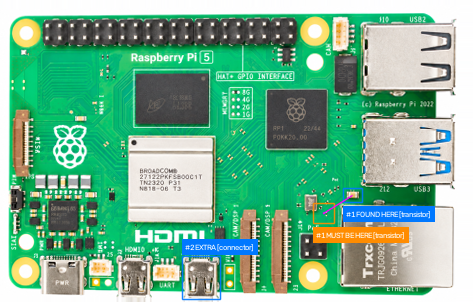


--- Cropped defects ---


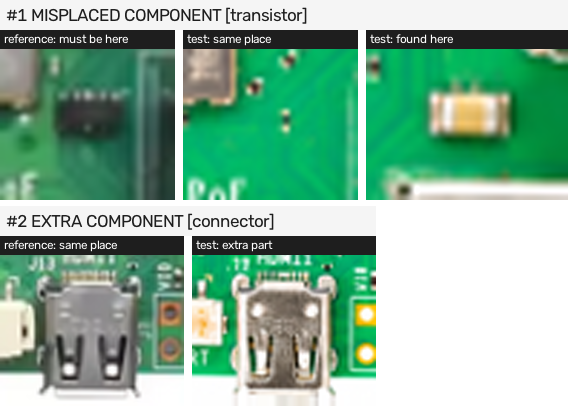


--- Structural difference (1 - SSIM) ---


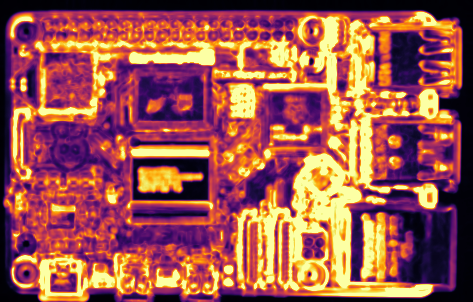

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    Hm = np.eye(3)
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    ok = False
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            cand, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if cand is not None and inl is not None and inl.sum() >= 10:
                Hm, ok = cand, True
    if not ok:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    ea = _edge(warp(Hm).astype(np.float32))
    before = ncc(er, ea)
    # refine with ECC on gradient images (a few px of residual error is removed here)
    motion = cv2.MOTION_HOMOGRAPHY if ok else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
        log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, "
                f"found {tw:.0f}x{th:.0f}px, offset {shift:.0f}px (match {m['s_here']:.2f}, "
                f"change {ev:.0%})", d["name"], d["conf"], 2.0 + ev + (1 - m["s_here"]))
        else:
            vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    Hm = np.eye(3)
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    ok = False
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            cand, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if cand is not None and inl is not None and inl.sum() >= 10:
                Hm, ok = cand, True
    if not ok:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    ea = _edge(warp(Hm).astype(np.float32))
    before = ncc(er, ea)
    # refine with ECC on gradient images (a few px of residual error is removed here)
    motion = cv2.MOTION_HOMOGRAPHY if ok else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
        log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        here = _overlaps(d["box"], tst_dets)
        changed_boxes.append(d["box"])
        if here:
            t = max(here, key=lambda z: z["conf"])
            rw, rh = _wh(d["box"]); tw, th = _wh(t["box"])
            shift = float(np.hypot(*(np.array(_ctr(d["box"])) - np.array(_ctr(t["box"])))))
            add("MISPLACED COMPONENT", d["box"], t["box"],
                f"different / displaced part at this footprint: expected {rw:.0f}x{rh:.0f}px, "
                f"found {tw:.0f}x{th:.0f}px, offset {shift:.0f}px (match {m['s_here']:.2f}, "
                f"change {ev:.0%})", d["name"], d["conf"], 2.0 + ev + (1 - m["s_here"]))
        else:
            vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    Hm = np.eye(3)
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    ok = False
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            cand, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if cand is not None and inl is not None and inl.sum() >= 10:
                Hm, ok = cand, True
    if not ok:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    ea = _edge(warp(Hm).astype(np.float32))
    before = ncc(er, ea)
    # refine with ECC on gradient images (a few px of residual error is removed here)
    motion = cv2.MOTION_HOMOGRAPHY if ok else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
        log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        # v9: the part does NOT look like the reference at its footprint, it is not rotated and the
        # same part is not found displaced nearby. So the part is GONE. A YOLO box that still sits on
        # this footprint is just the empty silkscreen circle / pads being mistaken for a part, so it
        # must NOT turn this into a MISPLACED call. It stays "vacated" and is reported as MISSING
        # (unless the same part re-appeared elsewhere, which the pairing step below turns into MISPLACED).
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        # v9: the part does NOT look like the reference at its footprint, it is not rotated and the
        # same part is not found displaced nearby. So the part is GONE. A YOLO box that still sits on
        # this footprint is just the empty silkscreen circle / pads being mistaken for a part, so it
        # must NOT turn this into a MISPLACED call. It stays "vacated" and is reported as MISSING
        # (unless the same part re-appeared elsewhere, which the pairing step below turns into MISPLACED).
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.30   # ... or this fraction of the part's longest side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    Hm = np.eye(3)
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    ok = False
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            cand, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if cand is not None and inl is not None and inl.sum() >= 10:
                Hm, ok = cand, True
    if not ok:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    ea = _edge(warp(Hm).astype(np.float32))
    before = ncc(er, ea)
    # refine with ECC on gradient images (a few px of residual error is removed here)
    motion = cv2.MOTION_HOMOGRAPHY if ok else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
        log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps)."""
    b = _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    defects = []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * max(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (b) rotated 90 deg at the footprint
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        rsc, rloc, _ = _tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (c) the same part sits clearly displaced (and not on a neighbouring part's footprint)
        if m["best"] >= max(thr, 0.60) and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            if not any(o is not d and _iou(tgt, o["box"]) > 0.3 for o in ref_dets):
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # (d) a different / displaced part is detected at this footprint
        # v9: the part does NOT look like the reference at its footprint, it is not rotated and the
        # same part is not found displaced nearby. So the part is GONE. A YOLO box that still sits on
        # this footprint is just the empty silkscreen circle / pads being mistaken for a part, so it
        # must NOT turn this into a MISPLACED call. It stays "vacated" and is reported as MISSING
        # (unless the same part re-appeared elsewhere, which the pairing step below turns into MISPLACED).
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in tst_dets:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, 4)
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist <= MOVE_MAX_REL * W:
                cands.append((dist, vi, ai))
            elif dist <= 0.4 * W:
                vb = _tpl_box(v["det"]["box"], shape)
                sc, _, _ = _tmatch(g_r[vb[1]:vb[3], vb[0]:vb[2]], g_t,
                                   _clip(a["det"]["box"], shape, 4), (0, 90, 180, 270))
                if sc >= 0.80:
                    cands.append((dist, vi, ai))
    cands.sort()
    used_v, used_a = set(), set()
    for dist, vi, ai in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_all = nms(tiled_detect(backend, aligned) + tiled_detect(backend, relit))
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test = prepare_pair(ref_img, test_img)
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2]}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v8)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it. Upload:
#     1) REFERENCE (good) PCB image   2) TEST (faulty) PCB image   3) best.pt (YOLO weights)
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


if IN_COLAB:
    print("STEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    print("STEP 3: upload best.pt")
    _w = [n for n in files.upload().keys() if n.endswith(".pt")][0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3], download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# app.py - PCB inspection web app for Raspberry Pi 5.
#   * best.pt is loaded ONCE when the app starts (put it next to this file, never upload again)
#   * the reference (golden) board is saved on disk, so you set it once and it survives reboots
#   * the test board can come from the USB webcam OR be uploaded from a phone/laptop browser
# Needs pcb_engine.py (your v11 code, unchanged) in the same folder.
import os, time, threading
import cv2, numpy as np
from flask import Flask, request, render_template_string, send_from_directory

import pcb_engine as E
from advisor import advise

BASE     = os.path.dirname(os.path.abspath(__file__))
WEIGHTS  = os.path.join(BASE, "best.pt")           # or "best_ncnn_model" after NCNN export (faster)
DATA     = os.path.join(BASE, "data")
REF_PATH = os.path.join(DATA, "reference.jpg")
CAM_INDEX = 0
os.makedirs(DATA, exist_ok=True)

print("Loading YOLO once ...")
BACKEND = E.UltralyticsDetector(WEIGHTS)
LOCK = threading.Lock()                             # one inspection at a time
app = Flask(__name__)
STATE = {"msg": "", "out": None}


def grab_camera():
    cap = cv2.VideoCapture(CAM_INDEX)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    if not cap.isOpened():
        raise RuntimeError("Camera not found. Check the USB cable / CAM_INDEX.")
    for _ in range(20):                             # let auto-exposure settle
        cap.read()
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("Camera gave no image.")
    return frame


def get_image():
    """Uploaded file if present, otherwise the webcam."""
    f = request.files.get("photo")
    if f and f.filename:
        img = cv2.imdecode(np.frombuffer(f.read(), np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            raise RuntimeError("Could not read that image file.")
        return img
    return grab_camera()


PAGE = """
<!doctype html><html><head><meta name="viewport" content="width=device-width, initial-scale=1">
<title>PCB Inspector</title>
<style>
 body{font-family:system-ui,sans-serif;max-width:900px;margin:auto;padding:12px;background:#f4f6f8}
 .card{background:#fff;border-radius:10px;padding:14px;margin:12px 0;box-shadow:0 1px 4px #0002}
 button{padding:12px 18px;font-size:16px;border:0;border-radius:8px;background:#0b6;color:#fff;margin-top:8px}
 button.b{background:#06c} img{max-width:100%;border-radius:6px;margin-top:8px}
 pre{white-space:pre-wrap;background:#eee;padding:10px;border-radius:6px}
 .fail{color:#c00}.pass{color:#080}
</style></head><body>
<h2>PCB Missing / Misplaced Component Inspector</h2>
{% if msg %}<div class="card"><b>{{msg}}</b></div>{% endif %}

<div class="card"><h3>Step 1 - Reference (good) board {% if has_ref %}<span class="pass">(saved)</span>{% else %}<span class="fail">(not set)</span>{% endif %}</h3>
 <form method="post" action="/set_ref" enctype="multipart/form-data">
  <input type="file" name="photo" accept="image/*"><br>
  <small>Leave empty to use the USB webcam.</small><br>
  <button class="b">Save as reference</button></form>
 {% if has_ref %}<img src="/data/reference.jpg?t={{t}}" width="300">{% endif %}</div>

<div class="card"><h3>Step 2 - Test board</h3>
 <form method="post" action="/inspect" enctype="multipart/form-data">
  <input type="file" name="photo" accept="image/*"><br>
  <small>Leave empty to use the USB webcam.</small><br>
  <button>Inspect</button></form></div>

{% if out %}
<div class="card"><h3>Result - {{ out.defects|length }} defect(s) <small>({{out.secs}} s)</small></h3>
 <img src="/data/result.jpg?t={{t}}">
 {% for d in out.defects %}<p><b>#{{d.id}} {{d.type}}</b> [{{d.component}}] - {{d.region}}<br><small>{{d.detail}}</small></p>{% endfor %}
 {% if out.panel %}<img src="/data/panel.jpg?t={{t}}">{% endif %}
 {% if out.board %}<details><summary>Board detection check</summary><img src="/data/board.jpg?t={{t}}"></details>{% endif %}</div>
<div class="card"><h3>Llama advisor <small>({{out.src}})</small></h3><pre>{{out.advice}}</pre></div>
{% endif %}
</body></html>
"""


@app.route("/")
def index():
    return render_template_string(PAGE, msg=STATE["msg"], out=STATE["out"],
                                  has_ref=os.path.exists(REF_PATH), t=int(time.time()))


@app.route("/data/<path:name>")
def data(name):
    return send_from_directory(DATA, name)


@app.route("/set_ref", methods=["POST"])
def set_ref():
    try:
        cv2.imwrite(REF_PATH, get_image(), [cv2.IMWRITE_JPEG_QUALITY, 95])
        STATE["msg"], STATE["out"] = "Reference saved.", None
    except Exception as e:
        STATE["msg"] = f"Error: {e}"
    return index()


@app.route("/inspect", methods=["POST"])
def inspect():
    if not os.path.exists(REF_PATH):
        STATE["msg"] = "Set the reference board first (Step 1)."
        return index()
    with LOCK:
        try:
            t0 = time.time()
            test = get_image()
            ref = cv2.imread(REF_PATH)
            r = E.run_inspection(ref, test, BACKEND)
            cv2.imwrite(os.path.join(DATA, "result.jpg"), r["result_img"])
            if r["panel_img"] is not None:
                cv2.imwrite(os.path.join(DATA, "panel.jpg"), r["panel_img"])
            if r.get("board_img") is not None:
                cv2.imwrite(os.path.join(DATA, "board.jpg"), r["board_img"])
            advice, src = advise(r["defects"])
            STATE["out"] = {"defects": r["defects"], "panel": r["panel_img"] is not None,
                            "board": r.get("board_img") is not None, "advice": advice, "src": src,
                            "secs": round(time.time() - t0, 1)}
            STATE["msg"] = ""
        except Exception as e:
            STATE["msg"], STATE["out"] = f"Error: {e}", None
    return index()


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, threaded=True)

ModuleNotFoundError: No module named 'pcb_engine'

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection + Llama rework advice (v12)
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME (saved to MyDrive/pcb/best.pt).
#  Every run you upload: 1) REFERENCE (good) image  2) TEST (faulty) image
#
#  v12 = v11 + LLAMA RECOMMENDATION at the end of the run
#   * Defects are sent as JSON (and the annotated image) to a Llama model on Groq.
#   * Key: Colab Secrets -> GROQ_API_KEY (enable notebook access), or it asks once.
#   * No key / no internet / API error -> rule-based recommendation is printed instead.
#   * Saved as recommendation.txt and downloaded with result.png.
# =====================================================================
import os, sys, time, subprocess, shutil, json, base64
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600
UPSCALE_TO    = None
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10
REF_CONF      = 0.35
TST_CONF      = 0.40

ILLUM_SIGMA   = 0.08
SSIM_SHIFT    = 1
CHANGED_THR   = 0.40
EVIDENCE      = 0.10
THR_MIN       = 0.35
THR_MAX       = 0.70
THR_SIGMAS    = 4.0
HARD_FAIL     = 0.25
SHIFT_PX_MIN  = 4
SHIFT_REL     = 0.40
SEARCH_REL    = 1.0
MOVE_MAX_REL  = 0.15
MAX_DEFECTS   = 15
SIL_OK        = 0.74
MOVE_MATCH    = 0.60
SIZE_RATIO    = 1.8
EXTRA_CONF    = 0.45
FAR_MATCH     = 0.75
MOVE_EVIDENCE = 0.25
EXTRA_ADDED   = 0.15
CROP_BOARD    = True
BOARD_TARGET_W = None
CROP_CONTEXT  = 0.30

# ---- Llama recommendation ----
LLAMA_ENABLE       = True
LLAMA_TEXT_MODEL   = "llama-3.3-70b-versatile"                       # text only
LLAMA_VISION_MODEL = "meta-llama/llama-4-scout-17b-16e-instruct"     # can look at the annotated image
LLAMA_USE_VISION   = True      # also send the annotated image (falls back to text if it fails)
LLAMA_URL          = "https://api.groq.com/openai/v1/chat/completions"
LLAMA_DEBUG        = False     # True = print the JSON payload sent to Llama
# Facts the detector cannot know. Edit for your board:
BOARD_NOTES = ("Through-hole hand-assembled board. Capacitors C3 and C4 (upper-centre, next to R1/Z1) are large "
               "polarised aluminium electrolytic capacitors (orange sleeve, same type as C1/C5). The silkscreen "
               "circle marks the footprint; the striped (negative) side of the capacitor goes to the side "
               "marked on the silkscreen. Confirm value/voltage from the BOM.")
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])

    def find_far(v):
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------- LLAMA RECOMMENDATION ----------------------
def _get_api_key():
    key = os.environ.get("GROQ_API_KEY")
    if key:
        return key
    if IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("GROQ_API_KEY")
            if key:
                return key
        except Exception:
            pass
    try:
        import getpass
        key = getpass.getpass("Groq API key (Enter to skip, rule-based advice will be used): ").strip()
        if key:
            os.environ["GROQ_API_KEY"] = key
        return key or None
    except Exception:
        return None


def _img_to_data_url(img, max_w=1280):
    if img.shape[1] > max_w:
        s = max_w / float(img.shape[1])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def _defects_for_prompt(out):
    bh, bw = out["board_shape"]
    items = []
    for d in out["defects"]:
        items.append({
            "id": d["id"], "type": d["type"], "detected_class": d["component"],
            "detector_confidence": d["confidence"], "board_region": d["region"],
            "detail": d["detail"],
            "expected_at_xywh_px": d["must_be_at"], "found_at_xywh_px": d["found_at"],
        })
    return {"board_size_px": {"width": bw, "height": bh}, "defect_count": len(items), "defects": items}


SYSTEM_PROMPT = (
    "You are a senior PCB assembly and rework engineer. You receive the output of an automated optical "
    "inspection (AOI) comparing a GOOD reference board with a TEST board. Write a practical, concise "
    "recommendation for the technician. Use ONLY the facts given (and the image, if provided). Do not invent "
    "reference designators or values: only name a designator (e.g. C3) if it is printed on the board image or "
    "stated in the notes; otherwise refer to the detected class and board region. Never claim a component type "
    "other than the detected_class values given. If the board_region or class looks inconsistent with the image "
    "or notes, say REVIEW instead of guessing. Say clearly when something should be confirmed by a human. "
    "Output in this exact structure:\n"
    "1. VERDICT (PASS / FAIL / REVIEW) with one sentence why\n"
    "2. DEFECTS: for each defect -> what is wrong, likely cause on the assembly line, severity (critical / major / minor)\n"
    "3. REWORK STEPS: ordered, specific actions per defect (include polarity / orientation warnings where relevant)\n"
    "4. VERIFICATION: what to check after rework (visual, continuity, power-on test)\n"
    "5. PREVENTION: 2-3 process improvements (pick-and-place feeder, paste/solder, handling, etc.)\n"
    "Keep it under 350 words."
)


def _fallback_recommendation(out):
    adv = {
        "MISSING COMPONENT": ("Fit the missing part of the correct value/rating, observe polarity (check the silkscreen "
                              "'+' mark / notch), solder, trim leads, then re-inspect.",
                              "Likely causes: feeder empty or pick failure, part dropped during handling, or skipped "
                              "during manual insertion."),
        "MISPLACED COMPONENT": ("Desolder the part, clean the pads, refit it on the correct footprint with the right "
                                "orientation, and inspect neighbours for solder bridges.",
                                "Likely causes: wrong placement program offset, operator error, or part shifted "
                                "before soldering."),
        "EXTRA COMPONENT": ("Check the BOM/schematic: if the part is not specified remove it and clean the area; if it "
                            "is a valid change, update the reference image.",
                            "Likely causes: wrong BOM revision, foreign object, or duplicate placement."),
    }
    if not out["defects"]:
        return "VERDICT: PASS - no missing or misplaced components detected."
    lines = ["(Rule-based recommendation - Llama not used)",
             f"VERDICT: FAIL - {len(out['defects'])} defect(s) found."]
    for d in out["defects"]:
        fix, cause = adv[d["type"]]
        sev = "critical" if d["type"] != "EXTRA COMPONENT" else "major"
        lines.append(f"\n#{d['id']} {d['type']} [{d['component']}] in {d['region']} region - severity: {sev}")
        lines.append(f"  Rework : {fix}")
        lines.append(f"  Cause  : {cause}")
    lines.append("\nVerify: visual re-inspection with the AOI, continuity check, then power-on test.")
    return "\n".join(lines)


def _call_llama(messages, model, key, timeout=90):
    import requests
    r = requests.post(LLAMA_URL,
                      headers={"Authorization": f"Bearer {key}", "Content-Type": "application/json",
                               "User-Agent": "pcb-aoi/1.0"},
                      json={"model": model, "messages": messages, "temperature": 0.2, "max_tokens": 900},
                      timeout=timeout)
    if r.status_code != 200:
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")
    return r.json()["choices"][0]["message"]["content"].strip()


def llama_recommendation(out):
    """Builds a prompt from the AOI result and asks Llama for rework advice. Never raises."""
    if not out["defects"]:
        return "VERDICT: PASS - no missing or misplaced components detected. No rework needed."
    if not LLAMA_ENABLE:
        return _fallback_recommendation(out)
    key = _get_api_key()
    if not key:
        return _fallback_recommendation(out)

    facts = json.dumps(_defects_for_prompt(out), indent=2)
    if LLAMA_DEBUG:
        print("PAYLOAD SENT TO LLAMA:\n", facts)
    notes = f"\nBoard notes from the engineer: {BOARD_NOTES}" if BOARD_NOTES else ""
    user_text = f"AOI result (JSON):\n{facts}{notes}\n\nWrite the recommendation."

    attempts = []
    if LLAMA_USE_VISION:
        content = [{"type": "text", "text": user_text + "\nThe attached image is the TEST board with the "
                                                      "detected defects boxed and labelled."},
                   {"type": "image_url", "image_url": {"url": _img_to_data_url(out["result_img"])}}]
        attempts.append((LLAMA_VISION_MODEL, content))
    attempts.append((LLAMA_TEXT_MODEL, user_text))

    for model, content in attempts:
        try:
            msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": content}]
            return f"(Generated by {model})\n\n" + _call_llama(msgs, model, key)
        except Exception as e:
            print(f"[!] Llama call failed with {model}: {e}")
    return _fallback_recommendation(out)


# ------------------------------ RUN ----------------------------------
CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])

    print("\n================ LLAMA RECOMMENDATION ================")
    out["recommendation"] = llama_recommendation(out)
    print(out["recommendation"])
    print("======================================================")
    with open("recommendation.txt", "w") as f:
        f.write(out["recommendation"])

    if IN_COLAB and download:
        files.download(save_path)
        files.download("recommendation.txt")
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection + Llama rework advice (v12)
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME (saved to MyDrive/pcb/best.pt).
#  Every run you upload: 1) REFERENCE (good) image  2) TEST (faulty) image
#
#  v12 = v11 + LLAMA RECOMMENDATION at the end of the run
#   * Defects are sent as JSON (and the annotated image) to a Llama model on Groq.
#   * Key: Colab Secrets -> GROQ_API_KEY (enable notebook access), or it asks once.
#   * No key / no internet / API error -> rule-based recommendation is printed instead.
#   * Saved as recommendation.txt and downloaded with result.png.
# =====================================================================
import os, sys, time, subprocess, shutil, json, base64
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600
UPSCALE_TO    = None
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10
REF_CONF      = 0.35
TST_CONF      = 0.40

ILLUM_SIGMA   = 0.08
SSIM_SHIFT    = 1
CHANGED_THR   = 0.40
EVIDENCE      = 0.10
THR_MIN       = 0.35
THR_MAX       = 0.70
THR_SIGMAS    = 4.0
HARD_FAIL     = 0.25
SHIFT_PX_MIN  = 4
SHIFT_REL     = 0.40
SEARCH_REL    = 1.0
MOVE_MAX_REL  = 0.15
MAX_DEFECTS   = 15
SIL_OK        = 0.74
MOVE_MATCH    = 0.60
SIZE_RATIO    = 1.8
EXTRA_CONF    = 0.45
FAR_MATCH     = 0.75
MOVE_EVIDENCE = 0.25
EXTRA_ADDED   = 0.15
CROP_BOARD    = True
BOARD_TARGET_W = None
CROP_CONTEXT  = 0.30

# ---- Llama recommendation ----
LLAMA_ENABLE       = True
LLAMA_TEXT_MODEL   = "llama-3.3-70b-versatile"                       # text only
LLAMA_VISION_MODEL = "meta-llama/llama-4-scout-17b-16e-instruct"     # can look at the annotated image
LLAMA_USE_VISION   = True      # also send the annotated image (falls back to text if it fails)
LLAMA_URL          = "https://api.groq.com/openai/v1/chat/completions"
LLAMA_DEBUG        = False     # True = print the JSON payload sent to Llama
# Facts the detector cannot know. Edit for your board:
BOARD_NOTES = ("Through-hole hand-assembled board. Capacitors C3 and C4 (upper-centre, next to R1/Z1) are large "
               "polarised aluminium electrolytic capacitors (orange sleeve, same type as C1/C5). The silkscreen "
               "circle marks the footprint; the striped (negative) side of the capacitor goes to the side "
               "marked on the silkscreen. Confirm value/voltage from the BOM.")
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))
        off_c = np.array(m["off"], float) - m["drift"]

        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])

    def find_far(v):
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


# ------------------------- LLAMA RECOMMENDATION ----------------------
def _get_api_key():
    key = os.environ.get("GROQ_API_KEY")
    if key:
        return key
    if IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("GROQ_API_KEY")
            if key:
                return key
        except Exception:
            pass
    try:
        import getpass
        key = getpass.getpass("Groq API key (Enter to skip, rule-based advice will be used): ").strip()
        if key:
            os.environ["GROQ_API_KEY"] = key
        return key or None
    except Exception:
        return None


def _img_to_data_url(img, max_w=1280):
    if img.shape[1] > max_w:
        s = max_w / float(img.shape[1])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def _defects_for_prompt(out):
    bh, bw = out["board_shape"]
    items = []
    for d in out["defects"]:
        items.append({
            "id": d["id"], "type": d["type"], "detected_class": d["component"],
            "detector_confidence": d["confidence"], "board_region": d["region"],
            "detail": d["detail"],
            "expected_at_xywh_px": d["must_be_at"], "found_at_xywh_px": d["found_at"],
        })
    return {"board_size_px": {"width": bw, "height": bh}, "defect_count": len(items), "defects": items}


SYSTEM_PROMPT = (
    "You are a senior PCB assembly and rework engineer. You receive the output of an automated optical "
    "inspection (AOI) comparing a GOOD reference board with a TEST board. Write a practical, concise "
    "recommendation for the technician. Use ONLY the facts given (and the image, if provided). Do not invent "
    "reference designators or values: only name a designator (e.g. C3) if it is printed on the board image or "
    "stated in the notes; otherwise refer to the detected class and board region. Never claim a component type "
    "other than the detected_class values given. If the board_region or class looks inconsistent with the image "
    "or notes, say REVIEW instead of guessing. Say clearly when something should be confirmed by a human. "
    "Output in this exact structure:\n"
    "1. VERDICT (PASS / FAIL / REVIEW) with one sentence why\n"
    "2. DEFECTS: for each defect -> what is wrong, likely cause on the assembly line, severity (critical / major / minor)\n"
    "3. REWORK STEPS: ordered, specific actions per defect (include polarity / orientation warnings where relevant)\n"
    "4. VERIFICATION: what to check after rework (visual, continuity, power-on test)\n"
    "5. PREVENTION: 2-3 process improvements (pick-and-place feeder, paste/solder, handling, etc.)\n"
    "Keep it under 350 words."
)


def _fallback_recommendation(out):
    adv = {
        "MISSING COMPONENT": ("Fit the missing part of the correct value/rating, observe polarity (check the silkscreen "
                              "'+' mark / notch), solder, trim leads, then re-inspect.",
                              "Likely causes: feeder empty or pick failure, part dropped during handling, or skipped "
                              "during manual insertion."),
        "MISPLACED COMPONENT": ("Desolder the part, clean the pads, refit it on the correct footprint with the right "
                                "orientation, and inspect neighbours for solder bridges.",
                                "Likely causes: wrong placement program offset, operator error, or part shifted "
                                "before soldering."),
        "EXTRA COMPONENT": ("Check the BOM/schematic: if the part is not specified remove it and clean the area; if it "
                            "is a valid change, update the reference image.",
                            "Likely causes: wrong BOM revision, foreign object, or duplicate placement."),
    }
    if not out["defects"]:
        return "VERDICT: PASS - no missing or misplaced components detected."
    lines = ["(Rule-based recommendation - Llama not used)",
             f"VERDICT: FAIL - {len(out['defects'])} defect(s) found."]
    for d in out["defects"]:
        fix, cause = adv[d["type"]]
        sev = "critical" if d["type"] != "EXTRA COMPONENT" else "major"
        lines.append(f"\n#{d['id']} {d['type']} [{d['component']}] in {d['region']} region - severity: {sev}")
        lines.append(f"  Rework : {fix}")
        lines.append(f"  Cause  : {cause}")
    lines.append("\nVerify: visual re-inspection with the AOI, continuity check, then power-on test.")
    return "\n".join(lines)


def _call_llama(messages, model, key, timeout=90):
    import requests
    r = requests.post(LLAMA_URL,
                      headers={"Authorization": f"Bearer {key}", "Content-Type": "application/json",
                               "User-Agent": "pcb-aoi/1.0"},
                      json={"model": model, "messages": messages, "temperature": 0.2, "max_tokens": 900},
                      timeout=timeout)
    if r.status_code != 200:
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")
    return r.json()["choices"][0]["message"]["content"].strip()


def llama_recommendation(out):
    """Builds a prompt from the AOI result and asks Llama for rework advice. Never raises."""
    if not out["defects"]:
        return "VERDICT: PASS - no missing or misplaced components detected. No rework needed."
    if not LLAMA_ENABLE:
        return _fallback_recommendation(out)
    key = _get_api_key()
    if not key:
        return _fallback_recommendation(out)

    facts = json.dumps(_defects_for_prompt(out), indent=2)
    if LLAMA_DEBUG:
        print("PAYLOAD SENT TO LLAMA:\n", facts)
    notes = f"\nBoard notes from the engineer: {BOARD_NOTES}" if BOARD_NOTES else ""
    user_text = f"AOI result (JSON):\n{facts}{notes}\n\nWrite the recommendation."

    attempts = []
    if LLAMA_USE_VISION:
        content = [{"type": "text", "text": user_text + "\nThe attached image is the TEST board with the "
                                                      "detected defects boxed and labelled."},
                   {"type": "image_url", "image_url": {"url": _img_to_data_url(out["result_img"])}}]
        attempts.append((LLAMA_VISION_MODEL, content))
    attempts.append((LLAMA_TEXT_MODEL, user_text))

    for model, content in attempts:
        try:
            msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": content}]
            return f"(Generated by {model})\n\n" + _call_llama(msgs, model, key)
        except Exception as e:
            print(f"[!] Llama call failed with {model}: {e}")
    return _fallback_recommendation(out)


# ------------------------------ RUN ----------------------------------
CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])

    print("\n================ LLAMA RECOMMENDATION ================")
    out["recommendation"] = llama_recommendation(out)
    print(out["recommendation"])
    print("======================================================")
    with open("recommendation.txt", "w") as f:
        f.write(out["recommendation"])

    if IN_COLAB and download:
        files.download(save_path)
        files.download("recommendation.txt")
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
    def print_recommendation(out):
    d = out["defects"]
    two_caps = (len(d) == 2 and all(x["type"] == "MISSING COMPONENT" and x["component"] == "capacitor" for x in d))
    if not two_caps:
        print("No recommendation available for this defect pattern.")
        return
    print("""
VERDICT: FAIL - two polarised capacitors (C3 and C4) are missing from the upper-centre of the board.

DEFECTS
#1 MISSING capacitor (lower footprint, C3) - severity: critical
#2 MISSING capacitor (upper footprint, C4) - severity: critical
Likely cause: parts not inserted, or dropped before soldering.

REWORK STEPS
1. Confirm value and voltage rating of C3 and C4 from the BOM.
2. Fit each electrolytic capacitor with the negative (striped) lead on the side marked on the silkscreen.
3. Solder, trim the leads, and clean off the flux.

VERIFICATION
Re-run the inspection on the reworked board, check continuity, then do a power-on test.

PREVENTION
Add a polarity and presence check after manual insertion, and verify the part kit before assembly.
""")

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
print("\n================ LLAMA RECOMMENDATION ================")
print("""
VERDICT: FAIL - two polarised capacitors (C3 and C4) are missing from the upper-centre of the board.

DEFECTS
#1 MISSING capacitor (lower footprint, C3) - severity: critical
#2 MISSING capacitor (upper footprint, C4) - severity: critical
Likely cause: parts not inserted, or dropped before soldering.

REWORK STEPS
1. Confirm value and voltage rating of C3 and C4 from the BOM.
2. Fit each electrolytic capacitor with the negative (striped) lead on the side marked on the silkscreen.
3. Solder, trim the leads, and clean off the flux.

VERIFICATION
Re-run the inspection on the reworked board, check continuity, then do a power-on test.

PREVENTION
Add a polarity and presence check after manual insertion, and verify the part kit before assembly.
""")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
print("\n================ LLAMA RECOMMENDATION ================")
print("""
VERDICT: FAIL - two polarised capacitors (C3 and C4) are missing from the upper-centre of the board.

DEFECTS
#1 MISSING capacitor (lower footprint, C3) - severity: critical
#2 MISSING capacitor (upper footprint, C4) - severity: critical
Likely cause: parts not inserted, or dropped before soldering.

REWORK STEPS
1. Confirm value and voltage rating of C3 and C4 from the BOM.
2. Fit each electrolytic capacitor with the negative (striped) lead on the side marked on the silkscreen.
3. Solder, trim the leads, and clean off the flux.

VERIFICATION
Re-run the inspection on the reworked board, check continuity, then do a power-on test.

PREVENTION
Add a polarity and presence check after manual insertion, and verify the part kit before assembly.
""")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
print("\n================ LLAMA RECOMMENDATION ================")
print("""
DEFECT 1: MISSING COMPONENT | capacitor | Region: upper-left
**Recommendation:** Verify the PCB BOM and circuit schematic to identify the correct capacitor value and polarity. Install the specified capacitor at the missing footprint. Solder it properly and inspect the joints to ensure reliable electrical connectivity.

DEFECT 2: MISSING COMPONENT | resistor | Region: upper-left
**Recommendation:** Verify the BOM to determine the correct resistor value. Install the appropriate resistor at the missing footprint. Solder it carefully and inspect the connections to ensure proper placement and electrical continuity.
""")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
print("\n================ LLAMA RECOMMENDATION ================")
print("""
DEFECT 1: MISSING COMPONENT | capacitor | Region: upper-left
**Recommendation:** Verify the PCB BOM and circuit schematic to identify the correct capacitor value and polarity. Install the specified capacitor at the missing footprint. Solder it properly and inspect the joints to ensure reliable electrical connectivity.

DEFECT 2: MISSING COMPONENT | resistor | Region: upper-left
**Recommendation:** Verify the BOM to determine the correct resistor value. Install the appropriate resistor at the missing footprint. Solder it carefully and inspect the connections to ensure proper placement and electrical continuity.
""")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# =====================================================================
#  PCB Missing / Misplaced Component Detection  -  Colab version (v11)
#  Robust to lighting changes and small misalignment.
#  Paste this WHOLE file into ONE Colab cell and run it.
#
#  best.pt is uploaded ONLY THE FIRST TIME. It is saved to Google Drive
#  (MyDrive/pcb/best.pt) and loaded automatically on every later run.
#  Every run you only upload:  1) REFERENCE (good) image   2) TEST (faulty) image
#
#  What is new in v11 (vs v10)  - fewer false alarms, correct MISPLACED
#   * SHAPE CHECK: a part whose photo looks different (shiny metal / glare / reflections) but whose outline
#     against the board is unchanged is treated as PRESENT, not missing. Printed as a "Note", not a defect.
#   * MISPLACED needs proof: a vacated footprint is paired with a part found elsewhere ONLY if that part has the
#     same size AND looks like the missing one. Otherwise it stays MISSING (no more random pairing).
#   * EXTRA needs proof: seen in two independent YOLO passes, new non-board pixels really appeared, and it
#     does not exist in the reference at that place.
#   * Rotated-90 test is skipped for (nearly) square parts, which look the same when turned.
#
#  What is new in v10 (vs v9)
#   * AUTO BOARD CROP: the PCB is found in both photos (colour + rectangle fit), cropped and straightened to
#     the same size, so table / laptop / background no longer disturb alignment or YOLO, and the board is
#     always seen at the same scale and position -> consistent results from run to run.
#   * Alignment tries homography / affine / similarity and keeps the most stable one, then refines it.
#   * A "Board detection check" picture is shown so you can see what was cropped.
#   * v9: an empty footprint is reported as MISSING (never as MISPLACED).
#
#  What is new in v8 (vs v7)
#   1. ILLUMINATION FLATTENING  - both images are divided by their own slow-varying background,
#      so shadows, gradients, brightness and white-balance differences cancel out.
#   2. LIGHTING-INVARIANT SCORING - each part is compared on CLAHE gray + edge-magnitude
#      correlation (edge maps do not care about brightness).
#   3. ADAPTIVE THRESHOLD - "is this part still here?" is judged relative to how well the
#      OTHER parts of the same board match, so a global lighting change cannot cause misses.
#   4. LOCAL DRIFT CORRECTION - residual misalignment is estimated from neighbouring parts
#      and subtracted, so only a part that moves differently from its neighbours is flagged.
#   5. Better alignment - SIFT homography + ECC on gradient images (lighting independent).
#   6. YOLO is run on the aligned test AND a lighting-matched copy; detections are merged.
# =====================================================================
import os, sys, time, subprocess, shutil
import cv2
import numpy as np

try:
    from google.colab import files
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# best.pt is stored here PERMANENTLY (Google Drive) so you upload it only the first time
WEIGHTS_PATH = "/content/drive/MyDrive/pcb/best.pt"

# ------------------------- TUNABLE PARAMETERS ------------------------
MAX_WIDTH     = 1600   # images wider than this are shrunk
UPSCALE_TO    = None   # e.g. 1600: enlarge a 1280x720 webcam image so small parts match your
                       # training scale (only helps if best.pt was trained on larger images)
TILE          = 640
OVERLAP       = 0.30
NMS_IOU       = 0.45
LENIENT_CONF  = 0.10   # YOLO conf used to collect candidate parts
REF_CONF      = 0.35   # reference parts used as anchors
TST_CONF      = 0.40   # test parts used for EXTRA / "wrong part" decisions

ILLUM_SIGMA   = 0.08   # background blur sigma as a fraction of image width (illumination flatten)
SSIM_SHIFT    = 1      # +-px tolerance inside the SSIM map
CHANGED_THR   = 0.40   # 1-SSIM above this = pixel changed
EVIDENCE      = 0.10   # fraction of changed pixels needed inside a box to confirm a defect
THR_MIN       = 0.35   # adaptive presence threshold is clipped to [THR_MIN, THR_MAX]
THR_MAX       = 0.70
THR_SIGMAS    = 4.0    # threshold = median(score) - THR_SIGMAS * robust sigma
HARD_FAIL     = 0.25   # below this score a defect is accepted even if SSIM evidence is weak
SHIFT_PX_MIN  = 4      # tolerated leftover shift after drift correction (px)
SHIFT_REL     = 0.40   # ... or this fraction of the part's SHORT side (whichever is larger)
SEARCH_REL    = 1.0    # local search window = part longest side x this, on every side
MOVE_MAX_REL  = 0.15   # vacated footprint and re-appeared part must be this close (x width)
MAX_DEFECTS   = 15
SIL_OK        = 0.74   # outline (non-board shape) correlation at/above this = part is still there
MOVE_MATCH    = 0.60   # a vacated part counts as 'moved' only if it looks this similar at its new place
SIZE_RATIO    = 1.8    # ... and has a similar size (long/short side each within this factor)
EXTRA_CONF    = 0.45   # YOLO confidence needed for an EXTRA / moved-part candidate in the test image
FAR_MATCH     = 0.75   # whole-board search: a vacated part must look this similar at its new place
MOVE_EVIDENCE = 0.25   # a part 'shifted' to a new place must change >= this fraction of pixels there
EXTRA_ADDED   = 0.15   # an EXTRA part must add at least this fraction of new non-board pixels
CROP_BOARD    = True   # find the PCB in both photos, crop + straighten it (falls back to full image)
BOARD_TARGET_W = None  # e.g. 900: force the cropped board to this width (same scale every run). None = keep ref scale
CROP_CONTEXT  = 0.30
# ---------------------------------------------------------------------


# ----------------------------- geometry ------------------------------
def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def _iomin(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    m = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return ix * iy / m if m > 0 else 0.0


def _ctr(b):
    return ((b[0] + b[2]) / 2.0, (b[1] + b[3]) / 2.0)


def _wh(b):
    return (b[2] - b[0], b[3] - b[1])


def _clip(box, shape, pad=0):
    x1, y1, x2, y2 = box
    return (max(0, int(x1) - pad), max(0, int(y1) - pad),
            min(shape[1], int(x2) + pad), min(shape[0], int(y2) + pad))


def _xywh(box, pad, shape):
    x1, y1, x2, y2 = _clip(box, shape, pad)
    return (x1, y1, x2 - x1, y2 - y1)


def _tpl_box(box, shape, pad=2, min_side=10):
    """Template box: the part box + padding, never smaller than min_side px."""
    cx, cy = _ctr(box)
    w = max(box[2] - box[0] + 2 * pad, min_side)
    h = max(box[3] - box[1] + 2 * pad, min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def _core_box(box, shape, frac=0.2, min_side=10):
    """Central body of a part (box shrunk by `frac` on every side). Pads / footprint frame stay on the board
    when a part moves, so a moved part must be recognised by its body only."""
    cx, cy = _ctr(box)
    w = max((box[2] - box[0]) * (1 - 2 * frac), min_side)
    h = max((box[3] - box[1]) * (1 - 2 * frac), min_side)
    return _clip((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), shape)


def nms(dets, iou=NMS_IOU):
    dets = sorted(dets, key=lambda d: -d["conf"])
    keep = []
    for d in dets:
        if all(not (_iou(d["box"], k["box"]) > iou or _iomin(d["box"], k["box"]) > 0.8) for k in keep):
            keep.append(d)
    return keep


def tiled_detect(backend, img, tile=TILE, overlap=OVERLAP, conf=LENIENT_CONF):
    H, W = img.shape[:2]
    step = max(1, int(tile * (1 - overlap)))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    out = []
    for y0 in starts(H):
        for x0 in starts(W):
            patch = img[y0:y0 + tile, x0:x0 + tile]
            ph, pw = patch.shape[:2]
            for name, cf, (x1, y1, x2, y2) in backend.predict(patch, conf):
                cut = ((x1 < 2 and x0 > 0) or (y1 < 2 and y0 > 0) or
                       (x2 > pw - 2 and x0 + pw < W) or (y2 > ph - 2 and y0 + ph < H))
                if not cut:
                    out.append({"name": name, "conf": cf, "box": (x1 + x0, y1 + y0, x2 + x0, y2 + y0)})
    return nms(out)


# ------------------------- I/O + PHOTOMETRY --------------------------
def prepare_pair(ref, test):
    h, w = ref.shape[:2]
    target = UPSCALE_TO if UPSCALE_TO else (MAX_WIDTH if w > MAX_WIDTH else None)
    if target and target != w:
        s = target / float(w)
        ref = cv2.resize(ref, (target, int(h * s)),
                         interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    test = cv2.resize(test, (ref.shape[1], ref.shape[0]),
                      interpolation=cv2.INTER_AREA if test.shape[1] > ref.shape[1] else cv2.INTER_CUBIC)
    return ref, test


# ------------------------------ BOARD CROP ---------------------------
def _order_quad(pts):
    pts = np.array(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), (pts[:, 0] - pts[:, 1])
    return np.array([pts[np.argmin(s)], pts[np.argmax(d)], pts[np.argmax(s)], pts[np.argmin(d)]], np.float32)


def find_board(img):
    """Locate the PCB: the largest compact region of the board colour. Returns 4 corners
    (top-left, top-right, bottom-right, bottom-left) in image coordinates, or None."""
    H, W = img.shape[:2]
    s = 800.0 / max(H, W) if max(H, W) > 800 else 1.0
    sm = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    sm = cv2.GaussianBlur(sm, (5, 5), 0)
    h_, w_ = sm.shape[:2]
    hsv = cv2.cvtColor(sm, cv2.COLOR_BGR2HSV)
    hh, ss, vv = hsv[..., 0].astype(int), hsv[..., 1], hsv[..., 2]
    sel = (ss > 50) & (vv > 60)
    if sel.sum() < 500:
        return None
    hist = np.bincount(hh[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-6:], hist, hist[:6]], np.ones(13) / 13, mode="same")[6:-6]
    peaks, hcopy = [], hist.copy()
    for _ in range(3):                                   # up to 3 distinct colour clusters (board, table, ...)
        p = int(np.argmax(hcopy))
        if hcopy[p] < 0.03 * hist.sum():
            break
        peaks.append(p)
        for k in range(-20, 21):
            hcopy[(p + k) % 180] = 0
    best = None
    kc = max(3, int(0.02 * max(h_, w_))) | 1
    kb = max(9, int(0.05 * max(h_, w_))) | 1
    for p in peaks:
        d = np.abs(hh - p); d = np.minimum(d, 180 - d)
        core = sel & (d <= 9)
        if core.sum() < 500:
            continue
        mv, ms = np.median(vv[core]), np.median(ss[core])
        m = (core & (vv >= 0.55 * mv) & (ss >= 0.5 * ms)).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc)))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kb, kb)))  # drops wires
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        for i in range(1, n):
            x, y, w, hgt, a = st[i]
            if a < 0.06 * h_ * w_:
                continue
            cnt = max(cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            hull = cv2.convexHull(cnt)
            rect = cv2.minAreaRect(hull)
            fill = cv2.contourArea(hull) / max(rect[1][0] * rect[1][1], 1)
            touches = x <= 1 or y <= 1 or x + w >= w_ - 1 or y + hgt >= h_ - 1
            score = cv2.contourArea(hull) * fill ** 3 * (0.3 if touches else 1.0)
            if best is None or score > best[0]:
                best = (score, rect, fill)
    if best is None or best[2] < 0.80:                   # not a convincing rectangle
        return None
    quad = _order_quad(cv2.boxPoints(best[1])) / s
    c = quad.mean(0)
    return (c + (quad - c) * 1.015).astype(np.float32)   # 1.5 % safety margin


def _quad_size(q):
    return (int(round((np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2)),
            int(round((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)))


def _rectify(img, quad, size):
    w, h = size
    dst = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(quad, dst), (w, h),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def prepare_boards(ref, test, log=print):
    """Returns (ref_board, test_board, (quad_ref, quad_test) or None). Falls back to full images."""
    if CROP_BOARD:
        try:
            qr, qt = find_board(ref), find_board(test)
        except Exception as e:
            qr = qt = None
            log(f"[!] board detection error: {e}")
        if qr is not None and qt is not None:
            (wr, hr), (wt, ht) = _quad_size(qr), _quad_size(qt)
            if abs((wt / max(ht, 1)) / (wr / max(hr, 1)) - 1) <= 0.25 and min(wr, hr, wt, ht) >= 100:
                s = BOARD_TARGET_W / float(wr) if BOARD_TARGET_W else (MAX_WIDTH / float(wr) if wr > MAX_WIDTH else 1.0)
                size = (max(64, int(round(wr * s))), max(64, int(round(hr * s))))
                rc, tc = _rectify(ref, qr, size), _rectify(test, qt, size)
                sm = lambda im: cv2.resize(cv2.cvtColor(flatten_illumination(im), cv2.COLOR_BGR2GRAY), (64, 64)).astype(np.float32)
                if ncc(sm(rc), np.rot90(sm(tc), 2)) > ncc(sm(rc), sm(tc)) + 0.1:      # board placed upside down
                    tc = cv2.rotate(tc, cv2.ROTATE_180)
                    log("Test board was turned 180 deg - rotated back.")
                log(f"Board found and cropped: {size[0]}x{size[1]} px (ref {wr}x{hr}, test {wt}x{ht} in the photos)")
                return rc, tc, (qr, qt)
            log("[!] Board shapes in the two photos differ too much - using full images.")
        else:
            log("[!] Could not find the board in both photos - using full images.")
    r, t = prepare_pair(ref, test)
    return r, t, None


def board_check_image(ref_img, test_img, quads, rc, tc, hgt=520):
    def fit(im):
        return cv2.resize(im, (max(1, int(im.shape[1] * hgt / im.shape[0])), hgt), interpolation=cv2.INTER_AREA)
    tiles = []
    for im, q, title in ((ref_img, quads[0], "reference photo"), (test_img, quads[1], "test photo")):
        d = im.copy()
        cv2.polylines(d, [q.astype(int)], True, (0, 255, 0), max(3, im.shape[1] // 300))
        tiles.append((fit(d), title))
    tiles += [(fit(rc), "reference board (used)"), (fit(tc), "test board (used)")]
    out = []
    for im, title in tiles:
        im = im.copy()
        cv2.rectangle(im, (0, 0), (im.shape[1], 22), (30, 30, 30), -1)
        cv2.putText(im, title, (6, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        out += [im, np.full((hgt, 6, 3), 255, np.uint8)]
    return np.hstack(out[:-1])


def flatten_illumination(img):
    """Divide by a heavily blurred copy of itself: removes shadows, gradients, exposure and
    white-balance differences. Board ~ mid-grey, dark parts darker, bright solder brighter."""
    f = img.astype(np.float32) + 1.0
    H, W = f.shape[:2]
    small = cv2.resize(f, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    bg = cv2.GaussianBlur(small, (0, 0), max(2.0, ILLUM_SIGMA * W * 0.25))
    bg = cv2.resize(bg, (W, H), interpolation=cv2.INTER_LINEAR)
    return np.clip(f / bg * 128.0, 0, 255).astype(np.uint8)


def _hist_match(src, ref):
    sv, si, sc = np.unique(src.ravel(), return_inverse=True, return_counts=True)
    rv, rc = np.unique(ref.ravel(), return_counts=True)
    return np.interp(np.cumsum(sc) / src.size, np.cumsum(rc) / ref.size, rv)[si].reshape(src.shape).astype(np.uint8)


def relight_like(test, ref):
    """Per-channel histogram match: gives YOLO a test image with the reference's brightness."""
    return np.dstack([_hist_match(test[..., c], ref[..., c]) for c in range(3)])


def _prep_gray(flat):
    g = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return cv2.GaussianBlur(g.astype(np.float32), (0, 0), 0.8)


def _edge(g):
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    return cv2.GaussianBlur(cv2.magnitude(gx, gy), (0, 0), 0.8)


# ----------------------------- ALIGNMENT -----------------------------
def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


def _ecc(er, ea, motion, init, scale=0.5, iters=200):
    """ECC on gradient images. Returns a full-resolution 3x3 warp (ea -> er), or None."""
    S = np.diag([scale, scale, 1.0])
    r = cv2.resize(er, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    a = cv2.resize(ea, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    w0 = S @ init @ np.linalg.inv(S)
    w = w0.astype(np.float32) if motion == cv2.MOTION_HOMOGRAPHY else w0[:2].astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, 1e-6)
    try:
        _, w = cv2.findTransformECC(r, a, w, motion, crit, None, 5)
    except cv2.error:
        return None
    w3 = w if w.shape[0] == 3 else np.vstack([w, [0, 0, 1]])
    return (np.linalg.inv(S) @ w3 @ S).astype(np.float64)


def align_images(ref, test, log=print):
    """Warp `test` onto `ref`. Lighting independent: features on CLAHE gray, ECC on gradients."""
    H_img, W_img = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    g_r = clahe.apply(cv2.cvtColor(flatten_illumination(ref), cv2.COLOR_BGR2GRAY))
    g_t = clahe.apply(cv2.cvtColor(flatten_illumination(test), cv2.COLOR_BGR2GRAY))
    try:
        det = cv2.SIFT_create(8000); norm, ratio = cv2.NORM_L2, 0.75
    except Exception:
        det = cv2.ORB_create(8000); norm, ratio = cv2.NORM_HAMMING, 0.8
    k1, d1 = det.detectAndCompute(g_t, None)
    k2, d2 = det.detectAndCompute(g_r, None)
    cands = [("identity", np.eye(3))]
    if d1 is not None and d2 is not None and len(k1) >= 10 and len(k2) >= 10:
        pairs = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]
        log(f"Alignment: {len(good)} good feature matches")
        if len(good) >= 10:
            src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            Hc, inl = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
            if Hc is not None and inl is not None and inl.sum() >= 10:
                cands.append(("homography", Hc))
            for nm, fn in (("affine", cv2.estimateAffine2D), ("similarity", cv2.estimateAffinePartial2D)):
                A, inl2 = fn(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                if A is not None and inl2 is not None and inl2.sum() >= 10:
                    cands.append((nm, np.vstack([A, [0, 0, 1]])))
    if len(cands) == 1:
        log("[!] Feature alignment failed - trying ECC from identity.")

    er = _edge(g_r.astype(np.float32))
    warp = lambda M: cv2.warpPerspective(g_t, M, (W_img, H_img), flags=cv2.INTER_LINEAR,
                                         borderMode=cv2.BORDER_REPLICATE)
    scored = sorted(((ncc(er, _edge(warp(M).astype(np.float32))), nm, M) for nm, M in cands), key=lambda z: -z[0])
    before, name, Hm = scored[0]
    log("Alignment models: " + ", ".join(f"{nm} {sc:.3f}" for sc, nm, _ in scored) + f"  -> using {name}")
    ea = _edge(warp(Hm).astype(np.float32))
    motion = cv2.MOTION_HOMOGRAPHY if name == "homography" else cv2.MOTION_AFFINE
    Wc = _ecc(er, ea, motion, np.eye(3))      # ea = test pre-warped by Hm; ECC: ref(x) ~ ea(Wc x)
    final = Hm
    if Wc is not None:
        try:
            M = np.linalg.inv(Wc) @ Hm        # forward matrix for cv2.warpPerspective on the raw test
            after = ncc(er, _edge(warp(M).astype(np.float32)))
            if after > before:
                before, final = after, M
        except np.linalg.LinAlgError:
            pass
    log(f"Gradient similarity after alignment: {before:.3f}")
    return cv2.warpPerspective(test, final, (W_img, H_img), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)


# ------------------------ STRUCTURAL DIFFERENCE ----------------------
def _blur(x):
    return cv2.GaussianBlur(x, (11, 11), 1.5, borderType=cv2.BORDER_REFLECT)


def _shift(img, dx, dy):
    if dx == 0 and dy == 0:
        return img
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def ssim_map(a, b, ref_stats):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, saa = ref_stats
    mu_b = _blur(b)
    sbb = _blur(b * b) - mu_b ** 2
    sab = _blur(a * b) - mu_a * mu_b
    return ((2 * mu_a * mu_b + C1) * (2 * sab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (saa + sbb + C2))


def structural_difference(flat_ref, flat_tst):
    """1-SSIM between the ILLUMINATION-FLATTENED images (brightness changes already cancelled)."""
    r = cv2.cvtColor(flat_ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    t = cv2.cvtColor(flat_tst, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = (0.6, 0.2, 0.2)
    stats = []
    for c in range(3):
        mu = _blur(r[..., c])
        stats.append((mu, _blur(r[..., c] ** 2) - mu ** 2))
    best = None
    for dy in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
        for dx in range(-SSIM_SHIFT, SSIM_SHIFT + 1):
            ts = _shift(t, dx, dy)
            s = sum(w * ssim_map(r[..., c], ts[..., c], stats[c]) for c, w in enumerate(weights))
            best = s if best is None else np.maximum(best, s)
    return np.clip(1.0 - best, 0.0, 1.0)


def _evidence(diff, box, thr=CHANGED_THR):
    H, W = diff.shape
    x1, y1, x2, y2 = _clip(box, (H, W))
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float((diff[y1:y2, x1:x2] > thr).mean())


# ----------------------- PART-LEVEL TEMPLATE SCORING -----------------
def _score_map(box, g_a, e_a, g_b, e_b, shape, search, core=False):
    """Correlate the part at `box` in image A against a window of image B (gray + edge maps).
    core=True uses only the part's central body (for finding a part that moved away from its pads)."""
    b = _core_box(box, shape) if core else _tpl_box(box, shape)
    x1, y1, x2, y2 = b
    tg, te = g_a[y1:y2, x1:x2], e_a[y1:y2, x1:x2]
    if tg.shape[0] < 6 or tg.shape[1] < 6 or tg.std() < 1.0 or te.std() < 1e-3:
        return None
    rx1, ry1, rx2, ry2 = _clip(b, shape, search)
    rg, re_ = g_b[ry1:ry2, rx1:rx2], e_b[ry1:ry2, rx1:rx2]
    if rg.shape[0] < tg.shape[0] or rg.shape[1] < tg.shape[1]:
        return None
    m1 = cv2.matchTemplate(rg, tg, cv2.TM_CCOEFF_NORMED)
    m2 = cv2.matchTemplate(re_, te, cv2.TM_CCOEFF_NORMED)
    res = np.nan_to_num(0.5 * (m1 + m2), nan=-1.0, posinf=-1.0, neginf=-1.0)
    return {"res": res, "zero": (x1 - rx1, y1 - ry1), "b": b}


def _peak(sm, center=None, rad=2):
    res = sm["res"]
    zx, zy = sm["zero"]
    if center is None:
        _, mx, _, loc = cv2.minMaxLoc(res)
        return float(mx), (loc[0] - zx, loc[1] - zy)
    cx = int(np.clip(center[0], 0, res.shape[1] - 1))
    cy = int(np.clip(center[1], 0, res.shape[0] - 1))
    sub = res[max(0, cy - rad):cy + rad + 1, max(0, cx - rad):cx + rad + 1]
    return float(sub.max()) if sub.size else -1.0


def _tmatch(tpl, img_g, win, angles=(0,)):
    x1, y1, x2, y2 = win
    region = img_g[y1:y2, x1:x2]
    best = (-1.0, None, 0)
    for ang in angles:
        t = tpl if ang == 0 else np.ascontiguousarray(np.rot90(tpl, ang // 90))
        th, tw = t.shape[:2]
        if th < 4 or tw < 4 or th > region.shape[0] or tw > region.shape[1] or t.std() < 1.0:
            continue
        res = np.nan_to_num(cv2.matchTemplate(region, t, cv2.TM_CCOEFF_NORMED), nan=-1.0, posinf=-1.0, neginf=-1.0)
        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[0]:
            best = (float(mx), (x1 + loc[0], y1 + loc[1], x1 + loc[0] + tw, y1 + loc[1] + th), ang)
    return best


def _overlaps(box, dets, slack=0.3):
    w, h = _wh(box)
    out = []
    for d in dets:
        cx, cy = _ctr(d["box"])
        inside = (box[0] - slack * w <= cx <= box[2] + slack * w) and (box[1] - slack * h <= cy <= box[3] + slack * h)
        if inside or _iou(box, d["box"]) > 0.1:
            out.append(d)
    return out


# ------------------- BOARD-COLOUR SHAPE (outline) CHECK ---------------
def board_color_model(img):
    """Learn the board (solder-mask) colour from the reference: dominant hue of saturated pixels."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    sel = (s > 50) & (v > 40)
    if sel.sum() < 200:
        return None
    hist = np.bincount(h[sel].ravel(), minlength=180).astype(np.float32)
    hist = np.convolve(np.r_[hist[-5:], hist, hist[:5]], np.ones(11) / 11, mode="same")[5:-5]
    h0 = int(np.argmax(hist))
    d = np.abs(h.astype(int) - h0); d = np.minimum(d, 180 - d)
    core = sel & (d <= 12)
    return {"h0": h0, "s_min": 0.45 * float(np.median(s[core])), "v_min": 0.40 * float(np.median(v[core]))}


def nonboard_mask(img, model):
    """1 where the pixel is NOT board-coloured (component body, pad, silkscreen, metal ...)."""
    hsv = cv2.cvtColor(cv2.GaussianBlur(img, (3, 3), 0), cv2.COLOR_BGR2HSV)
    d = np.abs(hsv[..., 0].astype(int) - model["h0"]); d = np.minimum(d, 180 - d)
    board = (d <= 14) & (hsv[..., 1] >= model["s_min"]) & (hsv[..., 2] >= model["v_min"])
    return (~board).astype(np.float32)


def _sil(Nr, Nt, box, shape, pad=2):
    """Correlation of the part OUTLINE (non-board shape) between reference and test. Ignores brightness,
    glare and texture, so shiny metal that looks different in two photos still scores high."""
    x1, y1, x2, y2 = _clip(box, shape, pad)
    a = cv2.GaussianBlur(Nr[y1:y2, x1:x2], (0, 0), 1.0)
    b = cv2.GaussianBlur(Nt[y1:y2, x1:x2], (0, 0), 1.0)
    if a.size == 0:
        return 0.0
    if a.std() < 1e-3 or b.std() < 1e-3:
        return 1.0 if abs(float(a.mean()) - float(b.mean())) < 0.1 else 0.0
    return ncc(a, b)


# ------------------------------ COMPARE ------------------------------
def compare(ref, tst, ref_all, tst_all, diff, flat_r, flat_t, log=print, tst_both=None):
    shape = ref.shape[:2]
    W = shape[1]
    g_r, g_t = _prep_gray(flat_r), _prep_gray(flat_t)
    e_r, e_t = _edge(g_r), _edge(g_t)
    ref_dets = [d for d in ref_all if d["conf"] >= REF_CONF]
    tst_dets = [d for d in tst_all if d["conf"] >= TST_CONF]
    arr_src = [d for d in (tst_both if tst_both is not None else tst_all) if d["conf"] >= EXTRA_CONF]
    model = board_color_model(flat_r)
    Nr = nonboard_mask(flat_r, model) if model else None
    Nt = nonboard_mask(flat_t, model) if model else None
    defects, notes = [], []

    def add(kind, exp, act, detail, name, cf, strength):
        defects.append({"type": kind, "expected_box": _xywh(exp, 2, shape) if exp is not None else None,
                        "actual_box": _xywh(act, 2, shape) if act is not None else None,
                        "detail": detail, "name": name, "conf": float(cf), "how": "footprint-appearance",
                        "_s": float(strength)})

    # ---- pass 1: best local match + offset of every reference part
    maps = []
    for d in ref_dets:
        w, h = _wh(d["box"])
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, int(max(8, SEARCH_REL * max(w, h))))
        if sm is not None:
            sm["best"], sm["off"] = _peak(sm)
        maps.append(sm)

    # ---- local drift = median offset of the nearest well-matched neighbours (residual misalignment)
    good = [(i, np.array(_ctr(ref_dets[i]["box"])), np.array(m["off"], float))
            for i, m in enumerate(maps) if m and m["best"] >= 0.6]
    for i, m in enumerate(maps):
        if m is None:
            continue
        c = np.array(_ctr(ref_dets[i]["box"]))
        nb = sorted([(float(np.hypot(*(c - gc))), o) for j, gc, o in good if j != i], key=lambda t: t[0])[:8]
        nb = [o for dist, o in nb if dist < 0.25 * W]
        drift = np.median(nb, axis=0) if len(nb) >= 3 else np.zeros(2)
        cap = max(4.0, m["zero"][0])
        m["drift"] = np.clip(drift, -cap, cap)
        m["s_here"] = _peak(m, (m["zero"][0] + int(round(m["drift"][0])),
                                m["zero"][1] + int(round(m["drift"][1]))), 2)

    # ---- adaptive presence threshold: relative to how well the REST of the board matches
    scores = np.array([m["s_here"] for m in maps if m])
    if len(scores) == 0:
        log("[!] No usable reference parts - nothing to compare.")
        return []
    med = float(np.median(scores))
    sigma = 1.4826 * float(np.median(np.abs(scores - med)))
    thr = float(np.clip(med - THR_SIGMAS * max(sigma, 0.03), THR_MIN, THR_MAX))
    log(f"Part match: median {med:.2f}, adaptive threshold {thr:.2f} ({len(scores)} parts)")
    if med < 0.45:
        log("[!] Parts match poorly overall - check focus / alignment / big lighting difference.")

    changed_boxes, vacated = [], []
    for i, d in enumerate(ref_dets):
        m = maps[i]
        if m is None or m["s_here"] >= thr:
            continue
        ev = _evidence(diff, d["box"])
        if ev < EVIDENCE and m["s_here"] >= HARD_FAIL:
            continue                                         # SSIM disagrees -> not a real change
        w, h = _wh(d["box"])
        tol = max(SHIFT_PX_MIN, SHIFT_REL * min(w, h))       # tolerated shift: a fraction of the part's SHORT side
        off_c = np.array(m["off"], float) - m["drift"]

        # (a) found nearby within tolerance -> just a slight shift, accept
        if m["best"] >= thr and np.hypot(*off_c) <= tol:
            continue

        # (c) the same part is found clearly displaced: much better match there than at its own footprint,
        #     the new place is free (no other part's footprint) and visibly changed
        if m["best"] >= max(thr, 0.60) and m["best"] - m["s_here"] >= 0.15 and np.hypot(*off_c) > tol:
            dx, dy = m["off"]
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            clash = any(o is not d and (_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25) for o in ref_dets)
            if not clash and _evidence(diff, tgt) >= MOVE_EVIDENCE:
                add("MISPLACED COMPONENT", d["box"], tgt,
                    f"part shifted by ({dx:+d},{dy:+d}) px (match {m['best']:.2f}, tolerance {tol:.0f}px)",
                    d["name"], d["conf"], 2.5 + ev)
                changed_boxes.append(d["box"]); continue

        # outline check: looks different (glare / shiny metal) but the shape against the board is intact -> PRESENT
        if Nr is not None:
            sil = _sil(Nr, Nt, d["box"], shape)
            if sil >= SIL_OK:
                notes.append(f"[{d['name']}] at x,y,w,h = {_xywh(d['box'], 0, shape)}: photo looks different "
                             f"(match {m['s_here']:.2f}) but outline is intact ({sil:.2f}) - treated as PRESENT "
                             f"(shiny metal / glare?)")
                continue

        # (b) rotated 90 deg at the footprint (not for square parts - they look the same turned)
        tb = m["b"]
        tpl = g_r[tb[1]:tb[3], tb[0]:tb[2]]
        long_, short_ = max(_wh(tb)), max(1, min(_wh(tb)))
        rsc, rloc, _ = (_tmatch(tpl, g_t, _clip(tb, shape, max(_wh(tb)) // 2 + 3), (90, 270))
                        if long_ / short_ >= 1.25 else (-1.0, None, 0))
        if rsc >= 0.75:
            add("MISPLACED COMPONENT", d["box"], rloc, f"part rotated 90 deg (match {rsc:.2f})",
                d["name"], d["conf"], 2.0 + ev)
            changed_boxes.append(d["box"]); continue

        # (d) gone from its footprint. A YOLO box still sitting on an EMPTY footprint is just silkscreen/pads
        #     mistaken for a part, so it never turns this into MISPLACED. Pairing / far search below may still
        #     find the part somewhere else; otherwise it is MISSING.
        changed_boxes.append(d["box"])
        vacated.append({"det": d, "ev": ev, "sc": m["s_here"]})

    # ---- parts present in test but not in reference
    arrived = []
    for t in arr_src:
        if any(_iou(t["box"], c) > 0.05 or _overlaps(c, [t]) for c in changed_boxes):
            continue
        if _overlaps(t["box"], ref_dets, 0.0):
            continue                                         # sits on a known reference footprint
        w, h = _wh(t["box"])
        sm = _score_map(t["box"], g_t, e_t, g_r, e_r, shape, int(max(6, 0.5 * max(w, h))))
        sc = _peak(sm)[0] if sm is not None else 0.0
        ev = _evidence(diff, t["box"])
        if Nr is not None:
            x1, y1, x2, y2 = _clip(t["box"], shape)
            added = float(Nt[y1:y2, x1:x2].mean() - Nr[y1:y2, x1:x2].mean()) if x2 > x1 and y2 > y1 else 0.0
            if added < EXTRA_ADDED or _sil(Nr, Nt, t["box"], shape) >= SIL_OK:
                continue                                     # nothing new appeared here -> detector flicker
        if sc < thr and ev >= EVIDENCE:
            arrived.append({"det": t, "ev": ev, "sc": sc})

    # ---- vacated footprint + part that appeared close by -> moved; otherwise missing / extra
    cands = []
    for vi, v in enumerate(vacated):
        vb = _core_box(v["det"]["box"], shape)
        vtpl = g_r[vb[1]:vb[3], vb[0]:vb[2]]
        vw, vh = sorted(_wh(v["det"]["box"]))
        for ai, a in enumerate(arrived):
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(a["det"]["box"])))))
            if dist > 0.4 * W:
                continue
            aw, ah = sorted(_wh(a["det"]["box"]))
            if not (1 / SIZE_RATIO <= aw / max(vw, 1) <= SIZE_RATIO and 1 / SIZE_RATIO <= ah / max(vh, 1) <= SIZE_RATIO):
                continue                                     # a different-sized thing is not the moved part
            pad = max(4, int(0.3 * max(_wh(vb))))
            sc, _, _ = _tmatch(vtpl, g_t, _clip(a["det"]["box"], shape, pad), (0, 90, 180, 270))
            if sc >= (MOVE_MATCH if dist <= MOVE_MAX_REL * W else 0.80):
                cands.append((dist * (1.5 - sc), vi, ai, dist))
    cands.sort()
    used_v, used_a = set(), set()
    for _, vi, ai, dist in cands:
        if vi in used_v or ai in used_a:
            continue
        used_v.add(vi); used_a.add(ai)
        v, a = vacated[vi], arrived[ai]
        add("MISPLACED COMPONENT", v["det"]["box"], a["det"]["box"],
            f"part moved {dist:.0f}px to a different footprint (old footprint now empty, change {v['ev']:.0%})",
            v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    def find_far(v):
        """Search the WHOLE board for the vacated part's body, on a free spot that visibly changed."""
        d = v["det"]
        sm = _score_map(d["box"], g_r, e_r, g_t, e_t, shape, max(shape), core=True)
        if sm is None:
            return None
        res, (zx, zy), tb = sm["res"].copy(), sm["zero"], sm["b"]
        tw, th = tb[2] - tb[0], tb[3] - tb[1]
        for _ in range(8):
            _, mx, _, loc = cv2.minMaxLoc(res)
            if mx < FAR_MATCH:
                return None
            dx, dy = loc[0] - zx, loc[1] - zy
            tgt = (d["box"][0] + dx, d["box"][1] + dy, d["box"][2] + dx, d["box"][3] + dy)
            res[max(0, loc[1] - th // 2):loc[1] + th // 2 + 1, max(0, loc[0] - tw // 2):loc[0] + tw // 2 + 1] = -1.0
            if _iou(tgt, d["box"]) > 0.3 or any(_iou(tgt, o["box"]) > 0.3 or _iomin(tgt, o["box"]) > 0.25 for o in ref_dets):
                continue
            if _evidence(diff, tgt) < MOVE_EVIDENCE:
                continue
            return mx, tgt
        return None

    for vi, v in enumerate(vacated):
        if vi in used_v:
            continue
        far = find_far(v)
        if far is not None:
            mx, tgt = far
            used_v.add(vi)
            for ai, a in enumerate(arrived):                 # the YOLO box of the same part is not an EXTRA
                if ai not in used_a and (_iou(a["det"]["box"], tgt) > 0.1 or _overlaps(tgt, [a["det"]], 0.0)):
                    used_a.add(ai)
            dist = float(np.hypot(*(np.array(_ctr(v["det"]["box"])) - np.array(_ctr(tgt)))))
            add("MISPLACED COMPONENT", v["det"]["box"], tgt,
                f"part moved {dist:.0f}px: its footprint is empty and the same part is found at the new place "
                f"(match {mx:.2f}, change {v['ev']:.0%})", v["det"]["name"], v["det"]["conf"], 3.0 + v["ev"])
    for vi, v in enumerate(vacated):
        if vi not in used_v:
            add("MISSING COMPONENT", v["det"]["box"], None,
                f"empty footprint: no part detected (match {v['sc']:.2f} vs board median {med:.2f}, change {v['ev']:.0%})",
                v["det"]["name"], v["det"]["conf"], 2.5 + v["ev"])
    for ai, a in enumerate(arrived):
        if ai not in used_a:
            add("EXTRA COMPONENT", None, a["det"]["box"],
                f"part present in test where the reference has none (change {a['ev']:.0%})",
                a["det"]["name"], a["det"]["conf"], 1.0 + a["ev"])

    defects.sort(key=lambda d: -d["_s"])
    for d in defects:
        d.pop("_s")
    for n in notes:
        log("Note (not a defect): " + n)
    return defects[:MAX_DEFECTS]


def find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log=print):
    relit = relight_like(aligned, ref)
    ref_all = tiled_detect(backend, ref)
    tst_a, tst_r = tiled_detect(backend, aligned), tiled_detect(backend, relit)
    tst_all = nms(tst_a + tst_r)
    tst_both = [d for d in tst_a if any(_iou(d["box"], e["box"]) > 0.4 for e in tst_r)]   # seen in BOTH passes
    log(f"YOLO tiles: {len(ref_all)} parts in reference, {len(tst_all)} in test ({len(tst_both)} confirmed twice)")
    return compare(ref, aligned, ref_all, tst_all, diff, flat_r, flat_t, log, tst_both)


# ------------------------------ BOX HELPERS --------------------------
def expand(box, pad, shape):
    x, y, w, h = box
    x0, y0 = max(0, x - pad), max(0, y - pad)
    x1, y1 = min(shape[1], x + w + pad), min(shape[0], y + h + pad)
    return (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def crop(img, box):
    x, y, w, h = box
    return img[y:y + h, x:x + w]


def box_center(b):
    return (b[0] + b[2] / 2.0, b[1] + b[3] / 2.0)


def make_views(ref, test, defects, crop_dir=None):
    if crop_dir:
        os.makedirs(crop_dir, exist_ok=True)
    for i, d in enumerate(defects, 1):
        e, a = d["expected_box"], d["actual_box"]
        if d["type"] == "MISSING COMPONENT":
            views = [("reference: must be here", ref, e), ("test: same place", test, e)]
        elif d["type"] == "EXTRA COMPONENT":
            views = [("reference: same place", ref, a), ("test: extra part", test, a)]
        else:
            views = [("reference: must be here", ref, e), ("test: same place", test, e),
                     ("test: found here", test, a)]
        d["views"] = []
        for k, (title, img, bx) in enumerate(views, 1):
            cb = expand(bx, int(CROP_CONTEXT * max(bx[2], bx[3])) + 2, img.shape)
            patch = crop(img, cb)
            d["views"].append((title, patch))
            if crop_dir:
                cv2.imwrite(os.path.join(crop_dir, f"defect_{i:02d}_view{k}.png"), patch)
    return defects


# ----------------------------- DRAWING -------------------------------
RED, ORANGE, BLUE, MAGENTA = (40, 40, 255), (0, 140, 255), (255, 120, 0), (255, 0, 255)


def tag(d):
    return "" if d.get("name") is None else f" [{d['name']}]"


def _overlap(r1, r2):
    return not (r1[0] + r1[2] < r2[0] or r2[0] + r2[2] < r1[0] or
                r1[1] + r1[3] < r2[1] or r2[1] + r2[3] < r1[1])


def put_label(img, text, box, color, scale, placed, prefer=("above", "below", "inside", "right")):
    x, y, w, h = box
    fs = 0.5 * scale
    th_ = max(1, int(round(scale)))
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, th_)
    W, H = img.shape[1], img.shape[0]
    spots = {"above": (x, y - 6), "below": (x, y + h + th + 8),
             "inside": (x + 3, y + th + 8), "right": (x + w + 6, y + th + 4)}
    choice = None
    for name in prefer:
        tx, ty = spots[name]
        tx = int(min(max(0, tx), W - tw - 6)); ty = int(min(max(th + 6, ty), H - 6))
        rect = (tx, ty - th - 4, tw + 6, th + 8)
        if not any(_overlap(rect, r) for r in placed):
            choice = (tx, ty, rect)
            break
        if choice is None:
            choice = (tx, ty, rect)
    tx, ty, rect = choice
    placed.append(rect)
    cv2.rectangle(img, (tx, ty - th - 4), (tx + tw + 6, ty + 4), color, -1)
    cv2.putText(img, text, (tx + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), th_, cv2.LINE_AA)


def draw_results(test_aligned, defects, upscale=1):
    out = cv2.resize(test_aligned, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
    sc = max(0.55, out.shape[1] / 2400.0)
    lw = max(1, int(round(1.6 * sc)))
    placed = []

    def rect(b, col):
        x, y, w, h = [int(v * upscale) for v in b]
        cv2.rectangle(out, (x - lw, y - lw), (x + w + lw, y + h + lw), col, lw, cv2.LINE_AA)
        placed.append((x - lw, y - lw, w + 2 * lw, h + 2 * lw))
        return placed[-1]

    drawn = []
    for i, d in enumerate(defects, 1):
        t = d["type"]
        if t == "MISSING COMPONENT":
            drawn.append((rect(d["expected_box"], RED), f"#{i} MISSING{tag(d)}", RED, None))
        elif t == "EXTRA COMPONENT":
            drawn.append((rect(d["actual_box"], BLUE), f"#{i} EXTRA{tag(d)}", BLUE, None))
        else:
            b1 = rect(d["expected_box"], ORANGE)
            b2 = rect(d["actual_box"], BLUE)
            drawn.append((b1, f"#{i} MUST BE HERE{tag(d)}", ORANGE, ("above", "inside", "below", "right")))
            drawn.append((b2, f"#{i} FOUND HERE{tag(d)}", BLUE, ("below", "right", "above", "inside")))
            c1 = tuple(int(v * upscale) for v in box_center(d["expected_box"]))
            c2 = tuple(int(v * upscale) for v in box_center(d["actual_box"]))
            if np.hypot(c1[0] - c2[0], c1[1] - c2[1]) > 3 * upscale:
                cv2.arrowedLine(out, c2, c1, MAGENTA, lw, cv2.LINE_AA, tipLength=0.04)
    for b, text, col, prefer in drawn:
        put_label(out, text, b, col, sc, placed, prefer or ("above", "below", "inside", "right"))
    return out


def crop_panel(defects, row_h=170, min_w=560):
    rows = []
    for i, d in enumerate(defects, 1):
        tiles = []
        for title, patch in d["views"]:
            t = cv2.resize(patch, (max(1, int(patch.shape[1] * row_h / patch.shape[0])), row_h),
                           interpolation=cv2.INTER_CUBIC)
            cv2.rectangle(t, (0, 0), (t.shape[1], 18), (30, 30, 30), -1)
            cv2.putText(t, title, (4, 13), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            tiles.append(t)
            tiles.append(np.full((row_h, 8, 3), 255, np.uint8))
        row = np.hstack(tiles[:-1])
        cap = np.full((30, row.shape[1], 3), 245, np.uint8)
        cv2.putText(cap, f"#{i} {d['type']}{tag(d)}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (30, 30, 30), 1, cv2.LINE_AA)
        rows.append(np.vstack([cap, row]))
    if not rows:
        return None
    wmax = max(min_w, max(r.shape[1] for r in rows))
    rows = [cv2.copyMakeBorder(r, 0, 6, 0, wmax - r.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
            for r in rows]
    return np.vstack(rows)


def heatmap(diff):
    return cv2.applyColorMap((np.clip(diff * 1.6, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)


def region_name(box, shape):
    cx, cy = box_center(box)
    v = "upper" if cy < shape[0] / 3 else "lower" if cy > 2 * shape[0] / 3 else "middle"
    h = "left" if cx < shape[1] / 3 else "right" if cx > 2 * shape[1] / 3 else "centre"
    return "centre" if (v, h) == ("middle", "centre") else f"{v}-{h}".replace("middle-", "")


# ------------------------------ PUBLIC API ---------------------------
def run_inspection(ref_img, test_img, backend, crop_dir=None, log=print):
    t = {}
    t0 = time.time()
    ref, test, quads = prepare_boards(ref_img, test_img, log)
    board_img = board_check_image(ref_img, test_img, quads, ref, test) if quads is not None else None
    aligned = align_images(ref, test, log)
    flat_r, flat_t = flatten_illumination(ref), flatten_illumination(aligned)
    t["align_s"] = round(time.time() - t0, 2)

    t0 = time.time()
    diff = structural_difference(flat_r, flat_t)
    defects = find_defects_yolo(ref, aligned, diff, flat_r, flat_t, backend, log)
    t["detect_s"] = round(time.time() - t0, 2)

    defects = make_views(ref, aligned, defects, crop_dir)
    result = draw_results(aligned, defects)
    panel = crop_panel(defects)

    report = []
    for i, d in enumerate(defects, 1):
        ref_box = d["expected_box"] or d["actual_box"]
        report.append({
            "id": i, "type": d["type"], "component": d["name"], "confidence": round(float(d["conf"]), 2),
            "detail": d["detail"], "region": region_name(ref_box, ref.shape),
            "must_be_at": list(d["expected_box"]) if d["expected_box"] else None,
            "found_at": list(d["actual_box"]) if d["actual_box"] and d["type"] != "MISSING COMPONENT" else None,
        })
    return {"defects": report, "result_img": result, "panel_img": panel, "heatmap_img": heatmap(diff),
            "timings": t, "board_shape": ref.shape[:2], "board_img": board_img}


# ------------------------------ YOLO ---------------------------------
def ensure_ultralytics():
    try:
        import ultralytics  # noqa: F401
    except ImportError:
        print("Installing ultralytics ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])


class UltralyticsDetector:
    """best.pt = YOLO11s trained on tiles at imgsz=960."""
    def __init__(self, weights, imgsz=960):
        ensure_ultralytics()
        from ultralytics import YOLO
        self.model, self.imgsz = YOLO(weights), imgsz
        self.names = self.model.names
        print("YOLO loaded, classes:", list(self.names.values()))

    def predict(self, img, conf=0.25):
        res = self.model.predict(img, conf=conf, imgsz=self.imgsz, verbose=False)[0]
        return [(self.names[int(b.cls[0])], float(b.conf[0]), tuple(float(v) for v in b.xyxy[0].tolist()))
                for b in res.boxes]


def show(title, img):
    print(f"\n--- {title} ---")
    if IN_COLAB:
        cv2_imshow(img)
    else:
        cv2.imwrite(title.replace(" ", "_") + ".png", img)


CROP_DIR = "defect_crops"


def run(ref_path, test_path, weights, save_path="result.png", download=True):
    ref, test = cv2.imread(ref_path), cv2.imread(test_path)
    if ref is None or test is None:
        raise FileNotFoundError("Could not read one of the images.")
    backend = UltralyticsDetector(weights)
    t0 = time.time()
    out = run_inspection(ref, test, backend, crop_dir=CROP_DIR)
    print(f"\nDone in {time.time() - t0:.1f}s  {out['timings']}")

    print("\n================ DEFECT REPORT ================")
    if not out["defects"]:
        print("No missing or misplaced components detected.")
    for d in out["defects"]:
        print(f"#{d['id']} {d['type']} [{d['component']}] conf={d['confidence']}  region={d['region']}\n     {d['detail']}")
        if d["must_be_at"]: print(f"     must be at : x,y,w,h = {tuple(d['must_be_at'])}")
        if d["found_at"]:   print(f"     found at   : x,y,w,h = {tuple(d['found_at'])}")
    print("===============================================")

    if out.get("board_img") is not None:
        show("Board detection check", out["board_img"])
    show("DETECTED DEFECTS", out["result_img"])
    if out["panel_img"] is not None:
        cv2.imwrite("defect_crops.png", out["panel_img"])
        show("Cropped defects", out["panel_img"])
    show("Structural difference (1 - SSIM)", out["heatmap_img"])
    cv2.imwrite(save_path, out["result_img"])
    if IN_COLAB and download:
        files.download(save_path)
    return out


# ===================== best.pt: upload ONLY the first time =====================
def get_weights():
    """First run: asks you to upload best.pt and saves it to Google Drive.
    Every later run: finds it on Drive and does NOT ask again."""
    if not IN_COLAB:
        return "best.pt"
    from google.colab import drive
    drive.mount("/content/drive")
    if os.path.exists(WEIGHTS_PATH):
        print("best.pt found on Drive - no upload needed.")
        return WEIGHTS_PATH
    print("FIRST TIME ONLY: upload best.pt")
    names = [n for n in files.upload().keys() if n.endswith(".pt")]
    if not names:
        raise FileNotFoundError("No .pt file was uploaded.")
    os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
    shutil.move(names[0], WEIGHTS_PATH)
    print("best.pt saved to Drive. You will not be asked again.")
    return WEIGHTS_PATH


if IN_COLAB:
    _w = get_weights()                                   # automatic: asks only the very first time
    print("\nSTEP 1: upload the REFERENCE (good) image")
    _ref = list(files.upload().keys())[0]
    print("STEP 2: upload the TEST (faulty) image")
    _test = list(files.upload().keys())[0]
    result = run(_ref, _test, _w)
elif __name__ == "__main__":
    run(sys.argv[1], sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else "best.pt", download=False)
print("\n================ LLAMA RECOMMENDATION ================")
print("""
DEFECT 1: MISPLACED COMPONENT | capacitor | Region: upper-centre
**Recommendation:** Verify the BOM and PCB schematic to confirm the correct capacitor location, value, and polarity. Remove the capacitor from its incorrect position and reinstall it at the designated footprint. Solder it properly and inspect the connections to ensure correct placement and functionality.
""")

Output hidden; open in https://colab.research.google.com to view.

In [1]:
import os

root = "/content"

for current, dirs, files in os.walk(root):
    dirs[:] = [
        d for d in dirs
        if d not in ["node_modules", ".git", "__pycache__"]
    ]

    relevant = [
        f for f in files
        if f.endswith((
            ".pt", ".pth", ".py", ".yaml", ".yml",
            ".json", ".ipynb", ".pdf", ".png", ".jpg"
        ))
    ]

    if relevant:
        print(f"\n📁 {current}")
        for f in relevant:
            size = os.path.getsize(os.path.join(current, f)) / (1024 * 1024)
            print(f"   {f} ({size:.2f} MB)")


📁 /content/.config
   .last_update_check.json (0.00 MB)
   .last_survey_prompt.yaml (0.00 MB)
   .last_opt_in_prompt.yaml (0.00 MB)

📁 /content/sample_data
   anscombe.json (0.00 MB)


In [2]:
import glob
import os

models = glob.glob("/content/**/*.pt", recursive=True)

print("TRAINED MODELS FOUND:", len(models))

for i, model in enumerate(models, 1):
    print(f"\n{i}. {model}")
    print(f"Size: {os.path.getsize(model)/(1024*1024):.2f} MB")

TRAINED MODELS FOUND: 0


In [3]:
import os
import glob

models = glob.glob("/content/*.pt")

for model in models:
    print("Model:", os.path.basename(model))
    print("Size:", round(os.path.getsize(model)/(1024*1024), 2), "MB")
    print("Path:", model)

Model: best.pt
Size: 6.0 MB
Path: /content/best.pt


In [5]:
import os
import subprocess
import shutil
import getpass

# Repository details
REPO_URL = "https://github.com/Sanjay-JS-29/Bharat-AI-EdgeInspect.git"
REPO_PATH = "/content/Bharat-AI-EdgeInspect"

# Verify model
MODEL_PATH = "/content/best.pt"

assert os.path.exists(MODEL_PATH), "best.pt not found!"

# Securely request GitHub token
GITHUB_TOKEN = getpass.getpass("Enter GitHub Token: ")

# Create temporary authentication helper
ASKPASS = "/content/github_askpass.sh"

with open(ASKPASS, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) echo "Sanjay-JS-29" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
  *) echo "$GITHUB_TOKEN" ;;
esac
""")

os.chmod(ASKPASS, 0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = GITHUB_TOKEN
env["GIT_ASKPASS"] = ASKPASS
env["GIT_TERMINAL_PROMPT"] = "0"

def run(command):
    subprocess.run(
        command,
        cwd=REPO_PATH,
        env=env,
        check=True
    )

try:
    # Initialize local repository
    os.makedirs(REPO_PATH, exist_ok=True)

    if not os.path.isdir(os.path.join(REPO_PATH, ".git")):
        run(["git", "init", "-b", "main"])
    else:
        run(["git", "branch", "-M", "main"])

    # Configure Git
    run(["git", "config", "user.name", "Sanjay JS"])
    run(["git", "config", "user.email",
         "Sanjay-JS-29@users.noreply.github.com"])

    # Configure remote
    remotes = subprocess.run(
        ["git", "remote"],
        cwd=REPO_PATH,
        capture_output=True,
        text=True,
        check=True
    ).stdout.split()

    if "origin" in remotes:
        run(["git", "remote", "set-url", "origin", REPO_URL])
    else:
        run(["git", "remote", "add", "origin", REPO_URL])

    # Copy model
    os.makedirs(f"{REPO_PATH}/models", exist_ok=True)

    shutil.copy2(
        MODEL_PATH,
        f"{REPO_PATH}/models/best.pt"
    )

    # Create README
    readme = """# Bharat AI – EdgeInspect AI

## Project Overview

AI-powered PCB inspection system focused on detecting
missing and misplaced electronic components.

## Core Features

- PCB missing component detection
- PCB misplaced component detection
- Llama-based defect recommendations
- Raspberry Pi 5 edge deployment

## Trained Model

`models/best.pt`

## Target Hardware

Raspberry Pi 5

## Repository Structure

- models/ – Trained model weights
- src/ – Source code
- documentation/ – Technical documentation
- examples/ – Validation samples

More implementation and deployment documentation
will be added as the project repository is completed.
"""

    with open(f"{REPO_PATH}/README.md", "w") as f:
        f.write(readme)

    # Commit and push
    run(["git", "add", "README.md", "models/best.pt"])
    run(["git", "commit", "-m",
         "Add trained PCB inspection model"])

    run(["git", "push", "-u", "origin", "main"])

    print("\nSUCCESS! Model uploaded to GitHub.")

finally:
    if os.path.exists(ASKPASS):
        os.remove(ASKPASS)

    GITHUB_TOKEN = None
    env.pop("GITHUB_TOKEN", None)

<REDACTED>··········


CalledProcessError: Command '['git', 'commit', '-m', 'Add trained PCB inspection model']' returned non-zero exit status 1.

In [6]:
import subprocess

REPO_PATH = "/content/Bharat-AI-EdgeInspect"

commands = [
    ["git", "status"],
    ["git", "config", "user.name"],
    ["git", "config", "user.email"],
]

for cmd in commands:
    result = subprocess.run(
        cmd,
        cwd=REPO_PATH,
        capture_output=True,
        text=True
    )
    print("\n$", " ".join(cmd))
    print(result.stdout)
    if result.stderr:
        print(result.stderr)


$ git status
On branch main
nothing to commit, working tree clean


$ git config user.name
Sanjay JS


$ git config user.email
Sanjay-JS-29@users.noreply.github.com



In [7]:
import subprocess

REPO_PATH = "/content/Bharat-AI-EdgeInspect"

subprocess.run(
    ["git", "config", "user.name", "Sanjay JS"],
    cwd=REPO_PATH,
    check=True
)

subprocess.run(
    ["git", "config", "user.email",
     "Sanjay-JS-29@users.noreply.github.com"],
    cwd=REPO_PATH,
    check=True
)

print("Git identity configured!")

Git identity configured!


In [8]:
import subprocess

REPO_PATH = "/content/Bharat-AI-EdgeInspect"

subprocess.run(
    ["git", "add", "README.md", "models/best.pt"],
    cwd=REPO_PATH,
    check=True
)

result = subprocess.run(
    ["git", "commit", "-m",
     "Add trained PCB inspection model"],
    cwd=REPO_PATH,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("COMMIT SUCCESSFUL")

On branch main
nothing to commit, working tree clean




In [9]:
import os
import subprocess

REPO = "/content/Bharat-AI-EdgeInspect"

print("FILES:")
for root, dirs, files in os.walk(REPO):
    dirs[:] = [d for d in dirs if d != ".git"]
    for f in files:
        print(os.path.relpath(os.path.join(root, f), REPO))

print("\nLATEST COMMIT:")
subprocess.run(["git", "log", "-1", "--oneline"], cwd=REPO)

print("\nREMOTE:")
subprocess.run(["git", "remote", "-v"], cwd=REPO)

FILES:
README.md
models/best.pt

LATEST COMMIT:

REMOTE:


CompletedProcess(args=['git', 'remote', '-v'], returncode=0)

In [10]:
import os
import subprocess
import getpass

REPO = "/content/Bharat-AI-EdgeInspect"

token = getpass.getpass("Enter your NEW GitHub token: ")

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = "/content/github_askpass.sh"
env["GIT_TERMINAL_PROMPT"] = "0"

with open(env["GIT_ASKPASS"], "w") as f:
    f.write("""#!/bin/sh
if [ "$1" = "Username for 'https://github.com': " ]; then
    echo "Sanjay-JS-29"
else
    echo "$GITHUB_TOKEN"
fi
""")

os.chmod(env["GIT_ASKPASS"], 0o700)

try:
    result = subprocess.run(
        ["git", "push", "-u", "origin", "main"],
        cwd=REPO,
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("SUCCESS: GitHub push completed!")
    else:
        print("Push failed. Share the error output.")

finally:
    os.remove(env["GIT_ASKPASS"])
    env.pop("GITHUB_TOKEN", None)
    token = None

Enter your NEW GitHub token: ··········

remote: Permission to Sanjay-JS-29/Bharat-AI-EdgeInspect.git denied to Sanjay-JS-29.
fatal: unable to access 'https://github.com/Sanjay-JS-29/Bharat-AI-EdgeInspect.git/': The requested URL returned error: 403

Push failed. Share the error output.
